<p style="font-size: 46px; font-weight: bold; color: red;"> Analysis of Neuronal Timeseries Data (High-density MEAs) 
<p style="font-size: 26px; font-weight: bold; color: red;"> Analysis of Dose-Dependent-effect of CBZ in AAV-ctrl and AAV-SMS groups

<p style="font-size: 22px; font-weight: bold; color: Black;"> 02 Combine all neuronal unit Position files in one xlsx file   CBZ01

In [ ]:
# Combine all unitposition files as one excel file  (SMS baseline)
import os
import pandas as pd

# Function to read CSV files and save them into an Excel file
def csv_to_excel(csv_folder, output_excel):
    # Create a Pandas ExcelWriter object to write multiple sheets
    with pd.ExcelWriter(output_excel, engine='xlsxwriter') as writer:
        # Loop through all files in the folder
        for csv_file in os.listdir(csv_folder):
            # Check if the file is a CSV
            if csv_file.endswith('.csv'):
                # Read the CSV file into a DataFrame
                csv_path = os.path.join(csv_folder, csv_file)
                df = pd.read_csv(csv_path)
                
                # Truncate the first 20 characters from the file name
                sheet_name = csv_file[20:-4]  # Remove the first 22 characters and ".csv" extension
                
                # Add the DataFrame as a new sheet in the Excel file
                df.to_excel(writer, sheet_name=sheet_name, index=False)

# Folder containing the CSV files
csv_folder = r"E:----\01_Positions_CBZ01"

# Output Excel file path
output_excel = r"E:\---\02_UnitPosition_SMS_CBZ_All_01.xlsx"

# Run the function
csv_to_excel(csv_folder, output_excel)

<p style="font-size: 22px; font-weight: bold; color: Black;"> 02 Combine all timeseries data in one xlsx file   (apply sampling frequency)   CBZ01

In [ ]:
# Combine all Timeseries files as one excel file  (SMS baseline)
import os
import pandas as pd

# Function to read CSV files and save them into an Excel file with sampling frequency applied
def csv_to_excel(csv_folder, output_excel, sampling_frequency):
    # Create a Pandas ExcelWriter object to write multiple sheets
    with pd.ExcelWriter(output_excel, engine='xlsxwriter') as writer:
        # Loop through all files in the folder
        for csv_file in os.listdir(csv_folder):
            # Check if the file is a CSV
            if csv_file.endswith('.csv'):
                # Read the CSV file into a DataFrame
                csv_path = os.path.join(csv_folder, csv_file)
                df = pd.read_csv(csv_path)
                
                # Truncate the first 22 characters from the file name
                sheet_name = csv_file[22:-4]  # Remove the first 22 characters and ".csv" extension
                
                # Apply the sampling frequency to the data starting from the second row and second column
                df.iloc[:, 1:] = df.iloc[:, 1:].apply(lambda x: x / sampling_frequency)
                
                # Add the modified DataFrame as a new sheet in the Excel file
                df.to_excel(writer, sheet_name=sheet_name, index=False)

# Folder containing the CSV files
csv_folder = r"E:---\01_Timeseries_CBZ01"

# Output Excel file path
output_excel = r"E:---\02_Timeseries_SMS_CBZ_All_01.xlsx"

# Sampling frequency (20000 in this case)
sampling_frequency = 20000

# Run the function
csv_to_excel(csv_folder, output_excel, sampling_frequency)

<p style="font-size: 26px; font-weight: bold; color: Black;"> 03 Merging UnitPos data with Burst Data  ------  CBZ01

In [ ]:
import pandas as pd
import os

# File paths
unit_position_file = r'D:---\02_UnitPosition_SMS_CBZ_All_01.xlsx'
burst_file = r'D:---\02_Burst_SMS_CBZ_01.xlsx'

# Sample groups
ctrl_samples = ['18389', '18505', '20810']
sms_samples = ['18406', '18412', '18581']

# Function to identify the group
def identify_group(sample_id):
    if sample_id in ctrl_samples:
        return 'AAV-Ctrl'
    elif sample_id in sms_samples:
        return 'AAV-SMS'
    else:
        return 'Unknown'

# Map for Condition based on suffix in sheet name
condition_map = {
    '01': 'Baseline',
    '02': 'CBZ30uM',
    '03': 'CBZ60uM',
    '04': 'CBZ100uM',
    '05': 'Washout'
}

# Read the sheet names of both Excel files
unit_position_sheets = pd.ExcelFile(unit_position_file).sheet_names
burst_sheets = pd.ExcelFile(burst_file).sheet_names

# List to store merged data
merged_data = []

# Process each sheet
for sheet_name in unit_position_sheets:
    
    # Extract information from the sheet name
    date_info, sample_id, condition_suffix = sheet_name.split('_')
    
    # Map the condition based on suffix
    condition = condition_map.get(condition_suffix, 'Unknown')
    
    # Read data from both sheets
    unit_position_df = pd.read_excel(unit_position_file, sheet_name=sheet_name)
    burst_df = pd.read_excel(burst_file, sheet_name=sheet_name)
    burst_df = burst_df[burst_df['Variable'] != 'nr_001']  # Filter unwanted rows
    
    # Merge data based on 'unit_id' in UnitPosition and 'Variable' in Burst
    merged_df = pd.merge(unit_position_df, burst_df, 
                         how='inner', 
                         left_on='unit_id', 
                         right_on='Variable')
    
    # Add additional columns
    merged_df['Date'] = date_info
    merged_df['Sample_ID'] = sample_id
    merged_df['Group'] = identify_group(sample_id)
    
    # Insert the Condition column between 'z' and 'File Name'
    merged_df.insert(4, 'Condition', condition)  # 4 is the index after 'z'
    
    # Append to the list
    merged_data.append(merged_df)

# Combine all merged data
final_df = pd.concat(merged_data, ignore_index=True)

# Save the final dataframe as a CSV file
output_file = r'D:----\03_UnitPosBurst_CBZ_01.csv'
final_df.to_csv(output_file, index=False)
print(f"Merged data has been saved as {output_file}")

Merged data has been saved as D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\03_UnitPosBurst_CBZ_01.csv


<p style="font-size: 26px; font-weight: bold; color: Black;"> 03 Merge UnitPos  Condition and Timeseries for -- CBZ ---    save as ---  Pickle file

In [ ]:
import pandas as pd
import numpy as np
import os
import pickle
import zipfile

# Load the Excel files
position_file = r'D:-----\02_UnitPosition_SMS_CBZ_All_01.xlsx'
timeseries_file = r'D:-----\02_Timeseries_SMS_CBZ_All_01.xlsx'

position_sheets = pd.read_excel(position_file, sheet_name=None)  # Read all sheets into a dict
timeseries_sheets = pd.read_excel(timeseries_file, sheet_name=None)

# Group assignment based on sample ID
ctrl_samples = ['18389', '18505', '20810']
sms_samples = ['18406', '18412', '18581']

# Function to identify the group based on Sample ID
def identify_group(sample_id):
    if sample_id in ctrl_samples:
        return 'AAV-Ctrl'
    elif sample_id in sms_samples:
        return 'AAV-SMS'
    else:
        return 'Unknown'

# Mapping for 'Date' to 'dpi' and 'post_SMS'
date_to_dpi_postSMS = {
    '20240722': (135, 0),
    '20240730': (135, 0),
    '20240731': (136, 1),
    '20240801': (137, 2),
    '20240805': (141, 6),
    '20240808': (144, 9),
    '20240812': (148, 13),
    '20240814': (150, 15),
    '20240821': (157, 22),
    '20240910': (177, 42),
    '20241008': (205, 70)
}

# Condition mapping based on sheet name suffix
condition_map = {
    '01': 'Baseline',
    '02': 'CBZ30uM',
    '03': 'CBZ60uM',
    '04': 'CBZ100uM',
    '05': 'Washout'
}

# Initialize list to collect data for output
output_data = []

# Loop through each sheet in the position file
for sheet_name, position_data in position_sheets.items():
    if sheet_name in timeseries_sheets:  # Check if the same sheet exists in the time series file
        print(f"Processing: {sheet_name}")
        timeseries_data = timeseries_sheets[sheet_name]  # Load the corresponding sheet

        timeseries_data = timeseries_data.iloc[:, 1:]  # Exclude the first column of the time series data
        date, sample_id, condition_suffix = sheet_name.split('_')  # Extract date, sample ID, and condition suffix
        group = identify_group(sample_id)                          # Get the group (AAV-Ctrl or AAV-SMS) based on sample ID
        dpi, post_SMS = date_to_dpi_postSMS.get(date, (None, None))  # Get dpi and post_SMS from date_to_dpi_postSMS mapping
        condition = condition_map.get(condition_suffix, 'Unknown')  # Determine condition based on suffix
        timeseries_data.columns = timeseries_data.columns.astype(int)  # Convert Ts column names from str to int for matching
        ordered_neurons = position_data['unit_id'].tolist()          # Order the neurons
        matching_neurons = [neuron for neuron in ordered_neurons if neuron in timeseries_data.columns]  # Match neuron ids
        
        # Print matching output (to be sure that neurons matched properly between two source files)
        print(f"Matching neurons for {sheet_name} (after reordering based on position data):")
        print(matching_neurons)
        if len(matching_neurons) == 0:
            print(f"No matching neurons found for {sheet_name}.")
            continue

        ordered_timeseries_data = timeseries_data[matching_neurons]  # Reorder Timeseries data columns based on ordered neuron ids
        transposed_timeseries_data = ordered_timeseries_data.transpose() # Transpose reordered timeseries columns to rows (to fit the structure)

        # Match neuron data and append it to output
        for neuron_id in matching_neurons:
            neuron_timeseries = transposed_timeseries_data.loc[neuron_id].dropna().tolist()   # get neuron timeseries as list
            neuron_timeseries = neuron_timeseries if neuron_timeseries else []  # Avoid issues with empty lists
            neuron_x = position_data.loc[position_data['unit_id'] == neuron_id, 'x'].values[0]
            neuron_y = position_data.loc[position_data['unit_id'] == neuron_id, 'y'].values[0]

            # Structure output data
            output_data.append({
                'Group': group,
                'File Name': sheet_name,
                'Sample_ID': sample_id,
                'Date': date,
                'dpi': dpi,
                'post_SMS': post_SMS,
                'unit_id': neuron_id,
                'x': neuron_x,
                'y': neuron_y,
                'Condition': condition,      # Add Condition between y and Timeseries
                'Timeseries': neuron_timeseries  # Keep as a list to handle varying lengths
            })

# Check if data was collected correctly
if len(output_data) > 0:
    print("Sample data collected:", output_data[:5])   # Print the first few rows
else:
    print("No data was collected. Check the input files and sheet names.")

# Create a DataFrame from the output data
output_df = pd.DataFrame(output_data)
print("Available columns:", output_df.columns)

# Ensure data types are correct (only if the 'Date' column exists)
if 'Date' in output_df.columns:
    output_df['Date'] = output_df['Date'].astype(str)        # Make sure date is a string
    output_df['unit_id'] = output_df['unit_id'].astype(str)  # Ensure neuron IDs are strings
else:
    print("Error: 'Date' column is missing from the DataFrame.")

output_path = r'D:----\cMOS_Analysis_CBZ01'
# Define the Pickle file path (compressed using gzip)
output_compressed_pickle_path = os.path.join(os.path.dirname(output_path), '03_UnitPos_TimSeries_CBZ_01.pkl.gz')
output_df.to_pickle(output_compressed_pickle_path, compression='gzip')

print(f"Data has been exported successfully to {output_compressed_pickle_path}")

Processing: 20240814_18389_01
Matching neurons for 20240814_18389_01 (after reordering based on position data):
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 19

<p style="font-size: 26px; font-weight: bold; color: Black;"> 03_ Calculate & Smooth RateHisto (RH): Save RH and Ts in a zippeded pickle format  ---- CBZ --- 

In [ ]:
import pandas as pd
import numpy as np
import os
from scipy.ndimage import gaussian_filter1d  # Import Gaussian filter function

# Load the pickle file that contains the merged data
input_pickle_path = r'D:----\03_UnitPos_TimSeries_CBZ_01.pkl.gz'
output_df = pd.read_pickle(input_pickle_path)

# Define binning parameters
bin_start = 0
bin_end = 600   # seconds
bin_size = 0.1  # second intervals
bins = np.arange(bin_start, bin_end + bin_size, bin_size)  # Bins from 0 to 600 with 0.1-second intervals
left_bins = bins[:-1]  # Get left bin values (excluding the last right edge). This will be the left edges of each bin

# Function to calculate MeanFreq per bin
def calculate_tmean_freq(timeseries_data, bins, bin_size):
    spike_counts, _ = np.histogram(timeseries_data, bins=bins)  # Create a histogram by binning the timeseries data
    tmean_freq = spike_counts / bin_size   # Calculate tMean Frequency (n of spikes in each bin / bin size)
    return tmean_freq

# Function to smooth the rate histogram using Gaussian smoothing  ### decrease sigma for better resolution 
def smooth_rate_histogram(rate_histogram, sigma=1.5):
    return gaussian_filter1d(rate_histogram, sigma=sigma) # Apply Gaussian smoothing with a specified sigma

output_df['Rate_Histo'] = output_df['Timeseries'].apply(lambda ts: calculate_tmean_freq(ts, bins, bin_size)) # MeanFreq calculation for each neuron
output_df['Rate_Histo'] = output_df['Rate_Histo'].apply(lambda rh: smooth_rate_histogram(rh).tolist())       # Smoothing before converting to list
output_df['Left_Bins'] = [left_bins.tolist()] * len(output_df)  # Convert leftbins to list and replicate for each row


cols = list(output_df.columns)                                         # Rearrange columns to have 'Rate_Histo' after 'Timeseries'
timeseries_index = cols.index('Timeseries')
cols.insert(timeseries_index + 1, cols.pop(cols.index('Rate_Histo')))  # Insert the 'Rate_Histo' column after 'Timeseries'
cols.insert(timeseries_index + 2, cols.pop(cols.index('Left_Bins')))   # Insert the 'Left_Bins' column after 'Rate_Histo'
output_df = output_df[cols]

# Define the Pickle file path (compressed using gzip)
output_compressed_pickle_path = os.path.join(os.path.dirname(input_pickle_path), '03_UnitPos_TimSerRateHist_CBZ_01.pkl.gz')

# Save the DataFrame with 'Timeseries', 'Rate_Histo', and 'Left_Bins' columns
output_df.to_pickle(output_compressed_pickle_path, compression='gzip')

print(f"Data has been exported successfully to {output_compressed_pickle_path}")

Data has been exported successfully to D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\03_UnitPos_TimSerRateHist_CBZ_01.pkl.gz


<p style="font-size: 16px; font-weight: bold; color: Black;"> Read and check the Pickle file

In [ ]:
import pandas as pd

# Define the path to the pickle file
output_pickle_path = r'D:-----\03_UnitPos_TimSerRateHist_CBZ_01.pkl.gz'
loaded_df = pd.read_pickle(output_pickle_path)

# Check the type of the loaded object
print(f"Type of the loaded object: {type(loaded_df)}")
print(f"DataFrame shape: {loaded_df.shape}")
print("Data types of each column:")
print(loaded_df.dtypes)
print("DataFrame structure overview:")
loaded_df.info()
print("First few rows of the DataFrame:")
print(loaded_df.head(50))

# Select one neuron (for example, the first neuron in the DataFrame)
neuron_data = loaded_df.iloc[3]  # Get the first neuron data (you can change the index)
left_bins = neuron_data['Left_Bins']     # extract left bin of neuron
rate_histo = neuron_data['Rate_Histo']   # extract rate histo of neuron
print(f"\nNeuron: {neuron_data['unit_id']}")
print(f"Length of Left_Bins: {len(left_bins)}")
print(f"Length of Rate_Histo: {len(rate_histo)}")

# Optionally, print the actual data if you want to inspect it
print(f"\nLeft_Bins (first 10 values): {left_bins[:10]}")
print(f"Rate_Histo (first 10 values): {rate_histo[:10]}")

Type of the loaded object: <class 'pandas.core.frame.DataFrame'>
DataFrame shape: (16584, 13)
Data types of each column:
Group          object
File Name      object
Sample_ID      object
Date           object
dpi             int64
post_SMS        int64
unit_id        object
x             float64
y             float64
Condition      object
Timeseries     object
Rate_Histo     object
Left_Bins      object
dtype: object
DataFrame structure overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16584 entries, 0 to 16583
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Group       16584 non-null  object 
 1   File Name   16584 non-null  object 
 2   Sample_ID   16584 non-null  object 
 3   Date        16584 non-null  object 
 4   dpi         16584 non-null  int64  
 5   post_SMS    16584 non-null  int64  
 6   unit_id     16584 non-null  object 
 7   x           16584 non-null  float64
 8   y           16584 non-nul

<p style="font-size: 24px; font-weight: bold; color: Black;"> 03Plots_ Plot Neuron Maps based on Condition    ---- CBZ 01 ----

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import cv2
import numpy as np

# Load the data
csv_file = r'D:------\03_UnitPos_Burst_CBZ_01.csv'
final_df = pd.read_csv(csv_file)
output_dir = r'D:-----\03Plots_01_NeuronsMappedPosCondition'
os.makedirs(output_dir, exist_ok=True)

# Initialize a dictionary to store plots for video generation (grouped by Sample_ID)
video_frames = {}

# Define the order of conditions
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Loop through unique combinations of Sample_ID and Condition
for (sample_id, condition) in final_df.groupby(['Sample_ID', 'Condition']).groups.keys():
    sample_df = final_df[(final_df['Sample_ID'] == sample_id) & (final_df['Condition'] == condition)]

    # Extract x and y positions for neurons
    x_positions = sample_df['x']
    y_positions = sample_df['y']

    # Create the plot with black background
    plt.figure(figsize=(12, 6), facecolor='black')
    ax = plt.gca()
    ax.set_facecolor('black')

    # Plot neurons with transparent orange markers
    plt.scatter(x_positions, y_positions, edgecolor='gray', facecolor=(1, 0.5, 0, 0.5),
                s=20, alpha=0.7, linewidth=0.5, label=f'Sample_ID: {sample_id}, Condition: {condition}')
    plt.title(f'Neuron Positions for Sample_ID: {sample_id} (Condition={condition})', color='white')
    plt.xlabel('X Position', color='white')
    plt.ylabel('Y Position', color='white')

    # Set axis limits and white border rectangle
    plt.xlim(0, 4000)
    plt.ylim(0, 2200)
    ax.tick_params(colors='white')
    rect = plt.Rectangle((0, 0), 4000, 2200, linewidth=2, edgecolor='white', facecolor='none')
    ax.add_patch(rect)

    # Save the plot as PDF and PNG
    output_filename = f'{sample_id}_condition_{condition}.pdf'
    output_path = os.path.join(output_dir, output_filename)
    plt.savefig(output_path, format='pdf', bbox_inches='tight', dpi=300)

    image_output_path = os.path.join(output_dir, f'{sample_id}_condition_{condition}.png')
    plt.savefig(image_output_path, format='png', bbox_inches='tight', dpi=300)
    
    # Store image path for video creation (grouped by Sample_ID)
    if sample_id not in video_frames:
        video_frames[sample_id] = {}
    video_frames[sample_id][condition] = image_output_path  # Store paths by condition for sorting

    plt.close()  # Close the figure to free memory

# Function to resize images to the same dimensions with high-quality interpolation
def resize_image(image, target_size):
    return cv2.resize(image, target_size, interpolation=cv2.INTER_LANCZOS4)

# Function to interpolate between two images for smoother transitions
def interpolate_images(img1, img2, steps=10):
    interpolated_images = []
    for i in range(steps):
        alpha = i / float(steps)
        beta = 1.0 - alpha
        blended_img = cv2.addWeighted(img1, beta, img2, alpha, 0)
        interpolated_images.append(blended_img)
    return interpolated_images

# After plotting all conditions for each Sample_ID, create videos in the specified order
for sample_id, condition_images in video_frames.items():
    # Sort image paths based on the defined condition order
    sorted_image_paths = [condition_images[condition] for condition in condition_order if condition in condition_images]

    # Proceed with video creation if images for all specified conditions are available
    if len(sorted_image_paths) == len(condition_images):  # Only if all conditions are present
        video_output_path = os.path.join(output_dir, f'{sample_id}_plots_video.mp4')
        first_image = cv2.imread(sorted_image_paths[0])  # Get the size of the first image to define the video frame size
        height, width, _ = first_image.shape
        target_size = (width, height)
        video_writer = cv2.VideoWriter(video_output_path, cv2.VideoWriter_fourcc(*'mp4v'), 10, (width, height))

        for i in range(len(sorted_image_paths) - 1):
            img1 = cv2.imread(sorted_image_paths[i])
            img2 = cv2.imread(sorted_image_paths[i + 1])

            img1_resized = resize_image(img1, target_size)
            img2_resized = resize_image(img2, target_size)
            
            video_writer.write(img1_resized)

            # Add interpolated frames for smooth transition
            interpolated_frames = interpolate_images(img1_resized, img2_resized, steps=10)
            for interpolated_frame in interpolated_frames:
                video_writer.write(interpolated_frame)

        # Add the last image without interpolation
        final_img = cv2.imread(sorted_image_paths[-1])
        final_img_resized = resize_image(final_img, target_size)
        video_writer.write(final_img_resized)

        # Release the video writer
        video_writer.release()

print(f"Plots saved as PDF and videos created for each Sample_ID in {output_dir}")

Plots saved as PDF and videos created for each Sample_ID in D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\03Plots_01_NeuronsMappedPosCondition


<p style="font-size: 24px; font-weight: bold; color: Black;"> 03Plots_ Plot Neuron Maps based on Activity Condition    ---- CBZ 01 ----

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import cv2
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Load the modified data from the CSV file
csv_file = r'D:------\03_UnitPos_Burst_CBZ_01.csv'
final_df = pd.read_csv(csv_file)

# Apply filtering criteria:
filtered_df = final_df[final_df['Mean Freq.'] >= 0.01]
#filtered_df = filtered_df[filtered_df['Num. Bursts'] >= 20]

filtered_df = filtered_df.copy()  # Ensure it's a separate copy
filtered_df['burstiness'] = (
    filtered_df['Bursts Per Second'] *
    filtered_df['% of Spikes in Bursts'] *
    filtered_df['Mean Freq. in Burst'] *
    filtered_df['Mean Burst Duration']
)

# Specify the directory to save the PDF files and video files
output_dir = r'D:-------\03Plots_01_NeuronsMappedPosConditionActivity'
os.makedirs(output_dir, exist_ok=True)

# Initialize a dictionary to store images for video generation
video_frames = {}

# Set fixed minimum and maximum neuron sizes
min_size = 10  # Minimum neuron size
max_size = 100  # Maximum neuron size

# Create a custom colormap from dark orange to bright orange
orange_cmap = LinearSegmentedColormap.from_list("custom_orange", ["#FFD700","#FF4500"])

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Loop through each unique Sample_ID to normalize burstiness for that specific sample
for sample_id in filtered_df['Sample_ID'].unique():
    
    # Filter the dataframe for the current Sample_ID
    sample_df = filtered_df[filtered_df['Sample_ID'] == sample_id]
    
    # Normalize burstiness values within the current Sample_ID group
    max_burstiness = sample_df['burstiness'].max()
    filtered_df.loc[filtered_df['Sample_ID'] == sample_id, 'burstiness_normalized'] = (
    filtered_df.loc[filtered_df['Sample_ID'] == sample_id, 'burstiness'] / max_burstiness)
    
    # Create a list to store image paths for the video of this Sample_ID
    video_frames[sample_id] = {}

    # Generate plots for each condition within the sample in the specified order
    for condition in condition_order:
        # Filter the dataframe for the current condition, if it exists for this sample
        condition_df = sample_df[sample_df['Condition'] == condition]
        if condition_df.empty:
            continue  # Skip if this condition isn't present for the sample

        # Normalize burstiness for the current subset and scale it for visibility
        condition_df = condition_df.copy()  # Avoid SettingWithCopyWarning
        condition_df['burstiness_normalized'] = (condition_df['burstiness'] / condition_df['burstiness'].max()) * 5
        
        # Extract the x and y positions, neuron sizes, and burstiness colors
        x_positions = condition_df['x']
        y_positions = condition_df['y']
        neuron_sizes = condition_df['Mean Freq.'] * 3
        
        # Apply the minimum and maximum size limits
        neuron_sizes = np.clip(neuron_sizes, min_size, max_size)

        burstiness_colors = condition_df['burstiness_normalized']
        
        # Create the plot with a black background
        plt.figure(figsize=(12, 6), facecolor='black')
        ax = plt.gca()
        ax.set_facecolor('black')
        
        # Scatter plot without edge colors, using colors for burstiness
        scatter = plt.scatter(x_positions, y_positions, s=neuron_sizes, 
                              c=burstiness_colors, cmap=orange_cmap,  
                              edgecolor='none', alpha=0.8, vmin=0, vmax=1)
        
        # Add a colorbar to show the burstiness scale, and set text to white
        cbar = plt.colorbar(scatter)
        cbar.set_label('Normalized Burstiness (0 to 1)', color='white')
        cbar.ax.yaxis.set_tick_params(color='white')
        plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color='white')
        
        # Set plot title and labels with white text for visibility
        plt.title(f'Neuron Positions for Sample_ID: {sample_id} (Condition={condition})', color='white')
        plt.xlabel('X Position', color='white')
        plt.ylabel('Y Position', color='white')
        
        # Set axis tick colors to white for visibility
        ax.tick_params(colors='white')

        # Set axis limits
        plt.xlim(0, 4000)
        plt.ylim(0, 2200)

        # Add a white rectangle around the plot
        rect = plt.Rectangle((0, 0), 4000, 2200, linewidth=2, edgecolor='white', facecolor='none')
        ax.add_patch(rect)
        
        # Save the plot as both a PNG and a PDF file for higher quality
        image_output_path_png = os.path.join(output_dir, f'{sample_id}_condition_{condition}.png')
        plt.savefig(image_output_path_png, format='png', bbox_inches='tight', dpi=300)
        
        # Save as PDF
        image_output_path_pdf = os.path.join(output_dir, f'{sample_id}_condition_{condition}.pdf')
        plt.savefig(image_output_path_pdf, format='pdf', bbox_inches='tight', dpi=300)
        
        # Store image path for video creation in the specified condition order
        video_frames[sample_id][condition] = image_output_path_png

        # Close the figure to free memory
        plt.close()

# Function to resize images to match the target video size using high-quality interpolation
def resize_image(image, target_size):
    return cv2.resize(image, target_size, interpolation=cv2.INTER_LANCZOS4)

# Function to interpolate between two images for smooth transitions
def interpolate_images(img1, img2, steps=10):
    interpolated_images = []
    for i in range(steps):
        alpha = i / float(steps)
        beta = 1.0 - alpha
        blended_img = cv2.addWeighted(img1, beta, img2, alpha, 0)
        interpolated_images.append(blended_img)
    return interpolated_images

# Generate video for each Sample_ID in the specified condition order
for sample_id, condition_images in video_frames.items():
    video_output_path = os.path.join(output_dir, f'{sample_id}_plots_video.mp4')

    # Sort image paths by condition order
    sorted_image_paths = [condition_images[condition] for condition in condition_order if condition in condition_images]

    # Proceed only if all conditions in order are present
    if len(sorted_image_paths) == len(condition_order):  
        first_image = cv2.imread(sorted_image_paths[0])
        height, width, _ = first_image.shape
        target_size = (width, height)

        video_writer = cv2.VideoWriter(video_output_path, cv2.VideoWriter_fourcc(*'mp4v'), 10, target_size)

        # Add images to video with interpolation
        for i in range(len(sorted_image_paths) - 1):
            img1 = cv2.imread(sorted_image_paths[i])
            img2 = cv2.imread(sorted_image_paths[i + 1])

            img1_resized = resize_image(img1, target_size)
            img2_resized = resize_image(img2, target_size)

            video_writer.write(img1_resized)

            interpolated_frames = interpolate_images(img1_resized, img2_resized, steps=10)
            for frame in interpolated_frames:
                video_writer.write(frame)

        # Add last image without interpolation
        final_img = cv2.imread(sorted_image_paths[-1])
        video_writer.write(resize_image(final_img, target_size))

        video_writer.release()

print(f"Plots and videos created for each Sample_ID in {output_dir}")

Plots and videos created for each Sample_ID in D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\03Plots_01_NeuronsMappedPosConditionActivity


<p style="font-size: 24px; font-weight: bold; color: Black;"> 04Plots_01_MEABasedBurst_01    condition ---- CBZ 01 ---- Plot & ---ExcelExport---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode

# Load the modified data from the CSV file
csv_file = r'D:-------\03_UnitPos_Burst_CBZ_01.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 from the analysis
final_df = final_df[final_df['Sample_ID'] != 18574]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:------\04Plots_01_MEABasedBurst_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on
variables = ['Mean Freq.', 'Bursts Per Second', '% of Spikes in Bursts', 
             'Mean Freq. in Burst', 'Mean Burst Duration']

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Apply the filters:
# 1. Exclude neurons with 'Mean Freq.' < 0.01
filtered_df = final_df[final_df['Mean Freq.'] >= 0.01]

# Group by Sample_ID and Condition to calculate statistics for each sample per condition  ################## STATs ##############################
sample_stats_per_condition = {}

for sample_id in filtered_df['Sample_ID'].unique():
    sample_df = filtered_df[filtered_df['Sample_ID'] == sample_id]
    sample_condition_stats = {}
    
    for condition in sample_df['Condition'].unique():
        condition_df = sample_df[sample_df['Condition'] == condition]
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var]
            
            # Calculate various statistics
            mean_val = values.mean()
            sdv_val = values.std()
            sem_val = sdv_val / np.sqrt(len(values))
            median_val = values.median()
            max_val = values.max()
            min_val = values.min()
            cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
            variance_val = np.var(values)
            percentile_25 = np.percentile(values, 25)
            percentile_50 = np.percentile(values, 50)
            percentile_75 = np.percentile(values, 75)
            skewness_val = skew(values)
            kurtosis_val = kurtosis(values)
            mode_val = mode(values)[0][0] if isinstance(mode(values)[0], np.ndarray) else mode(values)[0]
            z_scores = (values - mean_val) / sdv_val  # Z-scores for each data point
            avg_z_score = np.mean(z_scores)  # Average Z-score
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score  # Store the average Z-score
            }
        
        sample_condition_stats[condition] = condition_stats
    
    sample_stats_per_condition[sample_id] = sample_condition_stats

# Calculate group averages (AAV-Ctrl and AAV-SMS) based on sample averages ################## Mean and SEM for Plot ##############################
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_avg_stats = {}
    for condition in group_df['Condition'].unique():
        samples_in_group_condition = [
            sample_stats_per_condition[sample_id][condition] 
            for sample_id in group_df[group_df['Condition'] == condition]['Sample_ID'].unique()
        ]
        condition_group_stats = {}
        
        for var in variables:
            # Calculate mean and SEM per group/condition using the sample averages
            sample_means = [sample[var]['mean'] for sample in samples_in_group_condition]
            mean_val = np.mean(sample_means)
            sem_val = np.std(sample_means) / np.sqrt(len(sample_means))
            
            condition_group_stats[var] = {
                'mean': mean_val,
                'sem': sem_val,
                'sample_means': sample_means  # Store the individual sample means for plotting
            }
        
        group_avg_stats[condition] = condition_group_stats
    
    group_stats[group] = group_avg_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines    ######################### PLOT ##############################
for var in variables:
    plt.figure(figsize=(10, 6))
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [group_data[condition][var]['sample_means'] for condition in conditions]

        x_positions = np.arange(len(conditions)) + group_idx * 0.2  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.3,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.5),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.2),
            capprops=dict(color='black', linewidth=0.2),
            flierprops=dict(marker='o', color=color, markersize=5, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1, linestyle='-', 
                 markersize=6, markeredgecolor='black', zorder=2)

        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            plt.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                        alpha=0.7, linewidth=0.2, zorder=3)

    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions')
    plt.xlabel('Condition')
    plt.ylabel(var)
    
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions)
    
    plot_output_path = os.path.join(output_dir, f'{var}_group_comparison_boxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()

# Export the sample averages per Condition to Excel #################################################### Excel Export ##############################
output_excel_file = r'D:-------\04_01_MEAbasedBurstStat_01.xlsx'
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for sample_id, sample_stats in sample_stats_per_condition.items():
            for condition, condition_stats in sample_stats.items():
                metadata_row = filtered_df[filtered_df['Sample_ID'] == sample_id].iloc[0]
                
                var_stats.append({
                    'Group': metadata_row['Group'],
                    'Sample_ID': sample_id,
                    'Date': metadata_row['Date'],
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']  # Save average z-score
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var, index=False)

print("Box plots, including all statistics, and the statistics have been exported to Excel.")




Box plots, including all statistics, and the statistics have been exported to Excel.


<p style="font-size: 36px; font-weight: bold; color: Green;"> Selected_Conditions_04Plots_01_MEABasedBurst_01   20241127 ---- CBZ 01 ---- Plot & ---ExcelExport---
<p style="font-size: 36px; font-weight: bold; color: Green;"> CBZ60uM excluded

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode

# Load the modified data from the CSV file
csv_file = r'D:------------\03_UnitPos_Burst_CBZ_01.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 and Condition CBZ60uM from the analysis
final_df = final_df[(final_df['Sample_ID'] != 18574) & (final_df['Condition'] != 'CBZ60uM') & (final_df['Condition'] != 'Washout')]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:------------\Selected_04Plots_01_MEABasedBurst_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on
variables = ['Mean Freq.', 'Bursts Per Second', '% of Spikes in Bursts', 
             'Mean Freq. in Burst', 'Mean Burst Duration']

# Define condition order to control the sequence, excluding CBZ60uM
condition_order = ['Baseline', 'CBZ30uM', 'CBZ100uM']

# Apply the filters:
# 1. Exclude neurons with 'Mean Freq.' < 0.01
filtered_df = final_df[final_df['Mean Freq.'] >= 0.01]

# Group by Sample_ID and Condition to calculate statistics for each sample per condition  ################## STATs ##############################
sample_stats_per_condition = {}

for sample_id in filtered_df['Sample_ID'].unique():
    sample_df = filtered_df[filtered_df['Sample_ID'] == sample_id]
    sample_condition_stats = {}
    
    for condition in sample_df['Condition'].unique():
        condition_df = sample_df[sample_df['Condition'] == condition]
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var]
            
            # Calculate various statistics
            mean_val = values.mean()
            sdv_val = values.std()
            sem_val = sdv_val / np.sqrt(len(values))
            median_val = values.median()
            max_val = values.max()
            min_val = values.min()
            cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
            variance_val = np.var(values)
            percentile_25 = np.percentile(values, 25)
            percentile_50 = np.percentile(values, 50)
            percentile_75 = np.percentile(values, 75)
            skewness_val = skew(values)
            kurtosis_val = kurtosis(values)
            mode_val = mode(values)[0][0] if isinstance(mode(values)[0], np.ndarray) else mode(values)[0]
            z_scores = (values - mean_val) / sdv_val  # Z-scores for each data point
            avg_z_score = np.mean(z_scores)  # Average Z-score
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score  # Store the average Z-score
            }
        
        sample_condition_stats[condition] = condition_stats
    
    sample_stats_per_condition[sample_id] = sample_condition_stats

# Calculate group averages (AAV-Ctrl and AAV-SMS) based on sample averages ################## Mean and SEM for Plot ##############################
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_avg_stats = {}
    for condition in group_df['Condition'].unique():
        samples_in_group_condition = [
            sample_stats_per_condition[sample_id][condition] 
            for sample_id in group_df[group_df['Condition'] == condition]['Sample_ID'].unique()
        ]
        condition_group_stats = {}
        
        for var in variables:
            # Calculate mean and SEM per group/condition using the sample averages
            sample_means = [sample[var]['mean'] for sample in samples_in_group_condition]
            mean_val = np.mean(sample_means)
            sem_val = np.std(sample_means) / np.sqrt(len(sample_means))
            
            condition_group_stats[var] = {
                'mean': mean_val,
                'sem': sem_val,
                'sample_means': sample_means  # Store the individual sample means for plotting
            }
        
        group_avg_stats[condition] = condition_group_stats
    
    group_stats[group] = group_avg_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines
for var in variables:
    plt.figure(figsize=(4, 6))
    
    # Initialize a variable to track the global maximum across all groups and conditions
    global_max = 0
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [group_data[condition][var]['sample_means'] for condition in conditions]

        # Update global maximum based on the current group and variable
        group_max = max([max(data) for data in boxplot_data if len(data) > 0])
        global_max = max(global_max, group_max)

        x_positions = np.arange(len(conditions)) + group_idx * 0.25  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.25,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.7, alpha=0.7),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.7),
            capprops=dict(color='black', linewidth=0.7),
            flierprops=dict(marker='o', color=color, markersize=5, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1.5, linestyle='-', 
                 markersize=8, markeredgecolor='black', zorder=2)

        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            plt.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                        alpha=0.9, linewidth=0.5, zorder=3, s=40)
    
    # Set y-axis limits
    max_y = global_max * 1.3  # Add 10% buffer to the maximum value
    plt.ylim(0, max_y)

    # Title with custom font and size
    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions', 
            fontdict={'fontsize': 14, 'fontweight': 'bold', 'family': 'serif'})  # Customize title font

    # X-axis label with custom font and size
    plt.xlabel('Condition', fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})  # Customize x-label font

    # Y-axis label with custom font and size
    plt.ylabel(var, fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})  # Customize y-label font

    # Legend with adjusted font size
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=14, title_fontsize=14)

    # X-ticks with custom font size
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions, fontsize=14)  # Customize x-tick font size

    # Save the plot
    plot_output_path = os.path.join(output_dir, f'{var}_Boxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()


# Export the sample averages per Condition to Excel #################################################### Excel Export ##############################
output_excel_file = r'D:------------\04_01_SelectedMEAbasedBurstStat_01.xlsx'
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for sample_id, sample_stats in sample_stats_per_condition.items():
            for condition, condition_stats in sample_stats.items():
                metadata_row = filtered_df[filtered_df['Sample_ID'] == sample_id].iloc[0]
                
                var_stats.append({
                    'Group': metadata_row['Group'],
                    'Sample_ID': sample_id,
                    'Date': metadata_row['Date'],
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']  # Save average z-score
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var, index=False)

print("Box plots, including all statistics, and the statistics have been exported to Excel.")


Box plots, including all statistics, and the statistics have been exported to Excel.


<p style="font-size: 35px; font-weight: bold; color: Orange;"> 00_NeuronBased_Selected_Condition ----- CBZ01_Burst  20241127

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode

# Load the modified data from the CSV file
csv_file = r'D:------------\03_UnitPos_Burst_CBZ_01.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 and Condition CBZ60uM from the analysis
final_df = final_df[(final_df['Sample_ID'] != 18574) & (final_df['Condition'] != 'CBZ60uM') & (final_df['Condition'] != 'Washout')]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:------------\Selected_04Plots_01_NeuronBasedBurst_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on
variables = ['Mean Freq.', 'Bursts Per Second', '% of Spikes in Bursts','Mean Freq. in Burst', 'Mean Burst Duration']

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM', 'CBZ100uM']

# Apply the filters:
# 1. Exclude neurons with 'Mean Freq.' < 0.01
filtered_df = final_df[final_df['Mean Freq.'] >= 0.01]
#filtered_df = filtered_df[filtered_df['Bursts Per Second'] >= 0.0005]
filtered_df = filtered_df[filtered_df['Mean Freq. in Burst'] < 300]
filtered_df = filtered_df[filtered_df['Mean Burst Duration'] < 2]

# Calculate pooled statistics for each group and condition ##################################### Pooled Stats ##########################
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_condition_stats = {}
    for condition in group_df['Condition'].unique():
        condition_df = group_df[group_df['Condition'] == condition]
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var]
            
            # Calculate various statistics
            mean_val = values.mean()
            sdv_val = values.std()
            sem_val = sdv_val / np.sqrt(len(values))
            median_val = values.median()
            max_val = values.max()
            min_val = values.min()
            cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
            variance_val = np.var(values)
            percentile_25 = np.percentile(values, 25)
            percentile_50 = np.percentile(values, 50)
            percentile_75 = np.percentile(values, 75)
            skewness_val = skew(values)
            kurtosis_val = kurtosis(values)
            mode_val = mode(values)[0][0] if isinstance(mode(values)[0], np.ndarray) else mode(values)[0]
            z_scores = (values - mean_val) / sdv_val  # Z-scores for each data point
            avg_z_score = np.mean(z_scores)  # Average Z-score
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score
            }
        
        group_condition_stats[condition] = condition_stats
    
    group_stats[group] = group_condition_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines
for var in variables:
    plt.figure(figsize=(4, 6))
    
    # Initialize a variable to track the global maximum across all groups and conditions
    global_max = 0
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [filtered_df[(filtered_df['Group'] == group) & 
                                    (filtered_df['Condition'] == condition)][var].tolist() 
                        for condition in conditions]

        # Update global maximum based on the current group and variable
        group_max = max([max(data) for data in boxplot_data if len(data) > 0])
        global_max = max(global_max, group_max)

        x_positions = np.arange(len(conditions)) + group_idx * 0.25  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.25,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.7, alpha=0.7),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.7),
            capprops=dict(color='black', linewidth=0.7),
            flierprops=dict(marker='o', color=color, markersize=0, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1.5, linestyle='-', 
                 markersize=8, markeredgecolor='black', zorder=3)

        for pos, data in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(data))  # Add jitter
            plt.scatter(jittered_x, data, color=color, edgecolor='black', 
                        alpha=0.2, linewidth=0.5, zorder=1, s=10)
    
    # Set y-axis limits
    max_y = global_max * 1  # Add 10% buffer to the maximum value
    plt.ylim(0.0, max_y)
    #plt.yscale('log')

    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions', 
              fontdict={'fontsize': 14, 'fontweight': 'bold', 'family': 'serif'})
    plt.xlabel('Condition', fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})
    plt.ylabel(var, fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=14, title_fontsize=14)
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions, fontsize=14)
    plot_output_path = os.path.join(output_dir, f'{var}_Boxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')
    plt.close()

# Export the neuron-level pooled statistics per Condition to Excel ###################################### Excel Export ##########################
output_excel_file = os.path.join(output_dir, '04_01_SelectedNeuronbasedBurstStat_01.xlsx')
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for group, group_data in group_stats.items():
            for condition, condition_stats in group_data.items():
                var_stats.append({
                    'Group': group,
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var, index=False)

print("Box plots, including all statistics, and the statistics have been exported to Excel.")



Box plots, including all statistics, and the statistics have been exported to Excel.


<p style="font-size: 24px; font-weight: bold; color: Black;"> 04Plots_02_Normalized_MEABasedBurst_01    condition ---- CBZ 01 ---- Plot & ---ExcelExport---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode

# Load the modified data from the CSV file
csv_file = r'D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\03_UnitPos_Burst_CBZ_01.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 from the analysis
final_df = final_df[final_df['Sample_ID'] != 18574]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:------------\04Plots_02_NormMEABasedBurst_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on
variables = ['Mean Freq.', 'Bursts Per Second', '% of Spikes in Bursts', 
             'Mean Freq. in Burst', 'Mean Burst Duration']

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Apply the filters:
# 1. Exclude neurons with 'Mean Freq.' < 0.01
filtered_df = final_df[final_df['Mean Freq.'] >= 0.01]

# Group by Sample_ID and Condition to calculate statistics for each sample per condition ################## STATs ##############################
sample_stats_per_condition = {}

for sample_id in filtered_df['Sample_ID'].unique():
    sample_df = filtered_df[filtered_df['Sample_ID'] == sample_id]
    sample_condition_stats = {}

    # Get Baseline values for normalization
    baseline_df = sample_df[sample_df['Condition'] == 'Baseline']
    baseline_values = baseline_df[variables].mean().replace(0, 0.001)  # Replace zero values with 0.001
    
    for condition in sample_df['Condition'].unique():
        condition_df = sample_df[sample_df['Condition'] == condition]
        
        # Normalize data by baseline values
        condition_df.loc[:, variables] = condition_df[variables].div(baseline_values, axis=1)
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var]
            
            # Calculate various statistics
            mean_val = values.mean()
            sdv_val = values.std()
            sem_val = sdv_val / np.sqrt(len(values))
            median_val = values.median()
            max_val = values.max()
            min_val = values.min()
            cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
            variance_val = np.var(values)
            percentile_25 = np.percentile(values, 25)
            percentile_50 = np.percentile(values, 50)
            percentile_75 = np.percentile(values, 75)
            skewness_val = skew(values)
            kurtosis_val = kurtosis(values)
            mode_val = mode(values)[0][0] if isinstance(mode(values)[0], np.ndarray) else mode(values)[0]
            z_scores = (values - mean_val) / sdv_val  # Z-scores for each data point
            avg_z_score = np.mean(z_scores)  # Average Z-score
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score  # Store the average Z-score
            }
        
        sample_condition_stats[condition] = condition_stats
    
    sample_stats_per_condition[sample_id] = sample_condition_stats

# Calculate group averages (AAV-Ctrl and AAV-SMS) based on sample averages ################## Mean and SEM for Plot ##############################
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_avg_stats = {}
    for condition in group_df['Condition'].unique():
        samples_in_group_condition = [
            sample_stats_per_condition[sample_id][condition] 
            for sample_id in group_df[group_df['Condition'] == condition]['Sample_ID'].unique()
        ]
        condition_group_stats = {}
        
        for var in variables:
            # Calculate mean and SEM per group/condition using the sample averages
            sample_means = [sample[var]['mean'] for sample in samples_in_group_condition]
            mean_val = np.mean(sample_means)
            sem_val = np.std(sample_means) / np.sqrt(len(sample_means))
            
            condition_group_stats[var] = {
                'mean': mean_val,
                'sem': sem_val,
                'sample_means': sample_means  # Store the individual sample means for plotting
            }
        
        group_avg_stats[condition] = condition_group_stats
    
    group_stats[group] = group_avg_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines ######################### PLOT ##############################
for var in variables:
    plt.figure(figsize=(10, 6))
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [group_data[condition][var]['sample_means'] for condition in conditions]

        x_positions = np.arange(len(conditions)) + group_idx * 0.2  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.3,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.5),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.2),
            capprops=dict(color='black', linewidth=0.2),
            flierprops=dict(marker='o', color=color, markersize=5, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1, linestyle='-', 
                 markersize=6, markeredgecolor='black', zorder=2)

        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            plt.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                        alpha=0.7, linewidth=0.2, zorder=3)

    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions')
    plt.xlabel('Condition')
    plt.ylabel(var)
    
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions)
    
    plot_output_path = os.path.join(output_dir, f'{var}_group_comparison_boxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()

# Export the sample averages per Condition to Excel #################################################### Excel Export ##############################
output_excel_file = r'D:------------\04_02_NormMEAbasedBurstStat_01.xlsx'
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for sample_id, sample_stats in sample_stats_per_condition.items():
            for condition, condition_stats in sample_stats.items():
                metadata_row = filtered_df[filtered_df['Sample_ID'] == sample_id].iloc[0]
                
                var_stats.append({
                    'Group': metadata_row['Group'],
                    'Sample_ID': sample_id,
                    'Date': metadata_row['Date'],
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']  # Save average z-score
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var, index=False)

print("Box plots, including all statistics, and the statistics have been exported to Excel.")


Box plots, including all statistics, and the statistics have been exported to Excel.


<p style="font-size: 36px; font-weight: bold; color: Green;"> Selected_Conditions_04Plots_02_Normalized_MEABasedBurst_01    condition ---- CBZ 01 ---- Plot & ---ExcelExport---
<p style="font-size: 36px; font-weight: bold; color: Green;"> Normalized CBZ60uM excluded

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode

# Load the modified data from the CSV file
csv_file = r'D:------------\03_UnitPos_Burst_CBZ_01.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 and Condition CBZ60uM from the analysis
final_df = final_df[(final_df['Sample_ID'] != 18574) & (final_df['Condition'] != 'CBZ60uM') & (final_df['Condition'] != 'Washout')]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:------------\Selected_04Plots_01_MEABasedBurst_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on
variables = ['Mean Freq.', 'Bursts Per Second', '% of Spikes in Bursts', 
             'Mean Freq. in Burst', 'Mean Burst Duration']

# Define condition order to control the sequence, excluding CBZ60uM
condition_order = ['Baseline', 'CBZ30uM', 'CBZ100uM']

# Apply the filters:
# 1. Exclude neurons with 'Mean Freq.' < 0.01
filtered_df = final_df[final_df['Mean Freq.'] >= 0.01]

# Group by Sample_ID and Condition to calculate statistics for each sample per condition ################## STATs ##############################
sample_stats_per_condition = {}

for sample_id in filtered_df['Sample_ID'].unique():
    sample_df = filtered_df[filtered_df['Sample_ID'] == sample_id]
    sample_condition_stats = {}

    # Get Baseline values for normalization
    baseline_df = sample_df[sample_df['Condition'] == 'Baseline']
    baseline_values = baseline_df[variables].mean().replace(0, 0.001)  # Replace zero values with 0.001
    
    for condition in sample_df['Condition'].unique():
        condition_df = sample_df[sample_df['Condition'] == condition]
        
        # Normalize data by baseline values
        condition_df.loc[:, variables] = condition_df[variables].div(baseline_values, axis=1) * 100 - 100
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var]
            
            # Calculate various statistics
            mean_val = values.mean()
            sdv_val = values.std()
            sem_val = sdv_val / np.sqrt(len(values))
            median_val = values.median()
            max_val = values.max()
            min_val = values.min()
            cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
            variance_val = np.var(values)
            percentile_25 = np.percentile(values, 25)
            percentile_50 = np.percentile(values, 50)
            percentile_75 = np.percentile(values, 75)
            skewness_val = skew(values)
            kurtosis_val = kurtosis(values)
            mode_val = mode(values)[0][0] if isinstance(mode(values)[0], np.ndarray) else mode(values)[0]
            z_scores = (values - mean_val) / sdv_val  # Z-scores for each data point
            avg_z_score = np.mean(z_scores)  # Average Z-score
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score  # Store the average Z-score
            }
        
        sample_condition_stats[condition] = condition_stats
    
    sample_stats_per_condition[sample_id] = sample_condition_stats

# Calculate group averages (AAV-Ctrl and AAV-SMS) based on sample averages ################## Mean and SEM for Plot ##############################
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_avg_stats = {}
    for condition in group_df['Condition'].unique():
        samples_in_group_condition = [
            sample_stats_per_condition[sample_id][condition] 
            for sample_id in group_df[group_df['Condition'] == condition]['Sample_ID'].unique()
        ]
        condition_group_stats = {}
        
        for var in variables:
            # Calculate mean and SEM per group/condition using the sample averages
            sample_means = [sample[var]['mean'] for sample in samples_in_group_condition]
            mean_val = np.mean(sample_means)
            sem_val = np.std(sample_means) / np.sqrt(len(sample_means))
            
            condition_group_stats[var] = {
                'mean': mean_val,
                'sem': sem_val,
                'sample_means': sample_means  # Store the individual sample means for plotting
            }
        
        group_avg_stats[condition] = condition_group_stats
    
    group_stats[group] = group_avg_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines
for var in variables:
    plt.figure(figsize=(4, 6))
    
    # Initialize a variable to track the global maximum across all groups and conditions
    global_max = 0
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [group_data[condition][var]['sample_means'] for condition in conditions]

        # Update global maximum based on the current group and variable
        group_max = max([max(data) for data in boxplot_data if len(data) > 0])
        global_max = max(global_max, group_max)

        x_positions = np.arange(len(conditions)) + group_idx * 0.25  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.25,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.7, alpha=0.7),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.7),
            capprops=dict(color='black', linewidth=0.7),
            flierprops=dict(marker='o', color=color, markersize=5, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1.5, linestyle='-', 
                 markersize=8, markeredgecolor='black', zorder=2)

        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            plt.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                        alpha=0.9, linewidth=0.5, zorder=3, s=40)
    
    # Set y-axis limits
    #max_y = global_max * 1.3  # Add 10% buffer to the maximum value
    plt.ylim(-100, 100)

    # Title with custom font and size
    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions', 
            fontdict={'fontsize': 14, 'fontweight': 'bold', 'family': 'serif'})  # Customize title font

    # X-axis label with custom font and size
    plt.xlabel('Condition', fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})  # Customize x-label font

    # Y-axis label with custom font and size
    plt.ylabel(var, fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})  # Customize y-label font

    # Legend with adjusted font size
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=14, title_fontsize=14)

    # X-ticks with custom font size
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions, fontsize=14)  # Customize x-tick font size

    # Save the plot
    plot_output_path = os.path.join(output_dir, f'{var}_NormalizedBoxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()

# Export the sample averages per Condition to Excel #################################################### Excel Export ##############################
output_excel_file = r'D:------------\0000_SelectedConditions\Selected_04Plots_01_MEABasedBurst_01\04_02_NormSelectedMEAbasedBurstStat_01.xlsx'
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for sample_id, sample_stats in sample_stats_per_condition.items():
            for condition, condition_stats in sample_stats.items():
                metadata_row = filtered_df[filtered_df['Sample_ID'] == sample_id].iloc[0]
                
                var_stats.append({
                    'Group': metadata_row['Group'],
                    'Sample_ID': sample_id,
                    'Date': metadata_row['Date'],
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']  # Save average z-score
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var, index=False)

print("Box plots, including all statistics, and the statistics have been exported to Excel.")

Box plots, including all statistics, and the statistics have been exported to Excel.


## Normalize the individual neuronal burst data to the mean of that Sample_ID in Baseline

In [ ]:
import pandas as pd
import numpy as np

# Load the Excel file
input_csv_file = r'D:------------ExtraFiles\cMOS_Analysis_CBZ01\03_UnitPos_Burst_CBZ_01.csv'  # Provide the correct path to your input Excel file
df = pd.read_csv(input_csv_file)

# Define the variables to calculate statistics on
variables = ['Mean Freq.', 'Bursts Per Second', '% of Spikes in Bursts', 
             'Mean Freq. in Burst', 'Mean Burst Duration']

# Get the baseline data for each Sample_ID to calculate baseline means and standard deviations
baseline_df = df[df['Condition'] == 'Baseline']

# Calculate the mean and standard deviation of each variable per Sample_ID in the baseline condition
baseline_stats = baseline_df.groupby('Sample_ID')[variables].agg(['mean', 'std']).replace(0, 0.001)  # Avoid division by zero

# Flatten the multi-level columns in baseline_stats (mean and std)
baseline_stats.columns = [f'{col[0]}_{col[1]}' for col in baseline_stats.columns]

# Merge baseline means and standard deviations into the main dataframe to facilitate normalization
df = df.merge(baseline_stats, on='Sample_ID', suffixes=('', '_baseline'))

# Normalize the data for each condition (including Baseline) using Z-score normalization
normalized_df = df.copy()

# Iterate over the variables and normalize for each unit_id and Sample_ID
for var in variables:
    # Create new columns for normalized values (Z-score normalization)
    normalized_column = f'{var}'
    
    # Normalize each variable by subtracting the baseline mean and dividing by the baseline standard deviation
    normalized_df[normalized_column] = (df[var] - df[f'{var}_mean']) / df[f'{var}_std']

# Now, we need to retain the columns that are requested: 'unit_id', 'x', 'y', 'z', 'Condition', 'File Name', 'Variable' + normalized variables
# Create a list of columns to keep
columns_to_keep = ['unit_id', 'x', 'y', 'z', 'Condition', 'File Name', 'Variable', 'Sample_ID', 'Group'] + [f'{var}' for var in variables]

# Filter the DataFrame to include only the desired columns
normalized_df = normalized_df[columns_to_keep]

# Export the normalized data to a new Excel file
output_csv_file = r'D:------------\03_UnitPos_NormBurst_CBZ_01.csv'  # Provide the correct path to the output Excel file
normalized_df.to_csv(output_csv_file, index=False)

print("Normalized data has been successfully exported to Excel.")



Normalized data has been successfully exported to Excel.


<p style="font-size: 35px; font-weight: bold; color: Orange;"> 00_Normalized NeuronBased_Selected_Condition ----- CBZ01_Burst  20241127
<p style="font-size: 35px; font-weight: bold; color: Orange;"> The code uses already normalized dataset 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode

# Load the modified data from the CSV file
csv_file = r'D:------------\03_UnitPos_NormBurst_CBZ_01.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 and Condition CBZ60uM from the analysis
final_df = final_df[(final_df['Sample_ID'] != 18574) & (final_df['Condition'] != 'CBZ60uM') & (final_df['Condition'] != 'Washout')]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:------------\0000_SelectedConditions\Selected_04Plots_01_NeuronBasedBurst_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on
variables = ['Mean Freq.', 'Bursts Per Second', '% of Spikes in Bursts','Mean Freq. in Burst', 'Mean Burst Duration']

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM', 'CBZ100uM']

# Apply the filters:
# 1. Exclude neurons with 'Mean Freq.' < 0.01
#filtered_df = final_df[final_df['Mean Freq.'] >= 0.01]
#filtered_df = filtered_df[filtered_df['Bursts Per Second'] >= 0.0005]
#filtered_df = filtered_df[filtered_df['Mean Freq. in Burst'] < 300]
#filtered_df = filtered_df[filtered_df['Mean Burst Duration'] < 2]

# Calculate pooled statistics for each group and condition ##################################### Pooled Stats ##########################
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_condition_stats = {}
    for condition in group_df['Condition'].unique():
        condition_df = group_df[group_df['Condition'] == condition]
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var]
            
            # Calculate various statistics
            mean_val = values.mean()
            sdv_val = values.std()
            sem_val = sdv_val / np.sqrt(len(values))
            median_val = values.median()
            max_val = values.max()
            min_val = values.min()
            cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
            variance_val = np.var(values)
            percentile_25 = np.percentile(values, 25)
            percentile_50 = np.percentile(values, 50)
            percentile_75 = np.percentile(values, 75)
            skewness_val = skew(values)
            kurtosis_val = kurtosis(values)
            mode_val = mode(values)[0][0] if isinstance(mode(values)[0], np.ndarray) else mode(values)[0]
            z_scores = (values - mean_val) / sdv_val  # Z-scores for each data point
            avg_z_score = np.mean(z_scores)  # Average Z-score
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score
            }
        
        group_condition_stats[condition] = condition_stats
    
    group_stats[group] = group_condition_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines
for var in variables:
    plt.figure(figsize=(4, 6))
    
    # Initialize a variable to track the global maximum across all groups and conditions
    global_max = 0
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [filtered_df[(filtered_df['Group'] == group) & 
                                    (filtered_df['Condition'] == condition)][var].tolist() 
                        for condition in conditions]

        # Update global maximum based on the current group and variable
        group_max = max([max(data) for data in boxplot_data if len(data) > 0])
        global_max = max(global_max, group_max)

        x_positions = np.arange(len(conditions)) + group_idx * 0.25  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.25,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.7, alpha=0.7),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.7),
            capprops=dict(color='black', linewidth=0.7),
            flierprops=dict(marker='o', color=color, markersize=0, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1.5, linestyle='-', 
                 markersize=8, markeredgecolor='black', zorder=3)

        for pos, data in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(data))  # Add jitter
            plt.scatter(jittered_x, data, color=color, edgecolor='black', 
                        alpha=0.2, linewidth=0.5, zorder=1, s=10)
    
    # Set y-axis limits
    #max_y = global_max * 1  # Add 10% buffer to the maximum value
    #plt.ylim(0.0, max_y)
    #plt.yscale('log')

    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions', 
              fontdict={'fontsize': 14, 'fontweight': 'bold', 'family': 'serif'})
    plt.xlabel('Condition', fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})
    plt.ylabel(var, fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=14, title_fontsize=14)
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions, fontsize=14)
    plot_output_path = os.path.join(output_dir, f'{var}_NormalizedBoxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')
    plt.close()

# Export the neuron-level pooled statistics per Condition to Excel ###################################### Excel Export ##########################
output_excel_file = os.path.join(output_dir, '04_01_NormSelectedNeuronbasedBurstStat_01.xlsx')
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for group, group_data in group_stats.items():
            for condition, condition_stats in group_data.items():
                var_stats.append({
                    'Group': group,
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var, index=False)

print("Box plots, including all statistics, and the statistics have been exported to Excel.")


Box plots, including all statistics, and the statistics have been exported to Excel.


<p style="font-size: 24px; font-weight: bold; color: Black;"> Plot RH, NetBurst, Raster For specific sampels

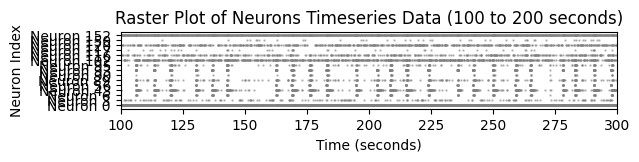

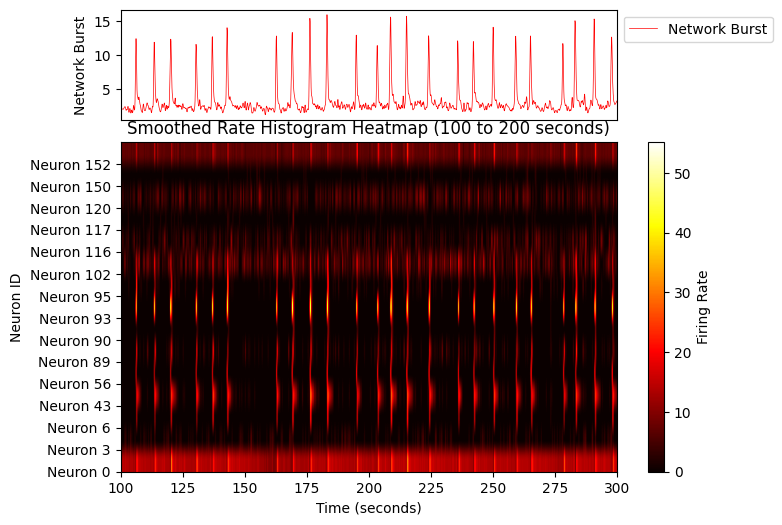


Filtered DataFrame for selected neurons:
        Group          File Name Sample_ID      Date  dpi  post_SMS unit_id  \
0    AAV-Ctrl  20240814_18389_01     18389  20240814  150        15       0   
3    AAV-Ctrl  20240814_18389_01     18389  20240814  150        15       3   
6    AAV-Ctrl  20240814_18389_01     18389  20240814  150        15       6   
43   AAV-Ctrl  20240814_18389_01     18389  20240814  150        15      43   
56   AAV-Ctrl  20240814_18389_01     18389  20240814  150        15      56   
89   AAV-Ctrl  20240814_18389_01     18389  20240814  150        15      89   
90   AAV-Ctrl  20240814_18389_01     18389  20240814  150        15      90   
93   AAV-Ctrl  20240814_18389_01     18389  20240814  150        15      93   
95   AAV-Ctrl  20240814_18389_01     18389  20240814  150        15      95   
102  AAV-Ctrl  20240814_18389_01     18389  20240814  150        15     102   
116  AAV-Ctrl  20240814_18389_01     18389  20240814  150        15     116   
117  AAV-C

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

output_pickle_path = r'D:------------\03_UnitPos_TimSerRateHist_CBZ_01.pkl.gz'
loaded_df = pd.read_pickle(output_pickle_path)

# --- Filter and Print Specific Neurons ---
sample_df = loaded_df[loaded_df['File Name'] == '20240814_18389_01']
sample_df.loc[:, 'unit_id'] = sample_df['unit_id'].astype(int) # Convert 'unit_id' column to int using .loc[] to avoid the warning
neuron_ids = [0, 3, 6, 43, 56, 89, 90, 93, 95, 102, 116, 117, 120, 150, 152]  # define list of neurons 
selected_neurons_df = sample_df[sample_df['unit_id'].isin(neuron_ids)]
time_range_start = 100  # Start of time window in seconds
time_range_end = 300    # End of time window in seconds

# Create Raster Plot ############################################################################################################
plt.figure(figsize=(6.4, 1))
point_size = 0.5  
number_of_neurons = len(neuron_ids)
for i, (index, row) in enumerate(selected_neurons_df.iterrows()):
    neuron_id = row['unit_id']
    neuron_timeseries = row['Timeseries'] 
    filtered_timeseries = [t for t in neuron_timeseries if time_range_start <= t <= time_range_end]
    plt.scatter(filtered_timeseries, [i] * len(filtered_timeseries),
                s=point_size, alpha=0.5, color='gray')  
plt.xlim([time_range_start, time_range_end])    # set axis limit
plt.title('Raster Plot of Neurons Timeseries Data (100 to 200 seconds)')
plt.xlabel('Time (seconds)')
plt.ylabel('Neuron Index')
plt.yticks(ticks=range(len(neuron_ids)), labels=[f'Neuron {nid}' for nid in neuron_ids]) # lable neuron id in y-axis
plt.show()

# --- Keep the Rate Histogram and Network Burst Plot unchanged ##################################################################
fig, (ax_burst, ax_heatmap) = plt.subplots(2, 1, figsize=(8, 6), 
                                           gridspec_kw={'height_ratios': [1, 3], 'hspace': 0.1}, 
                                           constrained_layout=False)

window_size = 3  # Define the window size for smoothing (incase it has not been done before)
rate_histo_matrix = []

# Loop through the neurons and directly use the already smoothed rate histogram data
for i, (index, row) in enumerate(selected_neurons_df.iterrows()):
    neuron_id = row['unit_id']
    rate_histo = row['Rate_Histo']  # Extract the rate histogram data (already smoothed)
    left_bins = row['Left_Bins']    # Extract the corresponding Left_Bins
    left_bins = np.array(left_bins) # Convert Left_Bins to numpy array for easier indexing
    
    # Find the indices corresponding to the time range [100, 120] seconds
    time_mask = (left_bins >= time_range_start) & (left_bins <= time_range_end)
    filtered_rate_histo = np.array(rate_histo)[time_mask]
    
    rate_histo_matrix.append(filtered_rate_histo) # No smoothing; simply add the filtered RH to the matrix


rate_histo_matrix = np.array(rate_histo_matrix) # Convert RH list to NumPy array (for heatmap plotting)

# --- Plot the Network Burst (Average Firing Rate) ---#######################################################################
# Calculate NetBurst: Average mFreq per bin across all neurons
network_burst = np.mean(rate_histo_matrix, axis=0)

# Create timepoints for the network burst that align with the heatmap x-axis
network_burst_timepoints = np.linspace(time_range_start, time_range_end, len(network_burst))

# Plot the network burst in the upper subplot
ax_burst.plot(network_burst_timepoints, network_burst, color='red', linewidth=0.5, label='Network Burst')
ax_burst.set_ylabel('Network Burst')
ax_burst.set_xlim([time_range_start, time_range_end])
ax_burst.legend(loc='upper left', bbox_to_anchor=(1, 1)) # Move the legend outside the plot
ax_burst.xaxis.set_visible(False)                        # Hide the x-axis of the upper plot to avoid clutter

# --- Plot the Heatmap in the Lower Subplot --- ###############################################################################
im = ax_heatmap.imshow(rate_histo_matrix, aspect='auto', cmap='hot', origin='lower',
                       extent=[time_range_start, time_range_end, 0, len(neuron_ids)])

ax_heatmap.set_title('Smoothed Rate Histogram Heatmap (100 to 200 seconds)')
ax_heatmap.set_xlabel('Time (seconds)')
ax_heatmap.set_ylabel('Neuron ID')
ax_heatmap.set_yticks(np.arange(len(neuron_ids)))    # Set y-ticks to show neuron IDs
ax_heatmap.set_yticklabels([f'Neuron {nid}' for nid in neuron_ids])
cbar = plt.colorbar(im, ax=ax_heatmap)               # Add a color bar
cbar.set_label('Firing Rate')

# --- Adjust Subplots to Align the x-axes ---###################################################################################
# Get the positions of both axes and make sure the x-axis widths match
pos1 = ax_burst.get_position()  # position of first subplot
pos2 = ax_heatmap.get_position()  # position of second subplot

# Align the left and right sides of both plots
ax_burst.set_position([pos2.x0, pos1.y0, pos2.width, pos1.height])  # Match the width to heatmap
ax_heatmap.set_position([pos2.x0, pos2.y0, pos2.width, pos2.height])
plt.show()

# --- Debugging: Print Filtered DataFrame for Selected Neurons ---
print("\nFiltered DataFrame for selected neurons:")
print(selected_neurons_df)

<p style="font-size: 24px; font-weight: bold; color: Black;"> 05_Plots_01_NetworkBurstPeaks, threshold line, Normalized RH and rasterplot of Ts __ Save as PDF

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.backends.backend_pdf import PdfPages  # Import PdfPages to save multiple plots in a single PDF
from scipy.signal import find_peaks, peak_widths  # Import peak finding and peak width functions

# Define the paths
output_pickle_path = r'D:------------\03_UnitPos_TimSerRateHist_CBZ_01.pkl.gz'
loaded_df = pd.read_pickle(output_pickle_path)
output_dir = r'D:------------\05Plots_01_NetBurstsRasterRH_600s_01'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

time_range_start = 0  # Start of time window in seconds
time_range_end = 600  # End of time window in seconds

# Loop through 'File Name'
for file_name in loaded_df['File Name'].unique():
    sample_df = loaded_df[loaded_df['File Name'] == file_name]      # Filter data of File Name
    sample_df.loc[:, 'unit_id'] = sample_df['unit_id'].astype(int)  # Convert 'unit_id' column to int (Warning)

    # Randomly select 300 unique unit_ids from this sample
    if len(sample_df['unit_id'].unique()) > 300:
        selected_unit_ids = np.random.choice(sample_df['unit_id'].unique(), size=300, replace=False)
    else:
        selected_unit_ids = sample_df['unit_id'].unique()  # Take all if less than 300

    # Filter the DataFrame to only include the selected neurons
    selected_neurons_df = sample_df[sample_df['unit_id'].isin(selected_unit_ids)]

    # Create a PDF file for saving both plots
    pdf_file_path = os.path.join(output_dir, f'{file_name}_combined_plots.pdf')
    with PdfPages(pdf_file_path) as pdf:  # Open a PdfPages context manager

        # --- Create Raster Plot ---############################################################################
        plt.figure(figsize=(6.4, 6))
        point_size = 0.1  
        number_of_neurons = len(selected_unit_ids)

        for i, (index, row) in enumerate(selected_neurons_df.iterrows()):
            neuron_id = row['unit_id']
            neuron_timeseries = row['Timeseries']  
            filtered_timeseries = [t for t in neuron_timeseries if time_range_start <= t <= time_range_end]
            plt.scatter(filtered_timeseries, [i] * len(filtered_timeseries),
                        s=point_size, alpha=0.1, color='gray')

        plt.xlim([time_range_start, time_range_end])
        plt.title(f'Raster Plot of Neurons Timeseries Data ({file_name})')
        plt.xlabel('Time (seconds)')
        plt.ylabel('Neuron Index')
        plt.yticks(ticks=range(number_of_neurons), labels=[f'Neuron {nid}' for nid in selected_unit_ids])

        pdf.savefig()  # Save the raster plot into the PDF
        plt.close()    # Close the figure to prevent it from displaying again

        # --- Create the Rate Histogram and Network Burst Plot ---###############################################
        fig, (ax_burst, ax_heatmap) = plt.subplots(2, 1, figsize=(8, 6),
                                                   gridspec_kw={'height_ratios': [1, 3], 'hspace': 0.1},
                                                   constrained_layout=False)

        rate_histo_matrix = []

        frequency_domain_counts = np.zeros(101)  # 0 to 100 Hz bins
        
        # Loop through the neurons and directly use the already smoothed rate histogram data
        for i, (index, row) in enumerate(selected_neurons_df.iterrows()):
            neuron_id = row['unit_id']
            rate_histo = row['Rate_Histo']  # Extract the rate histogram data
            left_bins = row['Left_Bins']    # Extract the corresponding Left_Bins
            left_bins = np.array(left_bins) # Convert Left_Bins to numpy array for easier indexing

            # Find the indices corresponding to the time range [time_range_start, time_range_end] seconds
            time_mask = (left_bins >= time_range_start) & (left_bins <= time_range_end)
            filtered_rate_histo = np.array(rate_histo)[time_mask]
            rate_histo_matrix.append(filtered_rate_histo)

            # Count the frequency bins in different ranges (0 to 100 Hz)
            for frequency in filtered_rate_histo:
                if 0 <= frequency <= 100:
                    frequency_domain_counts[int(frequency)] += 1

        total_bins = np.sum(frequency_domain_counts)    # Total number of bins for percentage calculation
        rate_histo_matrix = np.array(rate_histo_matrix) # Convert RH list to a NumPy array for heatmap plotting

        # --- Normalize Rate Histogram Data ---############################################################################
        max_value = np.nanmax(rate_histo_matrix)  # Find the maximum value across all neurons in this sample, ignoring NaNs

        # Check if max_value is greater than 0 to avoid division by zero
        if max_value > 0:
            normalized_rate_histo_matrix = rate_histo_matrix / max_value  # Normalize the matrix
        else:
            normalized_rate_histo_matrix = rate_histo_matrix / 1  # If max_value is 0, skip normalization

        # --- Detect and Measure Network Bursts---####################################################################################
        network_burst = np.mean(rate_histo_matrix, axis=0)
        network_burst_timepoints = np.linspace(time_range_start, time_range_end, len(network_burst))

        # Define the threshold
        mean_burst = np.mean(network_burst)
        std_burst = np.std(network_burst)
        threshold = (0.5/mean_burst) + (mean_burst + 1.5 * std_burst)

        # Define the minimum distance between peaks (in bins)
        min_distance = 20 
        #peak_height = 4  # set peak height as threshold value 

        # Detect peaks
        peaks, _ = find_peaks(network_burst, height=threshold, distance=min_distance)

        # Measure amplitude, width, and frequency of peaks
        peak_amplitudes = network_burst[peaks]  # Peak amplitude
        peak_widths_values, width_heights, left_ips, right_ips = peak_widths(network_burst, peaks, rel_height=0.5)
        peak_intervals = np.diff(network_burst_timepoints[peaks])  
        peak_frequencies = 1 / peak_intervals   # Convert to frequency (Hz)

        # Plot the network burst (line plot) -- #################################################################################
        ax_burst.plot(network_burst_timepoints, network_burst, color='red', linewidth=0.5, label='Network Burst')
        
        # Plot the threshold line
        ax_burst.axhline(y=threshold, color='black', linestyle='--', linewidth=1, label='Threshold')

        # Highlight the detected peaks with small gray circles and black edges
        ax_burst.scatter(network_burst_timepoints[peaks], network_burst[peaks], 
                         facecolor='gray', edgecolor='black', s=30, zorder=5, label='Detected Peaks')

        ax_burst.set_ylabel('Network Burst')
        ax_burst.set_xlim([time_range_start, time_range_end])
        ax_burst.legend(loc='upper left', bbox_to_anchor=(1, 1))
        ax_burst.xaxis.set_visible(False)

        # --- Plot the Heatmap of Normalized Data --- ################################################################
        im = ax_heatmap.imshow(normalized_rate_histo_matrix, aspect='auto', cmap='hot', origin='lower',
                               extent=[time_range_start, time_range_end, 0, len(selected_unit_ids)])

        ax_heatmap.set_title(f'Smoothed Rate Histogram Heatmap ({file_name})')
        ax_heatmap.set_xlabel('Time (seconds)')
        ax_heatmap.set_ylabel('Neuron ID')
        ax_heatmap.set_yticks(np.arange(len(selected_unit_ids)))
        ax_heatmap.set_yticklabels([f'Neuron {nid}' for nid in selected_unit_ids])

        cbar = plt.colorbar(im, ax=ax_heatmap)
        cbar.set_label('Normalized Firing Rate')

        # Align the axes
        pos1 = ax_burst.get_position()
        pos2 = ax_heatmap.get_position()

        ax_burst.set_position([pos2.x0, pos1.y0, pos2.width, pos1.height])
        ax_heatmap.set_position([pos2.x0, pos2.y0, pos2.width, pos2.height])

        # Add the current figure (rate histogram and heatmap plot) to the PDF
        pdf.savefig()  # Save the combined plot into the PDF
        plt.close()  # Close the figure to prevent it from displaying again

<p style="font-size: 24px; font-weight: bold; color: Black;"> 05_01_Plots_NetworkburstPeaks, threshold line, normalized heatmap of RH and rasterplot of Ts __ save as PNG

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from scipy.signal import find_peaks, peak_widths  # Import peak finding and peak width functions


output_pickle_path = r'D:------------\03_UnitPos_TimSerRateHist_CBZ_01.pkl.gz'
loaded_df = pd.read_pickle(output_pickle_path)
output_dir = r'D:------------\05Plots_01_NetBurstsRasterRH_600s_01'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

time_range_start = 0  # Start of time window in seconds
time_range_end = 600  # End of time window in seconds

# Loop through each unique 'File Name' in the dataframe
for file_name in loaded_df['File Name'].unique():
    sample_df = loaded_df[loaded_df['File Name'] == file_name]
    sample_df.loc[:, 'unit_id'] = sample_df['unit_id'].astype(int) # Convert 'unit_id' to integers

    # Randomly select 300 unique unit_ids from this sample
    if len(sample_df['unit_id'].unique()) > 300:
        selected_unit_ids = np.random.choice(sample_df['unit_id'].unique(), size=300, replace=False)
    else:
        selected_unit_ids = sample_df['unit_id'].unique()  # Take all if less than 300

    # Filter the DataFrame to only include the selected neurons
    selected_neurons_df = sample_df[sample_df['unit_id'].isin(selected_unit_ids)]

    # --- Create Raster Plot ---##########################################################################
    plt.figure(figsize=(6.4, 6))
    point_size = 0.1 
    number_of_neurons = len(selected_unit_ids)

    for i, (index, row) in enumerate(selected_neurons_df.iterrows()):
        neuron_id = row['unit_id']
        neuron_timeseries = row['Timeseries']  
        filtered_timeseries = [t for t in neuron_timeseries if time_range_start <= t <= time_range_end]
        plt.scatter(filtered_timeseries, [i] * len(filtered_timeseries),
                    s=point_size, alpha=0.1, color='gray')

    plt.xlim([time_range_start, time_range_end])
    plt.title(f'Raster Plot of Neurons Timeseries Data ({file_name})')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Neuron Index')
    plt.yticks(ticks=range(number_of_neurons), labels=[f'Neuron {nid}' for nid in selected_unit_ids])

    # Save the raster plot as a PNG file
    raster_plot_path = os.path.join(output_dir, f'{file_name}_raster_plot.png')
    plt.savefig(raster_plot_path, dpi=600)  # Save the raster plot
    plt.close()  # Close the figure to prevent it from displaying again

    # --- Create the Rate Histogram and Network Burst Plot ---################################################
    fig, (ax_burst, ax_heatmap) = plt.subplots(2, 1, figsize=(8, 6),
                                               gridspec_kw={'height_ratios': [1, 3], 'hspace': 0.1},
                                               constrained_layout=False)

    rate_histo_matrix = []

    # Frequency domain bin counter
    frequency_domain_counts = np.zeros(101)  # 0 to 100 Hz bins
    
    # Loop through the neurons and directly use the smoothed rate histogram data
    for i, (index, row) in enumerate(selected_neurons_df.iterrows()):
        neuron_id = row['unit_id']
        rate_histo = row['Rate_Histo']  # Extract the rate histogram data
        left_bins = row['Left_Bins']    # Extract the corresponding Left_Bins
        left_bins = np.array(left_bins) # Convert Left_Bins to numpy array for easier indexing

        # Find the indices corresponding to the time range [time_range_start, time_range_end] seconds
        time_mask = (left_bins >= time_range_start) & (left_bins <= time_range_end)
        filtered_rate_histo = np.array(rate_histo)[time_mask]

        rate_histo_matrix.append(filtered_rate_histo)

        # Count the frequency bins in different ranges (0 to 100 Hz)
        for frequency in filtered_rate_histo:
            if 0 <= frequency <= 100:
                frequency_domain_counts[int(frequency)] += 1

    # Total number of bins for percentage calculation
    total_bins = np.sum(frequency_domain_counts)

    # Convert the list of rate histograms to a NumPy array for heatmap plotting
    rate_histo_matrix = np.array(rate_histo_matrix)

    # --- Normalize Rate Histogram Data ---
    max_value = np.nanmax(rate_histo_matrix)  # Find the maximum value across all neurons in this sample, ignoring NaNs

    # Check if max_value is greater than 0 to avoid division by zero
    if max_value > 0:
        normalized_rate_histo_matrix = rate_histo_matrix / max_value  # Normalize the matrix
    else:
        normalized_rate_histo_matrix = rate_histo_matrix / 1  # If max_value is 0, skip normalization

    # --- Detect and Measure Network Bursts---####################################################################################
    network_burst = np.mean(rate_histo_matrix, axis=0)
    network_burst_timepoints = np.linspace(time_range_start, time_range_end, len(network_burst))
    
    
    # Define the threshold
    mean_burst = np.mean(network_burst)
    std_burst = np.std(network_burst)
    threshold = (0.5/mean_burst) + (mean_burst + 1.5 * std_burst)

    # Define the minimum distance between peaks (in bins)
    min_distance = 20 
    #peak_height = 4  # set peak height as threshold value 

    # Detect peaks
    peaks, _ = find_peaks(network_burst, height=threshold, distance=min_distance)

     # Measure amplitude, width, and frequency of peaks
    peak_amplitudes = network_burst[peaks]  # Peak amplitude
    peak_widths_values, width_heights, left_ips, right_ips = peak_widths(network_burst, peaks, rel_height=0.5)
    peak_intervals = np.diff(network_burst_timepoints[peaks])  # Time intervals between peaks
    peak_frequencies = 1 / peak_intervals  # Convert to frequency (Hz)

    # Plot the network burst (line plot) -- #################################################################################
    ax_burst.plot(network_burst_timepoints, network_burst, color='red', linewidth=0.5, label='Network Burst')
    
    # Plot the threshold line
    ax_burst.axhline(y=threshold, color='black', linestyle='--', linewidth=1, label='Threshold')

    # Highlight the detected peaks with small gray circles and black edges
    ax_burst.scatter(network_burst_timepoints[peaks], network_burst[peaks], 
                     facecolor='gray', edgecolor='black', s=30, zorder=5, label='Detected Peaks')

    ax_burst.set_ylabel('Network Burst')
    ax_burst.set_xlim([time_range_start, time_range_end])
    ax_burst.legend(loc='upper left', bbox_to_anchor=(1, 1))
    ax_burst.xaxis.set_visible(False)

    # --- Plot the Heatmap of Normalized Data ---###############################################################################
    im = ax_heatmap.imshow(normalized_rate_histo_matrix, aspect='auto', cmap='hot', origin='lower',
                           extent=[time_range_start, time_range_end, 0, len(selected_unit_ids)])

    ax_heatmap.set_title(f'Smoothed Rate Histogram Heatmap ({file_name})')
    ax_heatmap.set_xlabel('Time (seconds)')
    ax_heatmap.set_ylabel('Neuron ID')
    ax_heatmap.set_yticks(np.arange(len(selected_unit_ids)))
    ax_heatmap.set_yticklabels([f'Neuron {nid}' for nid in selected_unit_ids])

    cbar = plt.colorbar(im, ax=ax_heatmap)
    cbar.set_label('Normalized Firing Rate')

    # Align the axes
    pos1 = ax_burst.get_position()
    pos2 = ax_heatmap.get_position()

    ax_burst.set_position([pos2.x0, pos1.y0, pos2.width, pos1.height])
    ax_heatmap.set_position([pos2.x0, pos2.y0, pos2.width, pos2.height])

    # Save the combined plot as a PNG file
    combined_plot_path = os.path.join(output_dir, f'{file_name}_combined_plot.png')
    plt.savefig(combined_plot_path, dpi=600)  # Save the combined plot
    plt.close()  # Close the figure to prevent it from displaying again

<p style="font-size: 24px; font-weight: bold; color: Black;"> 05_01_Measure and save the NetworkBurstParams and FrequencyBandPercentages  
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- Amp,Freq,Width of peaks as list and Freq-binPercentages as Dictionary. SynchIndex as values (mean per sample) </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- Amp, Freq and width stats were saved separatly as dictionary (e.g. Mean: , SDV: ,)..</span>
</p>

In [ ]:
import pandas as pd
import numpy as np
from scipy.signal import find_peaks, peak_widths
from scipy.stats import sem  # For standard error of the mean
import xlsxwriter  # For saving to Excel

output_pickle_path = r'D:------------\03_UnitPos_TimSerRateHist_CBZ_01.pkl.gz'
output_excel_path = r'D:------------\05_01_NetworkBurstRH_MEABasedStat_01.xlsx'
loaded_df = pd.read_pickle(output_pickle_path)

time_range_start = 0
time_range_end = 600

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Sort the data based on the condition order
loaded_df['Condition'] = pd.Categorical(loaded_df['Condition'], categories=condition_order, ordered=True)
loaded_df = loaded_df.sort_values(by='Condition')

results_list = []
for condition in condition_order:
    condition_df = loaded_df[loaded_df['Condition'] == condition]
    
    for file_name in condition_df['File Name'].unique():
        sample_df = condition_df[condition_df['File Name'] == file_name]
        group = sample_df['Group'].iloc[0]
        sample_id = sample_df['Sample_ID'].iloc[0]
        date = sample_df['Date'].iloc[0]
        condition = sample_df['Condition'].iloc[0]
        post_sms = sample_df['post_SMS'].iloc[0]
        
        # Process rate histograms and calculate network burst
        rate_histo_matrix = []
        for i, row in sample_df.iterrows():
            rate_histo = np.array(row['Rate_Histo'])
            left_bins = np.array(row['Left_Bins'])
            
            time_mask = (left_bins >= time_range_start) & (left_bins <= time_range_end)
            filtered_rate_histo = rate_histo[time_mask]
            rate_histo_matrix.append(filtered_rate_histo)
        
        rate_histo_matrix = np.array(rate_histo_matrix)
        
        # --- Network Burst Analysis ---#####################################################################
        network_burst = np.mean(rate_histo_matrix, axis=0)
        
        # Define the threshold
        mean_burst = np.mean(network_burst)
        std_burst = np.std(network_burst)
        threshold = (0.5/mean_burst) + (mean_burst + 1.5 * std_burst)

        # Define the minimum distance between peaks (in bins)
        min_distance = 20 
        #peak_height = 4  # set peak height as threshold value 

        # Detect peaks
        peaks, _ = find_peaks(network_burst, height=threshold, distance=min_distance)
        
        # Measure peak amplitude, width, and frequency
        peak_amplitudes = network_burst[peaks]
        peak_widths_result = peak_widths(network_burst, peaks, rel_height=0.5)[0] * 0.1  # Convert to seconds
        if len(peaks) > 1:
            peak_intervals = np.diff(peaks)
            peak_frequencies = 1 / (peak_intervals * 0.1)  # Convert intervals to Hz
        else:
            peak_frequencies = np.array([])

        # --- Statistical Summary for Peaks ---
        def calculate_stats(data):
            return {
                'Mean': np.mean(data),
                'SD': np.std(data),
                'SEM': sem(data) if len(data) > 1 else None,
                'Max': np.max(data),
                'Min': np.min(data),
                'Median': np.median(data)
            }
        
        # Statistics for peak amplitudes, frequencies, and widths
        peak_amplitude_stats = calculate_stats(peak_amplitudes) if len(peak_amplitudes) > 0 else {}
        peak_frequency_stats = calculate_stats(peak_frequencies) if len(peak_frequencies) > 0 else {}
        peak_width_stats = calculate_stats(peak_widths_result) if len(peak_widths_result) > 0 else {}

        # --- Frequency Domain Analysis ---
        frequency_domain_counts = np.zeros(101)  # 0 to 100 Hz
        total_bins = 0
        
        # Calculate the counts and percentages for each frequency domain
        for neuron_rates in rate_histo_matrix:
            for rate in neuron_rates:
                if 0 <= rate <= 100:
                    frequency_domain_counts[int(rate)] += 1
            total_bins += len(neuron_rates)
        
        # Calculate percentages
        frequency_percentages = [(count / total_bins) * 100 if total_bins > 0 else 0 for count in frequency_domain_counts]
        frequency_dict = {f'{i}Hz': f'{percentage:.2f}%' for i, percentage in enumerate(frequency_percentages)}
        
        # --- Synchronicity Index ---
        # Compute correlation matrix for rate histogram across neurons
        # Calculate Synchronicity Index
        if rate_histo_matrix.shape[0] > 1:  # Only if there’s more than one neuron
            # Remove constant rows (neurons with zero variance)
            variable_neurons = rate_histo_matrix[np.std(rate_histo_matrix, axis=1) > 0]
            
            # Calculate correlation matrix if there are variable neurons
            if variable_neurons.shape[0] > 1:
                correlation_matrix = np.corrcoef(variable_neurons)
                # Replace NaNs with 0 (or another value if preferred)
                np.nan_to_num(correlation_matrix, copy=False)
                upper_triangle_indices = np.triu_indices_from(correlation_matrix, k=1)
                synchronicity_index = np.mean(correlation_matrix[upper_triangle_indices])
            else:
                synchronicity_index = None  # No variable neurons to compare
        else:
            synchronicity_index = None

        # Store the results for this sample in a list
        results_list.append({
            'Group': group,
            'File Name': file_name,
            'Sample_ID': sample_id,
            'Date': date,
            'Condition': condition,
            'post_SMS': post_sms,
            'Num_Peaks': len(peaks),
            'Peak_Amplitudes': peak_amplitudes.tolist(),
            'Peak_Amplitude_Stats': peak_amplitude_stats,
            'Peak_Frequencies': peak_frequencies.tolist(),
            'Peak_Frequency_Stats': peak_frequency_stats,
            'Peak_Widths': peak_widths_result.tolist(),
            'Peak_Width_Stats': peak_width_stats,
            'Synchronicity_Index': synchronicity_index,  # Store synchronicity index for each sample
            'Freq_Domain_Percentages': frequency_dict 
        })

# Convert the list of results into a DataFrame
results_df = pd.DataFrame(results_list)

# Save the DataFrame to an Excel file
results_df.to_excel(output_excel_path, index=False)
print(f'Summary saved to {output_excel_path}')

Summary saved to D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\05_01_NetworkBurstRH_MEABasedStat_01.xlsx


<p style="font-size: 24px; font-weight: bold; color: Black;"> 05Plots_03_NetworkBurstParameters (Group-Condition_based plots) raw data  CBZ01

c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_8732\4065808880.py:34: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = df.groupby(['Group', 'Condition']).agg({


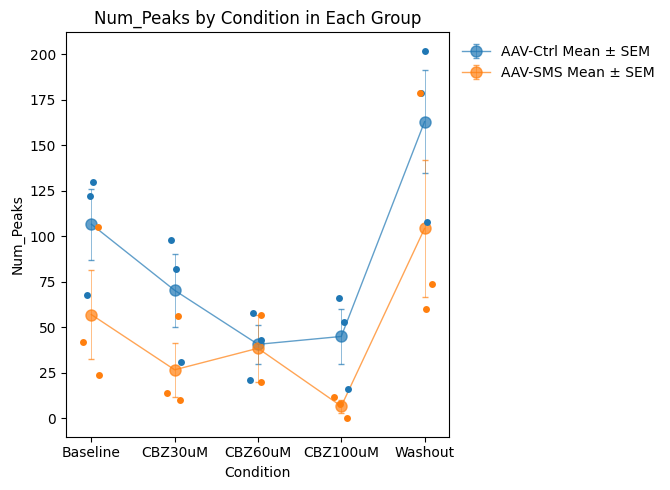

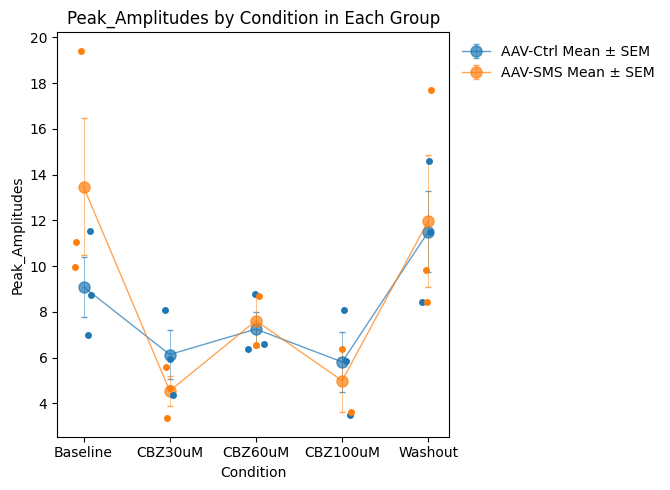

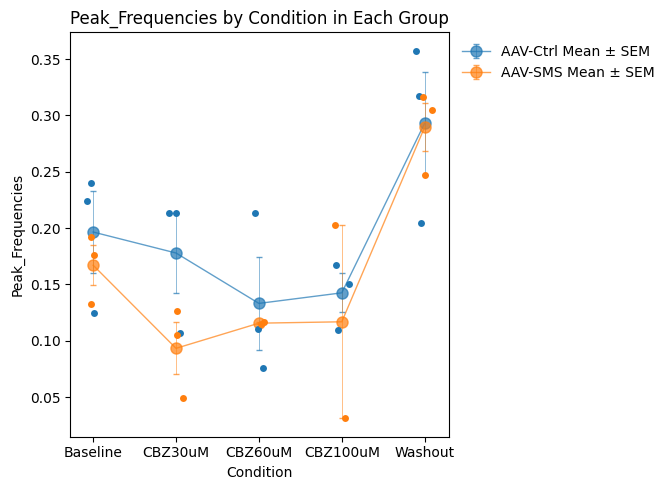

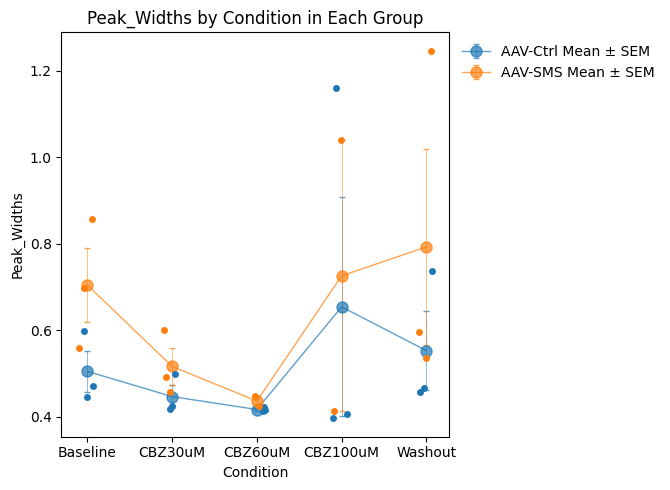

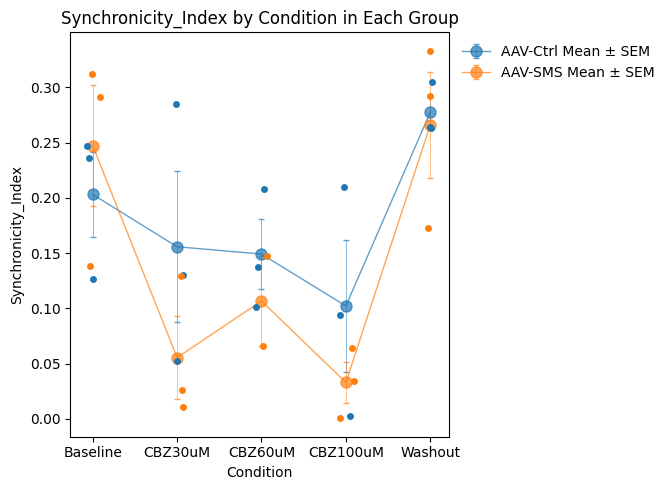

All plots have been saved individually as PDFs.


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import sem  # For calculating SEM
from matplotlib.backends.backend_pdf import PdfPages  # To save plots as PDF

# Load the processed Excel data
file_path = r'D:------------\05_01_NetworkBurstRH_MEABasedStat_01.xlsx'
df = pd.read_excel(file_path)

# Define the directory for saving individual PDF files for each variable
output_dir = r'D:------------\05Plots_03_NetworkBurstParams_01'
os.makedirs(output_dir, exist_ok=True)  # Create the directory if it doesn't exist

# 1. Exclude data of Sample_ID = 18574
df = df[df['Sample_ID'] != 18574]

# List of variables to analyze and plot
variables = ['Num_Peaks', 'Peak_Amplitudes', 'Peak_Frequencies', 'Peak_Widths', 'Synchronicity_Index']

# Pre-process data: 
for var in variables:
    df[var] = df[var].apply(lambda x: np.mean(eval(x)) if isinstance(x, str) and x.startswith('[') else x)

# Define the order of conditions to plot
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Ensure the 'Condition' column is treated as a categorical variable with the specified order
df['Condition'] = pd.Categorical(df['Condition'], categories=condition_order, ordered=True)

# Group data by 'Group' and 'Condition' to calculate means and SEMs
grouped_data = df.groupby(['Group', 'Condition']).agg({
    'Num_Peaks': ['mean', 'sem', 'count'],
    'Peak_Amplitudes': ['mean', 'sem', 'count'],
    'Peak_Frequencies': ['mean', 'sem', 'count'],
    'Peak_Widths': ['mean', 'sem', 'count'],
    'Synchronicity_Index': ['mean', 'sem', 'count']
}).reset_index()

# Flatten the multi-level columns in grouped_data for easier access
grouped_data.columns = ['Group', 'Condition'] + [f'{var}_{stat}' for var, stat in grouped_data.columns[2:]]

# Colors for groups
colors = {
    'AAV-Ctrl': '#1f77b4',  # Hex color for blue (similar to Matplotlib's blue)
    'AAV-SMS': '#ff7f0e'     # Hex color for orange (similar to Matplotlib's orange)
}

# Ensure that the 'Condition' column is treated as a categorical variable
grouped_data['Condition'] = grouped_data['Condition'].astype(str)  # Ensure grouped data 'Condition' is a string

# Plot each variable and save as individual PDF
for var in variables:
    fig, ax = plt.subplots(figsize=(8, 5))

    for group in df['Group'].unique():
        # Filter data for the specific group
        group_data = df[df['Group'] == group]

        # Plot individual data points
        sns.stripplot(data=group_data, x='Condition', y=var, color=colors[group], jitter=True, ax=ax)

        # Plot mean and SEM with customization
        group_means = grouped_data[grouped_data['Group'] == group]
        ax.errorbar(group_means['Condition'], group_means[f'{var}_mean'], 
                    yerr=group_means[f'{var}_sem'], fmt='-o', 
                    color=colors[group], label=f'{group} Mean ± SEM', 
                    linewidth=1,
                    markersize=8,  # Increase size of mean circles
                    capsize=2,     # Remove caps
                    elinewidth=0.5,  # Set the thickness of error bars
                    alpha=0.7)     # Set transparency of error bars

    # Customize plot
    ax.set_title(f'{var} by Condition in Each Group')
    ax.set_xlabel('Condition')
    ax.set_ylabel(var)

    # Set legend outside of the plot
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False)  # Place legend outside

    plt.tight_layout(rect=[0, 0, 0.85, 1])  # Adjust layout to make room for legend

    # Save each figure to an individual PDF
    pdf_path = os.path.join(output_dir, f"{var}_RawData_Plots.pdf")
    with PdfPages(pdf_path) as pdf:
        pdf.savefig(fig)
    
    # Show the plot
    plt.show()
    plt.close(fig)  # Close the figure after saving to free up memory

print("All plots have been saved individually as PDFs.")


<p style="font-size: 24px; font-weight: bold; color: Green;"> Selected Conditions 05Plots_03_NetworkBurstParameters (Group-Condition_based plots) raw data  CBZ01

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import sem

# Load the processed Excel data
file_path = r'D:------------\05_01_NetworkBurstRH_MEABasedStat_01.xlsx'
final_df = pd.read_excel(file_path)

# Define the directory for saving individual PDF files for each variable
output_dir = r'D:------------\0000_SelectedConditions\Selected_05Plots_03_MEABasedNetBurst_01'
os.makedirs(output_dir, exist_ok=True)  # Create the directory if it doesn't exist

# Define the output Excel file path for saving summary statistics
output_stats_path = os.path.join(output_dir, 'Selected_MEABasedNetBurst_Summary.xlsx')

# Exclude data of Sample_ID = 18574 and unwanted conditions
df = final_df[(final_df['Sample_ID'] != 18574) & (final_df['Condition'] != 'CBZ60uM') & (final_df['Condition'] != 'Washout')]

# List of variables to analyze and plot
variables = ['Num_Peaks', 'Peak_Amplitudes', 'Peak_Frequencies', 'Peak_Widths', 'Synchronicity_Index']

# Pre-process data to ensure correct handling of list-like values
for var in variables:
    df[var] = df[var].apply(lambda x: np.mean(eval(x)) if isinstance(x, str) and x.startswith('[') else x)

# Define the order of conditions to plot
condition_order = ['Baseline', 'CBZ30uM', 'CBZ100uM']

# Ensure the 'Condition' column is treated as a categorical variable with the specified order
df['Condition'] = pd.Categorical(df['Condition'], categories=condition_order, ordered=True)

# Group data by 'Condition' and 'Sample_ID' to calculate mean for export
excel_data = {}

# Colors for groups
group_colors = {
    'AAV-Ctrl': '#1f77b4',  # Blue
    'AAV-SMS': '#ff7f0e'     # Orange
}

# Plot each variable and save as individual PDF
for var in variables:
    fig, ax = plt.subplots(figsize=(4, 6))  # Adjusted figure size

    # Dictionary to store data for this variable
    variable_data = []

    for group_idx, group in enumerate(df['Group'].unique()):
        # Filter data for the specific group
        group_data = df[df['Group'] == group]
        
        # Get the color for the current group
        color = group_colors.get(group, 'black')

        # Prepare the boxplot data
        boxplot_data = [
            group_data[group_data['Condition'] == condition].groupby('Sample_ID')[var].mean()
            for condition in condition_order
        ]

        # Handle missing or empty data by setting missing values to 0
        for i, condition_data in enumerate(boxplot_data):
            # Replace NaN values with 0
            boxplot_data[i] = condition_data.fillna(0)  # Replace NaN with 0 for plotting

        x_positions = np.arange(len(condition_order)) + 0.25 * group_idx  # Offset by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.25,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.7, alpha=0.7),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.7),
            capprops=dict(color='black', linewidth=0.7),
            flierprops=dict(marker='o', color=color, markersize=0, alpha=0.5),
            zorder=1
        )

        # Plot mean and SEM with offset to prevent overlap
        means = [np.mean(condition_data) for condition_data in boxplot_data]
        sems = [sem(condition_data) if len(condition_data) > 1 else 0 for condition_data in boxplot_data]

        ax.errorbar(
            np.arange(len(condition_order)) + 0.25 * group_idx,
            means,
            #yerr=sems,
            fmt='-o',  # Line with markers
            color=color,
            label=f'{group} Mean',  # Updated legend label
            linewidth=1.5,
            markersize=8,
            markeredgecolor='black',  # Add a border to markers
            alpha=0.9  # Transparency for better visibility
        )

        # Plot scatter points with jittering
        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            ax.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                       alpha=0.9, linewidth=0.5, zorder=3, s=40)

        # Add stats for export
        for condition, sample_data in zip(condition_order, boxplot_data):
            for sample_id, mean_val in sample_data.items():
                # If the mean value is NaN or empty, set it to 0
                if np.isnan(mean_val) or mean_val == 0:
                    mean_val = 0
                variable_data.append({
                    'Group': group,
                    'Condition': condition,
                    'Sample_ID': sample_id,
                    'Mean': mean_val
                })

    # Save data for the current variable to the Excel export dictionary
    excel_data[var] = pd.DataFrame(variable_data)

    # Title with custom font and size
    plt.title(f'{var} across Conditions', 
              fontdict={'fontsize': 14, 'fontweight': 'bold', 'family': 'serif'})  # Customize title font

    # X-axis label with custom font and size
    plt.xlabel('Condition', fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})  # Customize x-label font

    # Y-axis label with custom font and size
    plt.ylabel(var, fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})  # Customize y-label font

    # Legend with adjusted font size
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=14, title_fontsize=14)

    # X-ticks with custom font size
    plt.xticks(ticks=np.arange(len(condition_order)), labels=condition_order, fontsize=14)  # Customize x-tick font size

    # Save the plot
    plot_output_path = os.path.join(output_dir, f'{var}_Boxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()  # Close the plot to free memory

# Save each variable's data to a separate sheet in the Excel file
with pd.ExcelWriter(output_stats_path, engine='openpyxl') as writer:
    for variable, data in excel_data.items():
        data.to_excel(writer, index=False, sheet_name=variable)

print(f"All plots have been saved as PDFs, and summary statistics have been exported to {output_stats_path}.")




C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_8732\320824890.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[var] = df[var].apply(lambda x: np.mean(eval(x)) if isinstance(x, str) and x.startswith('[') else x)
c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_8732\320824890.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .

All plots have been saved as PDFs, and summary statistics have been exported to D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\0000_SelectedConditions\Selected_05Plots_03_MEABasedNetBurst_01\Selected_MEABasedNetBurst_Summary.xlsx.


<p style="font-size: 24px; font-weight: bold; color: Black;"> 05Plots_04_Normalized_NetworkBurstParameters (Group-Condition_based plots) Normalized data  CBZ01
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- Saves Normalized variables together with original dataset in new excel file   05_NetBurstRH_01 </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: red;">- Consider that the original data lists in 03_NetBurstRH_01 has become values in 05_NetBurstRH_01  for each sample </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: red;">- This data can be used for Prism because for all variables it has values (mean of the sample) --> 05_NetBurstRH_01 </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- Will be used from now on to plot normalized and original data</span>
</p>

c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_8732\2532944928.py:59: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = df.groupby(['Group', 'Condition']).agg({


Combined original and normalized data saved to: D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\05_04_NormNetworkBurstRH_MEABasedStat_01.xlsx


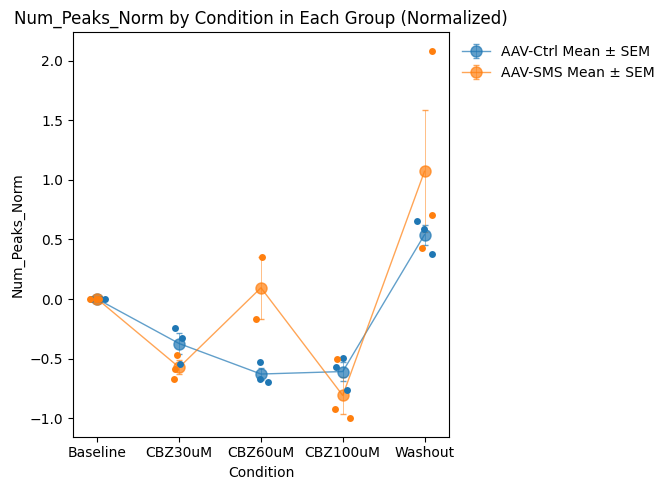

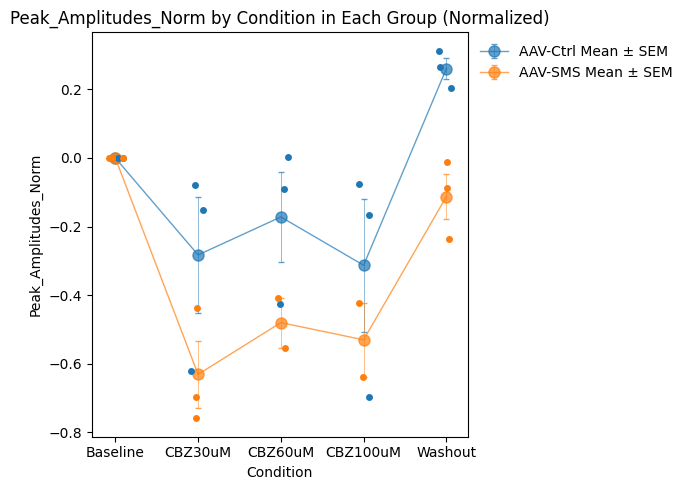

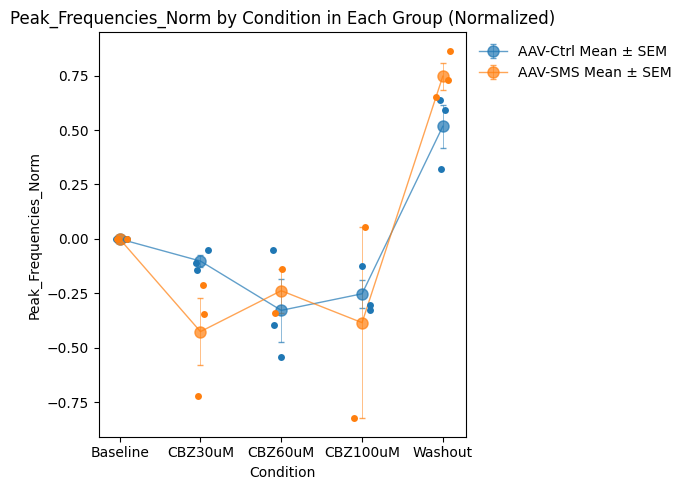

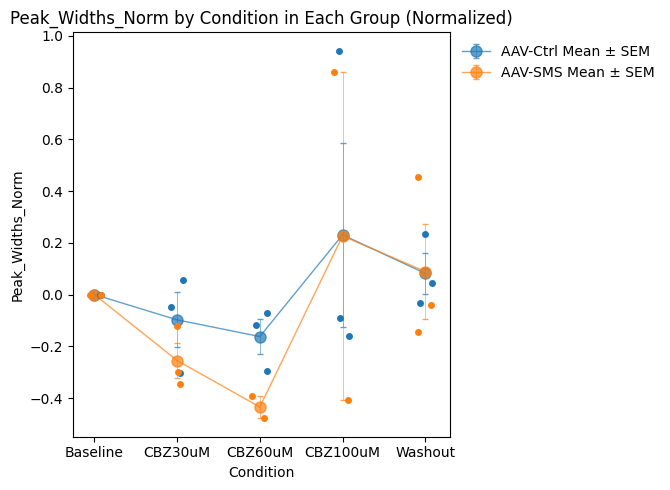

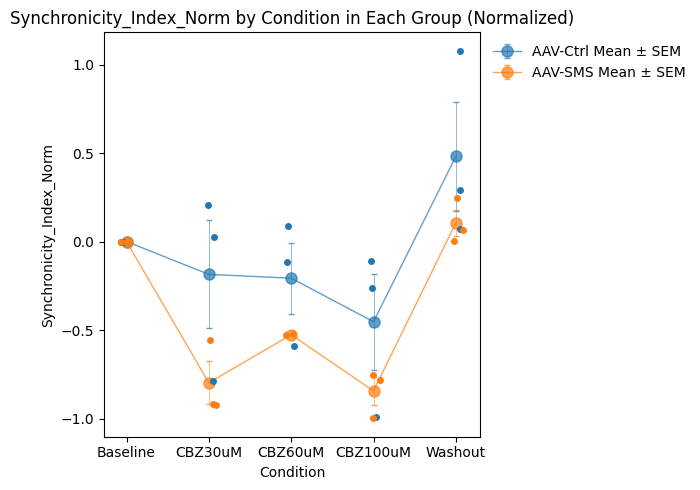

All normalized plots have been saved individually as PDFs.


In [ ]:
import os 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import sem  # For calculating SEM
from matplotlib.backends.backend_pdf import PdfPages  # To save plots as PDF

# Load the processed Excel data
file_path = r'D:------------\05_01_NetworkBurstRH_MEABasedStat_01.xlsx'
df = pd.read_excel(file_path)

# Define output directory for individual PDF files for each variable
output_dir = r'D:------------\05Plots_04_NormNetworkBurstParams_01'
os.makedirs(output_dir, exist_ok=True)  # Create directory if it doesn't exist

# Exclude data of Sample_ID = 18574
df = df[df['Sample_ID'] != 18574]

# List of variables to analyze and plot
variables = ['Num_Peaks', 'Peak_Amplitudes', 'Peak_Frequencies', 'Peak_Widths', 'Synchronicity_Index']

# Pre-process data: Convert lists to mean values
for var in variables:
    df[var] = df[var].apply(lambda x: np.mean(eval(x)) if isinstance(x, str) and x.startswith('[') else x)

# Convert columns to float to avoid dtype incompatibility warnings
for var in variables:
    df[var] = df[var].astype(float)

# Define the order of conditions to plot
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Ensure the 'Condition' column is treated as a categorical variable with the specified order
df['Condition'] = pd.Categorical(df['Condition'], categories=condition_order, ordered=True)

# Create new columns for normalized values with suffix '_Norm'
for var in variables:
    df[f"{var}_Norm"] = np.nan  # Initialize normalized columns with NaN values

# Normalize the data to the value at 'Baseline' condition for each sample
for sample_id in df['Sample_ID'].unique():
    sample_data = df[df['Sample_ID'] == sample_id]
    value_at_baseline = sample_data[sample_data['Condition'] == 'Baseline'][variables].replace(0, 0.001)  # Replace zero values to avoid division by zero

    for var in variables:
        if not value_at_baseline.empty:
            # Calculate normalized values to Baseline condition
            norm_values = (sample_data[var].values - value_at_baseline[var].values[0]) / value_at_baseline[var].values[0]
            # Assign normalized values to the corresponding rows in the new columns
            df.loc[df['Sample_ID'] == sample_id, f"{var}_Norm"] = norm_values

# Save the modified data with original and normalized columns to a new Excel file
output_excel_path = r'D:------------05_04_NormNetworkBurstRH_MEABasedStat_01.xlsx'
df.to_excel(output_excel_path, index=False)
print(f"Combined original and normalized data saved to: {output_excel_path}")

# Group data by 'Group' and 'Condition' to calculate means and SEMs for normalized data
grouped_data = df.groupby(['Group', 'Condition']).agg({
    'Num_Peaks_Norm': ['mean', 'sem', 'count'],
    'Peak_Amplitudes_Norm': ['mean', 'sem', 'count'],
    'Peak_Frequencies_Norm': ['mean', 'sem', 'count'],
    'Peak_Widths_Norm': ['mean', 'sem', 'count'],
    'Synchronicity_Index_Norm': ['mean', 'sem', 'count']
}).reset_index()

# Flatten the multi-level columns in grouped_data for easier access
grouped_data.columns = ['Group', 'Condition'] + [f'{var}_{stat}' for var, stat in grouped_data.columns[2:]]

# Colors for groups
colors = {
    'AAV-Ctrl': '#1f77b4',  # Hex color for blue (similar to Matplotlib's blue)
    'AAV-SMS': '#ff7f0e'     # Hex color for orange (similar to Matplotlib's orange)
}

# Plotting each normalized variable and saving as individual PDFs
for var in [f"{v}_Norm" for v in variables]:
    fig, ax = plt.subplots(figsize=(8, 5))

    for group in df['Group'].unique():
        group_data = df[df['Group'] == group]

        # Plot individual normalized data points
        sns.stripplot(data=group_data, x='Condition', y=var, color=colors[group], jitter=True, ax=ax)

        # Plot mean and SEM for normalized values with customization
        group_means = grouped_data[grouped_data['Group'] == group]
        ax.errorbar(group_means['Condition'], group_means[f'{var}_mean'], 
                    yerr=group_means[f'{var}_sem'], fmt='-o', 
                    color=colors[group], label=f'{group} Mean ± SEM', 
                    linewidth=1,
                    markersize=8,
                    capsize=2,
                    elinewidth=0.5,
                    alpha=0.7)

    # Customize plot
    ax.set_title(f'{var} by Condition in Each Group (Normalized)')
    ax.set_xlabel('Condition')
    ax.set_ylabel(var)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1), frameon=False)

    plt.tight_layout(rect=[0, 0, 0.85, 1])  # Adjust layout to make room for legend

    # Save each figure to an individual PDF
    pdf_path = os.path.join(output_dir, f"{var}_Plot.pdf")
    with PdfPages(pdf_path) as pdf:
        pdf.savefig(fig)
    
    # Show the plot
    plt.show()
    plt.close(fig)  # Close the figure after saving to free up memory

print("All normalized plots have been saved individually as PDFs.")


<p style="font-size: 24px; font-weight: bold; color: Green;"> Normalized ___ Selected Conditions 05Plots_03_NetworkBurstParameters (Group-Condition_based plots) Normalized data  CBZ01

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import sem

# Load the processed Excel data
file_path = r'D:------------1\05_01_NetworkBurstRH_MEABasedStat_01.xlsx'
final_df = pd.read_excel(file_path)

# Define the directory for saving individual PDF files for each variable
output_dir = r'D:------------\Selected_05Plots_03_MEABasedNetBurst_01'
os.makedirs(output_dir, exist_ok=True)  # Create the directory if it doesn't exist

# Define the output Excel file path for saving summary statistics
output_stats_path = os.path.join(output_dir, 'Selected_NormMEABasedNetBurst_Summary.xlsx')

# Exclude data of Sample_ID = 18574 and unwanted conditions
df = final_df[(final_df['Sample_ID'] != 18574) & (final_df['Condition'] != 'CBZ60uM') & (final_df['Condition'] != 'Washout')]

# List of variables to analyze and plot
variables = ['Num_Peaks', 'Peak_Amplitudes', 'Peak_Frequencies', 'Peak_Widths', 'Synchronicity_Index']

# Pre-process data to ensure correct handling of list-like values
for var in variables:
    df[var] = df[var].apply(lambda x: np.mean(eval(x)) if isinstance(x, str) and x.startswith('[') else x)

# Define the order of conditions to plot
condition_order = ['Baseline', 'CBZ30uM', 'CBZ100uM']

# Ensure the 'Condition' column is treated as a categorical variable with the specified order
df['Condition'] = pd.Categorical(df['Condition'], categories=condition_order, ordered=True)

# Group data by 'Condition' and 'Sample_ID' to calculate mean for export
excel_data = {}

# Colors for groups
group_colors = {
    'AAV-Ctrl': '#1f77b4',  # Blue
    'AAV-SMS': '#ff7f0e'     # Orange
}

# Plot each variable and save as individual PDF
for var in variables:
    fig, ax = plt.subplots(figsize=(4, 6))  # Adjusted figure size

    # Dictionary to store data for this variable
    variable_data = []

    for group_idx, group in enumerate(df['Group'].unique()):
        # Filter data for the specific group
        group_data = df[df['Group'] == group]
        
        # Get the color for the current group
        color = group_colors.get(group, 'black')

        # Prepare the boxplot data
        boxplot_data = [
            group_data[group_data['Condition'] == condition].groupby('Sample_ID')[var].mean()
            for condition in condition_order
        ]

        # Handle missing or empty data by setting missing values to 0
        for i, condition_data in enumerate(boxplot_data):
            if condition_data.empty:
                boxplot_data[i] = pd.Series([0] * len(group_data['Sample_ID'].unique()), index=group_data['Sample_ID'].unique())
            else:
                # Replace NaN values with 0 for plotting
                boxplot_data[i] = boxplot_data[i].fillna(0)

        # Normalize values based on Baseline condition for each Sample_ID
        baseline_means = boxplot_data[0]  # Baseline data for each Sample_ID

        for i in range(0, len(boxplot_data)):  # Loop over other conditions
            boxplot_data[i] = ((boxplot_data[i] - baseline_means) / baseline_means) * 100  # Normalize
            # Replace NaN after normalization with 0
            boxplot_data[i] = boxplot_data[i].fillna(0)

        print(boxplot_data)

        # Plot the boxplots
        x_positions = np.arange(len(condition_order)) + 0.25 * group_idx  # Offset by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.25,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.7, alpha=0.7),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.7),
            capprops=dict(color='black', linewidth=0.7),
            flierprops=dict(marker='o', color=color, markersize=0, alpha=0.5),
            zorder=1
        )

        # Plot mean and SEM with offset to prevent overlap
        means = [np.mean(condition_data) for condition_data in boxplot_data]
        sems = [sem(condition_data) if len(condition_data) > 1 else 0 for condition_data in boxplot_data]

        ax.errorbar(
            np.arange(len(condition_order)) + 0.25 * group_idx,
            means,
            # yerr=sems,
            fmt='-o',  # Line with markers
            color=color,
            label=f'{group} Mean',  # Updated legend label
            linewidth=1.5,
            markersize=8,
            markeredgecolor='black',  # Add a border to markers
            alpha=0.9  # Transparency for better visibility
        )

        # Plot scatter points with jittering
        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            ax.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                       alpha=0.9, linewidth=0.5, zorder=3, s=40)

        # Add stats for export
        for condition, sample_data in zip(condition_order, boxplot_data):
            for sample_id, mean_val in sample_data.items():
                # Replace NaN values with 0 for export
                mean_val = 0 if np.isnan(mean_val) else mean_val
                variable_data.append({
                    'Group': group,
                    'Condition': condition,
                    'Sample_ID': sample_id,
                    'Mean': mean_val
                })

    # Save data for the current variable to the Excel export dictionary
    excel_data[var] = pd.DataFrame(variable_data)

    # Title with custom font and size
    plt.title(f'{var} across Conditions (Normalized)', 
              fontdict={'fontsize': 14, 'fontweight': 'bold', 'family': 'serif'})  # Customize title font

    # X-axis label with custom font and size
    plt.xlabel('Condition', fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})  # Customize x-label font

    # Y-axis label with custom font and size
    plt.ylabel(f'Normalized {var}', fontdict={'fontsize': 14, 'fontweight': 'medium', 'family': 'sans-serif'})  # Customize y-label font

    # Legend with adjusted font size
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=14, title_fontsize=14)

    # X-ticks with custom font size
    plt.xticks(ticks=np.arange(len(condition_order)), labels=condition_order, fontsize=14)  # Customize x-tick font size

    # Save the plot
    plot_output_path = os.path.join(output_dir, f'{var}_Normalized_Boxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()  # Close the plot to free memory

# Save each variable's data to a separate sheet in the Excel file
with pd.ExcelWriter(output_stats_path, engine='openpyxl') as writer:
    for variable, data in excel_data.items():
        data.to_excel(writer, index=False, sheet_name=variable)

print(f"All plots have been saved as PDFs, and summary statistics have been exported to {output_stats_path}.")




C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_8732\816444964.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[var] = df[var].apply(lambda x: np.mean(eval(x)) if isinstance(x, str) and x.startswith('[') else x)
c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_8732\816444964.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .

[Sample_ID
18389    0.0
18505    0.0
20810    0.0
Name: Num_Peaks, dtype: float64, Sample_ID
18389   -54.411765
18505   -32.786885
20810   -24.615385
Name: Num_Peaks, dtype: float64, Sample_ID
18389   -76.470588
18505   -56.557377
20810   -49.230769
Name: Num_Peaks, dtype: float64]
[Sample_ID
18406    0.0
18412    0.0
18581    0.0
Name: Num_Peaks, dtype: float64, Sample_ID
18406   -46.666667
18412   -66.666667
18581   -58.333333
Name: Num_Peaks, dtype: float64, Sample_ID
18406    -92.380952
18412   -100.000000
18581    -50.000000
Name: Num_Peaks, dtype: float64]
[Sample_ID
18389    0.0
18505    0.0
20810    0.0
Name: Peak_Amplitudes, dtype: float64, Sample_ID
18389   -61.944378
18505   -15.094451
20810    -7.760723
Name: Peak_Amplitudes, dtype: float64, Sample_ID
18389   -69.555206
18505   -16.665506
20810    -7.586775
Name: Peak_Amplitudes, dtype: float64]
[Sample_ID
18406    0.0
18412    0.0
18581    0.0
Name: Peak_Amplitudes, dtype: float64, Sample_ID
18406   -43.656189
18412   -75.

<p style="font-size: 24px; font-weight: bold; color: Black;"> 05Plots_05_Conditionbased_FreqDomains   
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- One plot for each Condition in two groups </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- uses the already calculated percentages of bins with specific freq in excel file </span>
</p>

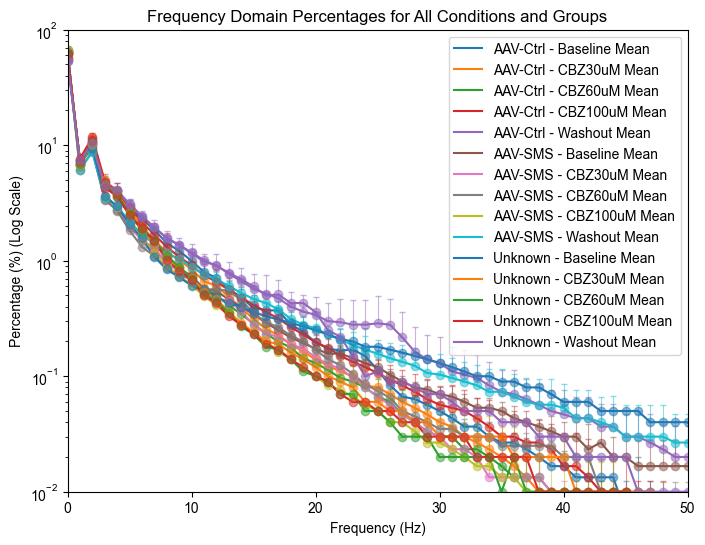

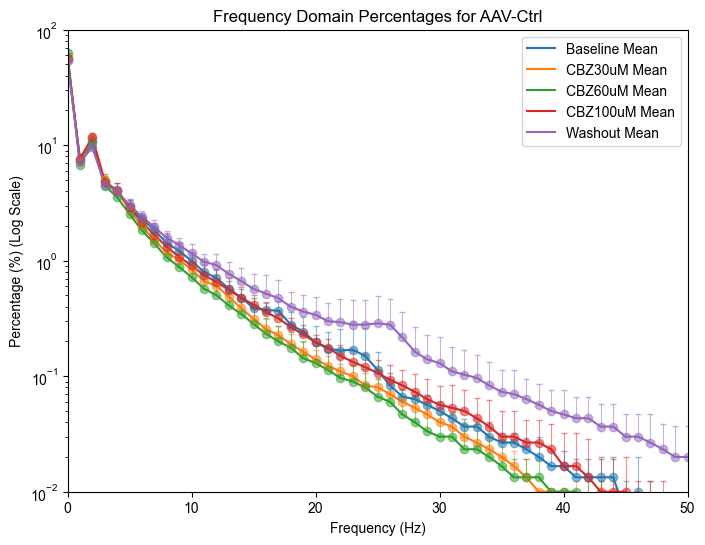

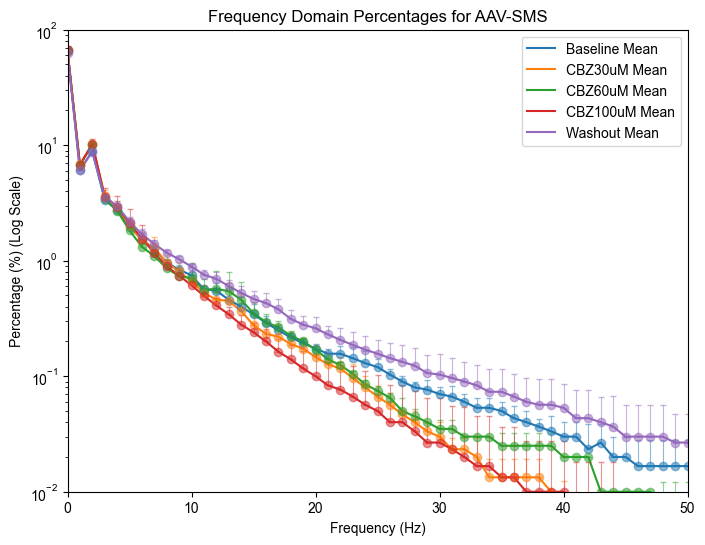

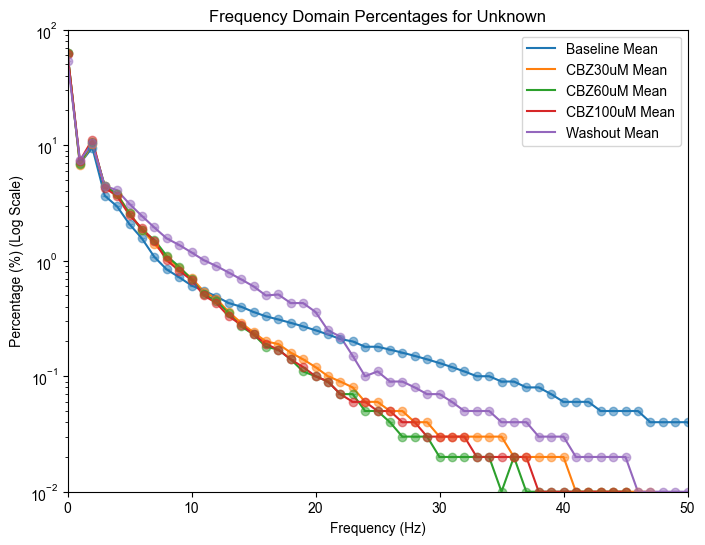

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Set font settings to avoid LaTeX-related warnings
plt.rcParams['text.usetex'] = False  # Disable LaTeX rendering
plt.rcParams['font.family'] = 'Arial'  # Use Arial or any other standard font

# Load your summarized data (assuming it's saved in the Excel file)
output_excel_path = r'D:------------\05_01_NetworkBurstRH_MEABasedStat_01.xlsx'
results_df = pd.read_excel(output_excel_path)

# Directory to save plots
output_dir = r'D:------------05Plots_05_FreqDomainsConditions'
os.makedirs(output_dir, exist_ok=True)

# Step 1: Process `Freq_Domain_Percentages` dictionary for each sample to create a new DataFrame
freq_data = []

for idx, row in results_df.iterrows():
    group = row['Group']
    condition = row['Condition']  # Use Condition instead of dpi
    freq_domain_dict = eval(row['Freq_Domain_Percentages'])  # Ensure dictionary format
    freq_data.append({'Group': group, 'Condition': condition, **{int(k.strip('Hz')): float(v.strip('%')) for k, v in freq_domain_dict.items()}})

freq_df = pd.DataFrame(freq_data)

# Step 2: Group by `Group` and `Condition`, calculate mean and std for each frequency
summary_df = freq_df.groupby(['Group', 'Condition']).agg(['mean', 'std']).reset_index()

# Set fixed y-axis limits for log scale
y_min, y_max = 0.01, 100  # Adjust based on data range for better visualization
x_min, x_max = 0.0, 50 

# Step 3: Plotting for all groups in one plot and separate plots for each group
# Define the order of conditions to plot
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Ensure the 'Condition' column is treated as a categorical variable with the specified order
freq_df['Condition'] = pd.Categorical(freq_df['Condition'], categories=condition_order, ordered=True)

# Create one figure for all conditions and groups
plt.figure(figsize=(8, 6))

# Plot all conditions and groups in one plot
for group in summary_df['Group'].unique():
    group_df = summary_df[summary_df['Group'] == group]
    
    # Extract means and stds for all frequencies
    freqs = range(101)
    
    # Plot mean and std values for each condition
    for condition in condition_order:
        condition_df = group_df[group_df['Condition'] == condition]
        
        # Extract the mean and std for the current condition
        mean_percentages = condition_df.iloc[:, condition_df.columns.get_level_values(1) == 'mean'].values.flatten()
        std_percentages = condition_df.iloc[:, condition_df.columns.get_level_values(1) == 'std'].values.flatten()
        
        # Plot mean line
        mean_line, = plt.plot(freqs, mean_percentages, label=f'{group} - {condition} Mean')

        # Define yerr to show only the positive error bar side
        yerr = np.array([np.zeros_like(std_percentages), std_percentages])

        # Plot positive error bars only
        plt.errorbar(
            freqs, mean_percentages, yerr=yerr, fmt='o', 
            color=mean_line.get_color(), alpha=0.5, elinewidth=0.8, capsize=2
        )

# Set y-axis to logarithmic scale and fix limits
plt.yscale('log')
plt.ylim(y_min, y_max)
plt.xlim(x_min, x_max)
plt.title('Frequency Domain Percentages for All Conditions and Groups')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Percentage (%) (Log Scale)')
plt.legend()

# Save plot as PDF file for all conditions and groups
pdf_file_path = os.path.join(output_dir, 'Freq_Bin_Condition_based.pdf')
plt.savefig(pdf_file_path, format='pdf')
# Optional: Show plot
plt.show()
plt.close()  # Close the plot to free memory after saving

# Step 4: Plot separate plots for each group
for group in summary_df['Group'].unique():
    group_df = summary_df[summary_df['Group'] == group]
    
    plt.figure(figsize=(8, 6))

    # Plot mean and std values for each condition
    for condition in condition_order:
        condition_df = group_df[group_df['Condition'] == condition]
        
        # Extract the mean and std for the current condition
        mean_percentages = condition_df.iloc[:, condition_df.columns.get_level_values(1) == 'mean'].values.flatten()
        std_percentages = condition_df.iloc[:, condition_df.columns.get_level_values(1) == 'std'].values.flatten()
        
        # Plot mean line
        mean_line, = plt.plot(freqs, mean_percentages, label=f'{condition} Mean')

        # Define yerr to show only the positive error bar side
        yerr = np.array([np.zeros_like(std_percentages), std_percentages])

        # Plot positive error bars only
        plt.errorbar(
            freqs, mean_percentages, yerr=yerr, fmt='o', 
            color=mean_line.get_color(), alpha=0.5, elinewidth=0.8, capsize=2
        )

    # Set y-axis to logarithmic scale and fix limits
    plt.yscale('log')
    plt.ylim(y_min, y_max)
    plt.xlim(x_min, x_max)
    plt.title(f'Frequency Domain Percentages for {group}')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Percentage (%) (Log Scale)')
    plt.legend()

    # Save plot as PDF file for each group
    pdf_file_path_group = os.path.join(output_dir, f'Freq_Bin_Condition_based_{group}.pdf')
    plt.savefig(pdf_file_path_group, format='pdf')
    # Optional: Show plot
    plt.show()
    plt.close()  # Close the plot to free memory after saving



<p style="font-size: 30px; font-weight: bold; color: Green;"> Selected Conditions ___ 05Plots_05_Conditionbased_FreqDomains   
<p style="margin: 0;">
    <span style="font-size: 22px; color: Green;">- One plot for each Condition in two groups </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: Green;">- uses the already calculated percentages of bins with specific freq in excel file </span>
</p>

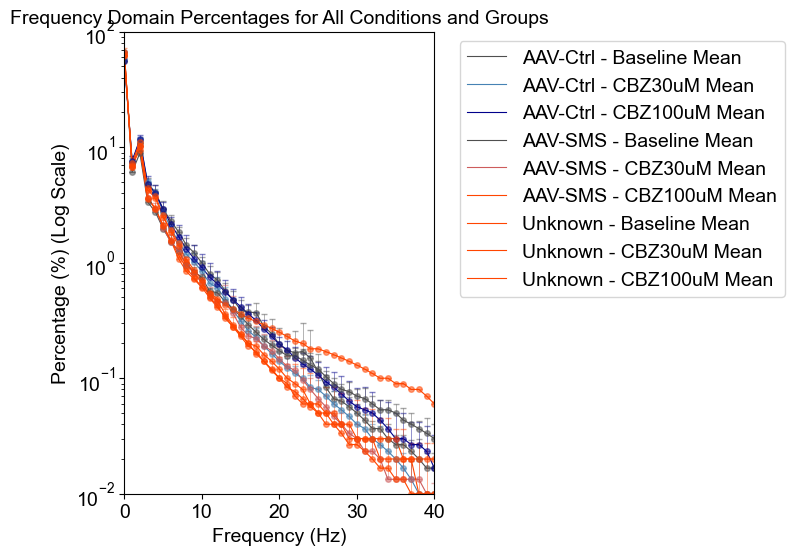

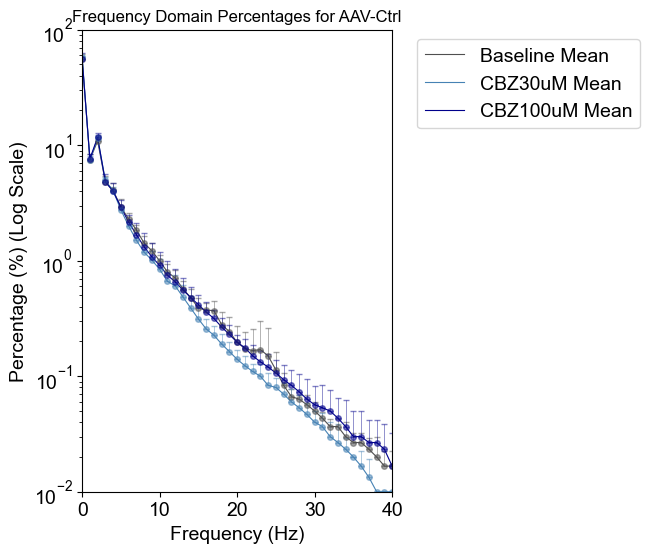

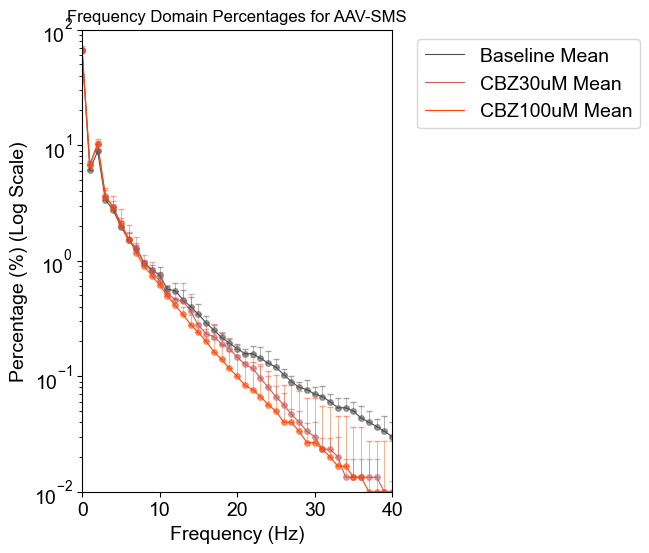

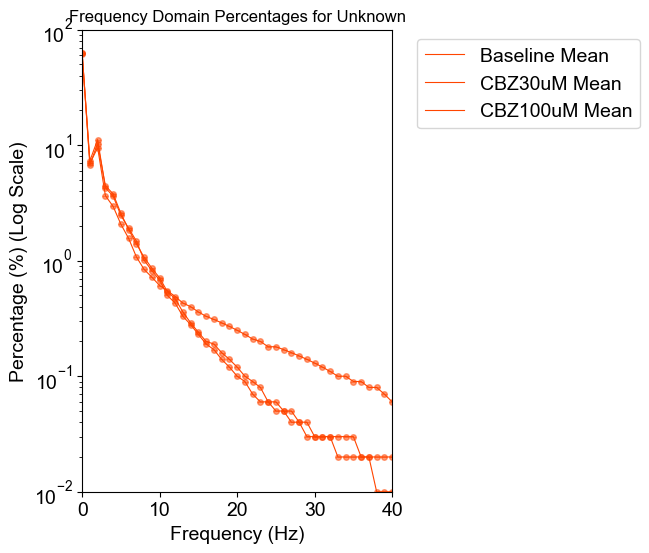

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Set font settings to avoid LaTeX-related warnings
plt.rcParams['text.usetex'] = False  # Disable LaTeX rendering
plt.rcParams['font.family'] = 'Arial'  # Use Arial or any other standard font

# Load your summarized data (assuming it's saved in the Excel file)
output_excel_path = r'D:------------\05_01_NetworkBurstRH_MEABasedStat_01.xlsx'
results_df = pd.read_excel(output_excel_path)

# Directory to save plots
output_dir = r'D:------------\Selected_05Plots_05_FreqDomainsConditions'
os.makedirs(output_dir, exist_ok=True)

# Step 1: Process `Freq_Domain_Percentages` dictionary for each sample to create a new DataFrame
freq_data = []

for idx, row in results_df.iterrows():
    group = row['Group']
    condition = row['Condition']  # Use Condition instead of dpi
    freq_domain_dict = eval(row['Freq_Domain_Percentages'])  # Ensure dictionary format
    freq_data.append({'Group': group, 'Condition': condition, **{int(k.strip('Hz')): float(v.strip('%')) for k, v in freq_domain_dict.items()}})

freq_df = pd.DataFrame(freq_data)

# Step 2: Group by `Group` and `Condition`, calculate mean and std for each frequency
summary_df = freq_df.groupby(['Group', 'Condition']).agg(['mean', 'std']).reset_index()

# Set fixed y-axis limits for log scale
y_min, y_max = 0.01, 100  # Adjust based on data range for better visualization
x_min, x_max = 0.0, 40

# Step 3: Plotting for all groups in one plot and separate plots for each group
# Condition map:
condition_map = {'00': 'Baseline', '01':'CBZ30uM', '02': 'CBZ100uM'}

# Define condition order to control the sequence
condition_order = [condition_map['00'], condition_map['01'], condition_map['02']]

# Ensure the 'Condition' column is treated as a categorical variable with the specified order
freq_df['Condition'] = pd.Categorical(freq_df['Condition'], categories=condition_order, ordered=True)

# Define color mapping for conditions
condition_colors = {}
for condition in condition_order:
    if condition in ['Baseline']:  # Baseline conditions
        condition_colors[condition] = '#4F4F4F'
    else:  # Other conditions (not Baseline or Washout)
        condition_colors[condition] = None  # This will be overridden by group color in the plotting loop

# Define color intensity based on conditions
condition_intensity = {
    'AAV-Ctrl': {
        'CBZ30uM': '#4682B4',  # Darker blue (steel blue)
        'CBZ100uM': '#00008B'  # Dark Blue (unchanged)
    },
    'AAV-SMS': {
        'CBZ30uM': '#CD5C5C',  # Darker orange (indian red)
        'CBZ100uM': '#FF4500'  # Dark Orange (unchanged)
    }
}

# Create one figure for all conditions and groups
plt.figure(figsize=(4, 6))

# Plot all conditions and groups in one plot
for group in summary_df['Group'].unique():
    group_df = summary_df[summary_df['Group'] == group]
    
    # Extract means and stds for all frequencies
    freqs = range(101)
    
    # Plot mean and std values for each condition
    for condition in condition_order:
        condition_df = group_df[group_df['Condition'] == condition]
        
        # Extract the mean and std for the current condition
        mean_percentages = condition_df.iloc[:, condition_df.columns.get_level_values(1) == 'mean'].values.flatten()
        std_percentages = condition_df.iloc[:, condition_df.columns.get_level_values(1) == 'std'].values.flatten()
        
        # Use the condition intensity color for each condition in each group
        if group == 'AAV-Ctrl':
            if condition == 'CBZ30uM':
                color = condition_intensity['AAV-Ctrl']['CBZ30uM']
            elif condition == 'CBZ100uM':
                color = condition_intensity['AAV-Ctrl']['CBZ100uM']
            else:
                color = '#4F4F4F'  # Baseline
        elif group == 'AAV-SMS':
            if condition == 'CBZ30uM':
                color = condition_intensity['AAV-SMS']['CBZ30uM']
            elif condition == 'CBZ100uM':
                color = condition_intensity['AAV-SMS']['CBZ100uM']
            else:
                color = '#4F4F4F'  # Baseline
        
        # Plot mean line with the selected color
        mean_line, = plt.plot(freqs, mean_percentages, label=f'{group} - {condition} Mean', color=color, linewidth=0.8)

        # Define yerr to show only the positive error bar side
        yerr = np.array([np.zeros_like(std_percentages), std_percentages])

        # Plot positive error bars with smaller circles
        plt.errorbar(
            freqs, mean_percentages, yerr=yerr, fmt='o', 
            color=mean_line.get_color(), alpha=0.5, elinewidth=0.6, capsize=2, markersize=4
        )

# Set y-axis to logarithmic scale and fix limits
plt.yscale('log')
plt.ylim(y_min, y_max)
plt.xlim(x_min, x_max)
# Format title with custom font size
plt.title('Frequency Domain Percentages for All Conditions and Groups', fontsize=14)

# Format x and y axis labels with custom font size
plt.xlabel('Frequency (Hz)', fontsize=14)
plt.ylabel('Percentage (%) (Log Scale)', fontsize=14)

# Adjust legend properties: set custom font size and place outside the plot
plt.legend(fontsize=14, loc='upper left', bbox_to_anchor=(1.05, 1))

# Optional: Adjust tick label font sizes
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# Save plot as PDF file for all conditions and groups
pdf_file_path = os.path.join(output_dir, 'ConditionsFreqDomain.pdf')
plt.savefig(pdf_file_path, format='pdf', bbox_inches='tight')
# Optional: Show plot
plt.show()
plt.close()  # Close the plot to free memory after saving

# Step 4: Plot separate plots for each group
for group in summary_df['Group'].unique():
    group_df = summary_df[summary_df['Group'] == group]
    
    plt.figure(figsize=(4, 6))

    # Plot mean and std values for each condition
    for condition in condition_order:
        condition_df = group_df[group_df['Condition'] == condition]
        
        # Extract the mean and std for the current condition
        mean_percentages = condition_df.iloc[:, condition_df.columns.get_level_values(1) == 'mean'].values.flatten()
        std_percentages = condition_df.iloc[:, condition_df.columns.get_level_values(1) == 'std'].values.flatten()

        # Use the condition intensity color for each condition in each group
        if group == 'AAV-Ctrl':
            if condition == 'CBZ30uM':
                color = condition_intensity['AAV-Ctrl']['CBZ30uM']
            elif condition == 'CBZ100uM':
                color = condition_intensity['AAV-Ctrl']['CBZ100uM']
            else:
                color = '#4F4F4F'  # Baseline
        elif group == 'AAV-SMS':
            if condition == 'CBZ30uM':
                color = condition_intensity['AAV-SMS']['CBZ30uM']
            elif condition == 'CBZ100uM':
                color = condition_intensity['AAV-SMS']['CBZ100uM']
            else:
                color = '#4F4F4F'  # Baseline
        
        # Plot mean line
        mean_line, = plt.plot(freqs, mean_percentages, label=f'{condition} Mean', color=color, linewidth=0.8)

        # Define yerr to show only the positive error bar side
        yerr = np.array([np.zeros_like(std_percentages), std_percentages])

        # Plot positive error bars only
        plt.errorbar(
            freqs, mean_percentages, yerr=yerr, fmt='o', 
            color=mean_line.get_color(), alpha=0.5, elinewidth=0.6, capsize=2, markersize=4
        )

    # Set y-axis to logarithmic scale and fix limits
    plt.yscale('log')
    plt.ylim(y_min, y_max)
    plt.xlim(x_min, x_max)
    plt.title(f'Frequency Domain Percentages for {group}')

    # Format x and y axis labels with custom font size
    plt.xlabel('Frequency (Hz)', fontsize=14)
    plt.ylabel('Percentage (%) (Log Scale)', fontsize=14)

    # Adjust legend properties: set custom font size and place outside the plot
    plt.legend(fontsize=14, loc='upper left', bbox_to_anchor=(1.05, 1))

    # Optional: Adjust tick label font sizes
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)

    # Save plot as PDF file for each group
    pdf_file_path_group = os.path.join(output_dir, f'{group}_ConditionsFreqDomain.pdf')
    plt.savefig(pdf_file_path_group, format='pdf', bbox_inches='tight')
    # Optional: Show plot
    plt.show()
    plt.close()  # Close the plot to free memory after saving


## 20261006--> to extract data of plots fro Kunihiko paper data upload


Excel plot data exported successfully.
Only frequencies 0–40 Hz were exported.
D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\0000_SelectedConditions\Selected_05Plots_05_FreqDomainsConditions_2026ForKunihiko\ConditionsFreqDomain_PlotData_0to40Hz.xlsx


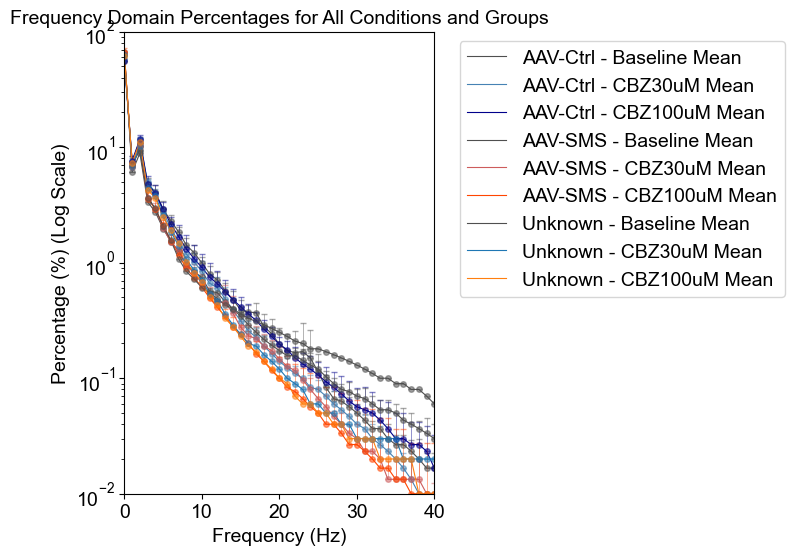

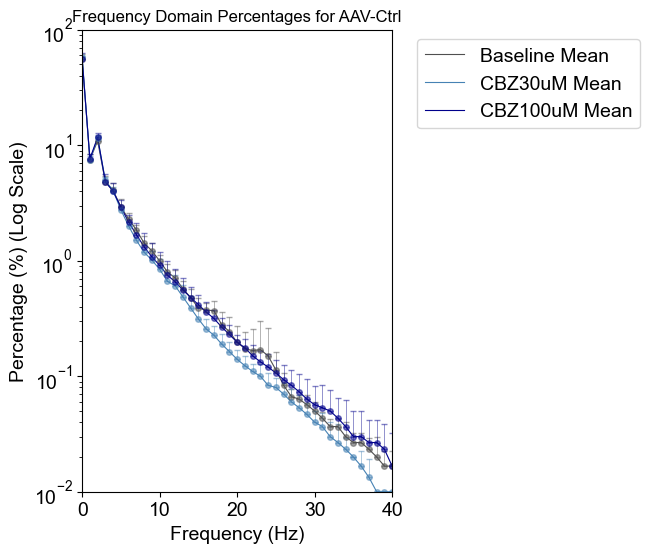

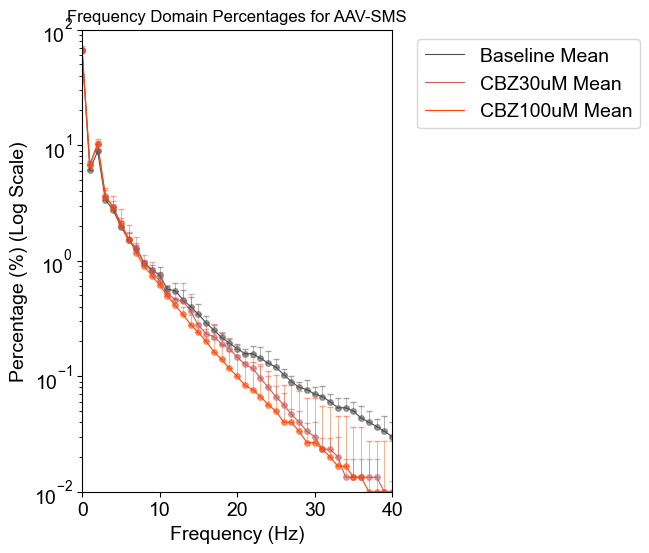

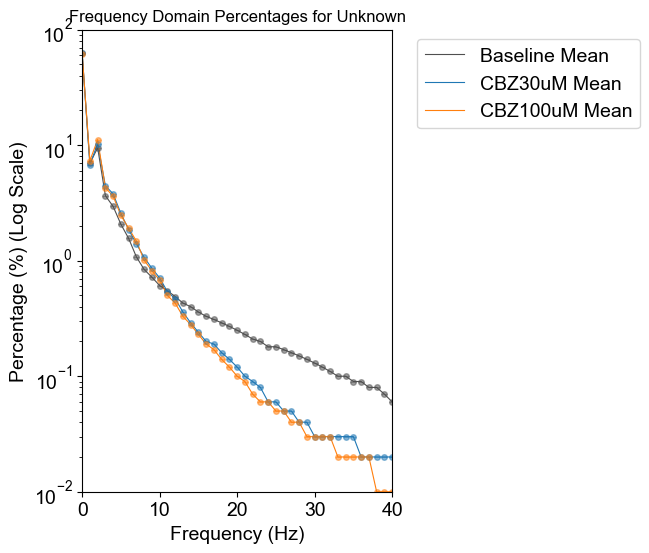


Finished successfully.

Plots saved in:
D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\0000_SelectedConditions\Selected_05Plots_05_FreqDomainsConditions_2026ForKunihiko

Excel data saved as:
D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\0000_SelectedConditions\Selected_05Plots_05_FreqDomainsConditions_2026ForKunihiko\ConditionsFreqDomain_PlotData_0to40Hz.xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# ============================================================
# SETTINGS
# ============================================================

# Set font settings to avoid LaTeX-related warnings
plt.rcParams['text.usetex'] = False
plt.rcParams['font.family'] = 'Arial'

# Input Excel file
output_excel_path = r'D:------------05_01_NetworkBurstRH_MEABasedStat_01.xlsx'

# Output directory
output_dir = r'D:------------\Selected_05Plots_05_FreqDomainsConditions_2026ForKunihiko'
os.makedirs(output_dir, exist_ok=True)

# Output Excel file containing plot data
plot_data_excel = os.path.join(
    output_dir,
    'ConditionsFreqDomain_PlotData_0to40Hz.xlsx'
)

# ============================================================
# LOAD DATA
# ============================================================

results_df = pd.read_excel(output_excel_path)

# ============================================================
# STEP 1: PROCESS FREQ_DOMAIN_PERCENTAGES
# ============================================================

freq_data = []

for idx, row in results_df.iterrows():

    group = row['Group']
    condition = row['Condition']

    # Convert stored dictionary string into dictionary
    freq_domain_dict = eval(row['Freq_Domain_Percentages'])

    parsed_data = {
        int(k.strip('Hz')): float(v.strip('%'))
        for k, v in freq_domain_dict.items()
    }

    freq_data.append({
        'Group': group,
        'Condition': condition,
        **parsed_data
    })

freq_df = pd.DataFrame(freq_data)

# ============================================================
# CONDITION SETTINGS
# ============================================================

condition_map = {
    '00': 'Baseline',
    '01': 'CBZ30uM',
    '02': 'CBZ100uM'
}

condition_order = [
    condition_map['00'],
    condition_map['01'],
    condition_map['02']
]

# Make condition categorical and ordered
freq_df['Condition'] = pd.Categorical(
    freq_df['Condition'],
    categories=condition_order,
    ordered=True
)

# ============================================================
# STEP 2: CALCULATE MEAN AND STANDARD DEVIATION
# ============================================================

summary_df = (
    freq_df
    .groupby(
        ['Group', 'Condition'],
        observed=True
    )
    .agg(['mean', 'std'])
    .reset_index()
)

# ============================================================
# FREQUENCY SETTINGS
# ============================================================

# Frequencies used internally for plotting
freqs = np.arange(0, 101)

# Frequencies exported to Excel
export_freqs = np.arange(0, 41)

# Plot limits
y_min = 0.01
y_max = 100

x_min = 0
x_max = 40

# ============================================================
# COLOR SETTINGS
# ============================================================

condition_intensity = {

    'AAV-Ctrl': {
        'CBZ30uM': '#4682B4',
        'CBZ100uM': '#00008B'
    },

    'AAV-SMS': {
        'CBZ30uM': '#CD5C5C',
        'CBZ100uM': '#FF4500'
    }
}


def get_color(group, condition):

    if condition == 'Baseline':
        return '#4F4F4F'

    if group in condition_intensity:

        if condition in condition_intensity[group]:
            return condition_intensity[group][condition]

    return None


# ============================================================
# FUNCTION TO GET MEAN AND SD VALUES
# ============================================================

def get_plot_values(group, condition):

    condition_df = summary_df[
        (summary_df['Group'] == group) &
        (summary_df['Condition'] == condition)
    ]

    if condition_df.empty:
        return None, None

    means = []
    stds = []

    for freq in freqs:

        # Mean value
        if (freq, 'mean') in condition_df.columns:
            mean_value = condition_df[(freq, 'mean')].iloc[0]
        else:
            mean_value = np.nan

        # Standard deviation
        if (freq, 'std') in condition_df.columns:
            std_value = condition_df[(freq, 'std')].iloc[0]
        else:
            std_value = np.nan

        means.append(mean_value)
        stds.append(std_value)

    return (
        np.array(means, dtype=float),
        np.array(stds, dtype=float)
    )


# ============================================================
# CREATE EXCEL DATA TABLES
# ONLY 0–40 Hz WILL BE EXPORTED
# ============================================================

all_plot_data = []

group_plot_data = {
    group: []
    for group in summary_df['Group'].unique()
}

for group in summary_df['Group'].unique():

    for condition in condition_order:

        mean_percentages, std_percentages = get_plot_values(
            group,
            condition
        )

        if mean_percentages is None:
            continue

        # Keep only 0–40 Hz
        export_mean = mean_percentages[:41]
        export_std = std_percentages[:41]

        temp_df = pd.DataFrame({

            'Group': [group] * len(export_freqs),

            'Condition': [condition] * len(export_freqs),

            'Frequency_Hz': export_freqs,

            'Mean_Percentage': export_mean,

            'SD_Percentage': export_std,

            'Mean_plus_SD': export_mean + export_std
        })

        all_plot_data.append(temp_df)

        group_plot_data[group].append(
            temp_df.copy()
        )


# Combine all groups
all_plot_data_df = pd.concat(
    all_plot_data,
    ignore_index=True
)

# ============================================================
# EXPORT DATA TO EXCEL
# ============================================================

with pd.ExcelWriter(
    plot_data_excel,
    engine='openpyxl'
) as writer:

    # --------------------------------------------------------
    # Sheet 1: All groups and conditions
    # --------------------------------------------------------

    all_plot_data_df.to_excel(
        writer,
        sheet_name='All_Groups',
        index=False
    )

    # --------------------------------------------------------
    # Separate sheet for each group
    # --------------------------------------------------------

    for group, dfs in group_plot_data.items():

        if len(dfs) == 0:
            continue

        group_export_df = pd.concat(
            dfs,
            ignore_index=True
        )

        # Excel sheet names cannot exceed 31 characters
        sheet_name = str(group)[:31]

        group_export_df.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )


print('Excel plot data exported successfully.')
print('Only frequencies 0–40 Hz were exported.')
print(plot_data_excel)

# ============================================================
# STEP 3: PLOT ALL GROUPS AND CONDITIONS TOGETHER
# ============================================================

plt.figure(figsize=(4, 6))

for group in summary_df['Group'].unique():

    for condition in condition_order:

        mean_percentages, std_percentages = get_plot_values(
            group,
            condition
        )

        if mean_percentages is None:
            continue

        color = get_color(
            group,
            condition
        )

        # ----------------------------------------------------
        # Plot mean
        # ----------------------------------------------------

        mean_line, = plt.plot(
            freqs,
            mean_percentages,
            label=f'{group} - {condition} Mean',
            color=color,
            linewidth=0.8
        )

        # ----------------------------------------------------
        # Positive SD error bars only
        # ----------------------------------------------------

        yerr = np.array([
            np.zeros_like(std_percentages),
            std_percentages
        ])

        plt.errorbar(
            freqs,
            mean_percentages,
            yerr=yerr,
            fmt='o',
            color=mean_line.get_color(),
            alpha=0.5,
            elinewidth=0.6,
            capsize=2,
            markersize=4
        )


# ============================================================
# FORMAT COMBINED PLOT
# ============================================================

plt.yscale('log')

plt.ylim(
    y_min,
    y_max
)

plt.xlim(
    x_min,
    x_max
)

plt.title(
    'Frequency Domain Percentages for All Conditions and Groups',
    fontsize=14
)

plt.xlabel(
    'Frequency (Hz)',
    fontsize=14
)

plt.ylabel(
    'Percentage (%) (Log Scale)',
    fontsize=14
)

plt.legend(
    fontsize=14,
    loc='upper left',
    bbox_to_anchor=(1.05, 1)
)

plt.xticks(
    fontsize=14
)

plt.yticks(
    fontsize=14
)

# Save combined plot
pdf_file_path = os.path.join(
    output_dir,
    'ConditionsFreqDomain.pdf'
)

plt.savefig(
    pdf_file_path,
    format='pdf',
    bbox_inches='tight'
)

plt.show()

plt.close()


# ============================================================
# STEP 4: CREATE SEPARATE PLOT FOR EACH GROUP
# ============================================================

for group in summary_df['Group'].unique():

    plt.figure(figsize=(4, 6))

    for condition in condition_order:

        mean_percentages, std_percentages = get_plot_values(
            group,
            condition
        )

        if mean_percentages is None:
            continue

        color = get_color(
            group,
            condition
        )

        # ----------------------------------------------------
        # Plot mean
        # ----------------------------------------------------

        mean_line, = plt.plot(
            freqs,
            mean_percentages,
            label=f'{condition} Mean',
            color=color,
            linewidth=0.8
        )

        # ----------------------------------------------------
        # Positive SD error bars
        # ----------------------------------------------------

        yerr = np.array([
            np.zeros_like(std_percentages),
            std_percentages
        ])

        plt.errorbar(
            freqs,
            mean_percentages,
            yerr=yerr,
            fmt='o',
            color=mean_line.get_color(),
            alpha=0.5,
            elinewidth=0.6,
            capsize=2,
            markersize=4
        )

    # ========================================================
    # FORMAT GROUP PLOT
    # ========================================================

    plt.yscale('log')

    plt.ylim(
        y_min,
        y_max
    )

    plt.xlim(
        x_min,
        x_max
    )

    plt.title(
        f'Frequency Domain Percentages for {group}'
    )

    plt.xlabel(
        'Frequency (Hz)',
        fontsize=14
    )

    plt.ylabel(
        'Percentage (%) (Log Scale)',
        fontsize=14
    )

    plt.legend(
        fontsize=14,
        loc='upper left',
        bbox_to_anchor=(1.05, 1)
    )

    plt.xticks(
        fontsize=14
    )

    plt.yticks(
        fontsize=14
    )

    # Save individual group plot
    pdf_file_path_group = os.path.join(
        output_dir,
        f'{group}_ConditionsFreqDomain.pdf'
    )

    plt.savefig(
        pdf_file_path_group,
        format='pdf',
        bbox_inches='tight'
    )

    plt.show()

    plt.close()


# ============================================================
# FINISHED
# ============================================================

print()
print('Finished successfully.')
print()
print('Plots saved in:')
print(output_dir)
print()
print('Excel data saved as:')
print(plot_data_excel)

<p style="font-size: 24px; font-weight: bold; color: Black;"> 05_07_Normalize the Freq_Domain_Percentages --> Freq_Domain_Percentages_Norm   --- Excel output 
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- The new excel file contain both normalized data and original data  </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- Normalized dictionary is saved in column Freq_Domain_Percentages_Norm    </span>
</p>

In [ ]:
### Normalize the Freq_Bin data in each sample and in each frequency band to its corresponding value in baseline condition and that frequency band

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast  # Import ast for safe evaluation of strings to dictionaries

# Load summarized data
output_excel_path = r'D:------------\05_01_NetworkBurstRH_MEABasedStat_01.xlsx'
results_df = pd.read_excel(output_excel_path)

# Step 1: Process Freq_Domain_Percentages dictionary for each sample to create a new DataFrame
freq_data = []
for idx, row in results_df.iterrows():
    if row.get('File Name') != '20240812_18389_01':
        group = row['Group']
        condition = row['Condition']  # Use 'Condition' instead of 'dpi'
        sample_id = int(row['Sample_ID'])
        freq_domain_dict = eval(row['Freq_Domain_Percentages'])
        freq_data.append({
            'Group': group, 'Condition': condition, 'Sample_ID': sample_id,
            **{int(k.strip('Hz')): float(v.strip('%')) for k, v in freq_domain_dict.items()}
        })

# Convert to DataFrame
freq_df = pd.DataFrame(freq_data)

# Step 2: Normalize frequency columns for each sample based on 'Baseline' condition
normalized_data = []

for sample_id in freq_df['Sample_ID'].unique():
    sample_df = freq_df[freq_df['Sample_ID'] == sample_id]
    baseline_row = sample_df[sample_df['Condition'] == 'Baseline']
    
    if not baseline_row.empty:
        baseline_values = baseline_row.iloc[0, 3:].to_dict()  # Use frequency data columns for baseline values
        
        # Normalize each condition based on the 'Baseline' values
        for _, row in sample_df.iterrows():
            condition = row['Condition']
            group = row['Group']
            normalized_row = {'Group': group, 'Condition': condition, 'Sample_ID': sample_id}
            freq_norm_dict = {}  # Initialize dictionary for normalized values
            
            for key, value in row[3:].to_dict().items():
                # Calculate normalized value
                norm_value = ((value - baseline_values[key]) / baseline_values[key]) * 100 if baseline_values[key] != 0 else ((value - baseline_values[key]) / 0.001) * 100
                freq_norm_dict[f'{key}Hz'] = f'{norm_value:.2f}%'  # Format as percentage

            # Add the normalized dictionary to the row
            normalized_row['Freq_Domain_Percentages_Norm'] = freq_norm_dict
            normalized_data.append(normalized_row)

# Convert normalized data to DataFrame
normalized_df = pd.DataFrame(normalized_data)

# Step 3: Merge normalized data with original results_df
merged_df = pd.merge(results_df, normalized_df[['Group', 'Condition', 'Sample_ID', 'Freq_Domain_Percentages_Norm']],
                     on=['Group', 'Condition', 'Sample_ID'], how='left')

# Save combined data to a new Excel file with normalized frequency as dictionaries
output_excel_path_normalized = r'D:\------------05_07_NormRHperBin_01.xlsx'
merged_df.to_excel(output_excel_path_normalized, index=False)
print(f'Normalized data together with original data were saved to {output_excel_path_normalized}')

Normalized data together with original data were saved to D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\05_07_NormRHperBin_01.xlsx


<p style="font-size: 24px; font-weight: bold; color: Green;"> Selected Conditions ____ 05_07_Normalize the Freq_Domain_Percentages --> Freq_Domain_Percentages_Norm   --- Excel output 
<p style="margin: 0;">
    <span style="font-size: 22px; color: Green;">- The new excel file contain both normalized data and original data  </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: Green;">- Normalized dictionary is saved in column Freq_Domain_Percentages_Norm    </span>
</p>

In [ ]:
### Normalize the Freq_Bin data in each sample and in each frequency band to its corresponding value in baseline condition and that frequency band

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast  # Import ast for safe evaluation of strings to dictionaries

# Load summarized data
output_excel_path = r'D:------------\05_01_NetworkBurstRH_MEABasedStat_01.xlsx'
results_df = pd.read_excel(output_excel_path)

# Step 1: Process Freq_Domain_Percentages dictionary for each sample to create a new DataFrame
freq_data = []
for idx, row in results_df.iterrows():
    if row.get('File Name') != '20240812_18389_01':
        group = row['Group']
        condition = row['Condition']  # Use 'Condition' instead of 'dpi'
        sample_id = int(row['Sample_ID'])
        freq_domain_dict = eval(row['Freq_Domain_Percentages'])
        freq_data.append({
            'Group': group, 'Condition': condition, 'Sample_ID': sample_id,
            **{int(k.strip('Hz')): float(v.strip('%')) for k, v in freq_domain_dict.items()}
        })

# Convert to DataFrame
freq_df = pd.DataFrame(freq_data)

# Step 2: Normalize frequency columns for each sample based on 'Baseline' condition
normalized_data = []

for sample_id in freq_df['Sample_ID'].unique():
    sample_df = freq_df[freq_df['Sample_ID'] == sample_id]
    baseline_row = sample_df[sample_df['Condition'] == 'Baseline']
    
    if not baseline_row.empty:
        baseline_values = baseline_row.iloc[0, 3:].to_dict()  # Use frequency data columns for baseline values
        
        # Normalize each condition based on the 'Baseline' values
        for _, row in sample_df.iterrows():
            condition = row['Condition']
            group = row['Group']
            normalized_row = {'Group': group, 'Condition': condition, 'Sample_ID': sample_id}
            freq_norm_dict = {}  # Initialize dictionary for normalized values
            
            for key, value in row[3:].to_dict().items():
                # Calculate normalized value
                norm_value = ((value - baseline_values[key]) / baseline_values[key]) * 100 if baseline_values[key] != 0 else ((value - baseline_values[key]) / 0.001) * 100
                freq_norm_dict[f'{key}Hz'] = f'{norm_value:.2f}%'  # Format as percentage

            # Add the normalized dictionary to the row
            normalized_row['Freq_Domain_Percentages_Norm'] = freq_norm_dict
            normalized_data.append(normalized_row)

# Convert normalized data to DataFrame
normalized_df = pd.DataFrame(normalized_data)

# Step 3: Merge normalized data with original results_df
merged_df = pd.merge(results_df, normalized_df[['Group', 'Condition', 'Sample_ID', 'Freq_Domain_Percentages_Norm']],
                     on=['Group', 'Condition', 'Sample_ID'], how='left')

# Save combined data to a new Excel file with normalized frequency as dictionaries
output_excel_path_normalized = r'D:------------\Selected_05Plots_05_FreqDomainsConditions\05_07_NormRHperBin_01.xlsx'
merged_df.to_excel(output_excel_path_normalized, index=False)
print(f'Normalized data together with original data were saved to {output_excel_path_normalized}')

Normalized data together with original data were saved to D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\0000_SelectedConditions\Selected_05Plots_05_FreqDomainsConditions\05_07_NormRHperBin_01.xlsx


<p style="font-size: 24px; font-weight: bold; color: Black;"> 05Plots_07_NormalizedFreqDomains Normalized Condition_based  plots   
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- Uses the new excel file contain both normalized data and original data  </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- uses the already calculated normalized percentages of bins with specific freq in excel file </span>
</p>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load summarized data
output_excel_path = r'D:\------------\05_07_NormRHperBin_01.xlsx'
results_df = pd.read_excel(output_excel_path)

# Directory to save plots
save_dir = r'D:\------------5Plots_07_NormFreqDomainsConditions'
os.makedirs(save_dir, exist_ok=True)

# Step 1: Process Freq_Domain_Percentages_Norm dictionary for each sample to create a new DataFrame
freq_data = []
for idx, row in results_df.iterrows():
    if row.get('File Name') != '20240812_18389_01':
        group = row['Group']
        condition = row['Condition']  # Use Condition instead of dpi
        sample_id = int(row['Sample_ID'])
        
        # Parse the pre-normalized frequency domain percentages
        freq_domain_dict = eval(row['Freq_Domain_Percentages_Norm'])
        freq_data.append({
            'Group': group, 'Condition': condition, 'Sample_ID': sample_id,
            **{int(k.strip('Hz')): float(v.strip('%')) for k, v in freq_domain_dict.items()}
        })

# Convert to DataFrame
normalized_df = pd.DataFrame(freq_data)

# Step 2: Filter out specific Sample_ID if needed
normalized_df_filtered = normalized_df[normalized_df['Sample_ID'] != 18574].copy()

frequency_columns = normalized_df_filtered.columns[3:]

# Define condition order
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Ensure 'Condition' is treated as a categorical variable with the specified order
normalized_df_filtered['Condition'] = pd.Categorical(normalized_df_filtered['Condition'], categories=condition_order, ordered=True)

# Define a custom function to calculate SEM
def sem(x):
    return np.std(x, ddof=1) / np.sqrt(len(x))

# Step 3: Iterate through each condition and plot data for each group
unique_conditions = condition_order
groups = normalized_df_filtered['Group'].unique()

for condition in unique_conditions:
    fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6, 6), gridspec_kw={'height_ratios': [1, 3]})
    
    for group in groups:
        # Filter data for the current condition and group
        group_condition_data = normalized_df_filtered[(normalized_df_filtered['Group'] == group) & 
                                                      (normalized_df_filtered['Condition'] == condition)]
        
        if not group_condition_data.empty:
            # Calculate mean and SEM for each frequency
            mean_percentages = group_condition_data[frequency_columns].mean()
            sem_percentages = group_condition_data[frequency_columns].apply(sem)
            freqs = np.arange(len(frequency_columns))
            
            # Define color based on group
            plot_color = 'C1' if group == 'AAV-SMS' else 'C0'
            
            # Plot mean line with SEM shaded area on both axes
            ax1.plot(freqs, mean_percentages, label=f'{group} Mean', color=plot_color)
            ax1.fill_between(freqs, mean_percentages - sem_percentages, mean_percentages + sem_percentages,
                             color=plot_color, alpha=0.2)
            ax2.plot(freqs, mean_percentages, label=f'{group} Mean', color=plot_color)
            ax2.fill_between(freqs, mean_percentages - sem_percentages, mean_percentages + sem_percentages,
                             color=plot_color, alpha=0.2)
            
            # Scatter individual data points
            for i, freq in enumerate(frequency_columns):
                freq_values = group_condition_data[freq].values
                ax1.scatter([freqs[i]] * len(freq_values), freq_values, color=plot_color, alpha=0.3, s=3)
                ax2.scatter([freqs[i]] * len(freq_values), freq_values, color=plot_color, alpha=0.3, s=3)
    
    # Set y-limits for the broken y-axis
    ax1.set_ylim(200, 400)
    ax2.set_ylim(-100, 200)
    plt.xlim(0, 40)
    
    # Hide spines between the two plots
    ax1.spines['bottom'].set_visible(False)
    ax2.spines['top'].set_visible(False)
    ax1.xaxis.tick_top()
    ax1.tick_params(labeltop=False)
    ax2.xaxis.tick_bottom()
    
    # Diagonal lines to indicate broken axis
    d = 0.01  # Size of diagonal lines
    kwargs = dict(transform=ax1.transAxes, color='k', clip_on=False)
    ax1.plot((-d, +d), (-d, +d), **kwargs)
    ax1.plot((1 - d, 1 + d), (-d, +d), **kwargs)
    
    kwargs.update(transform=ax2.transAxes)
    ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)
    ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)
    
    # Title and labels for each condition plot
    fig.suptitle(f'Averaged Normalized Frequency Domain Percentages for Condition {condition}')
    ax2.set_xlabel('Frequency (Hz)')
    ax1.set_ylabel('Normalized Percentage (%)')
    ax2.set_ylabel('Normalized Percentage (%)')
    
    # Move legend outside the plot area
    ax2.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.00)
    
    # Save plot as PDF
    save_path = os.path.join(save_dir, f'Freq_Bin_condition_based_{condition}_Norm.pdf')
    plt.savefig(save_path, format='pdf')
    plt.close(fig)


##  Extraction of data for paper

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import ast

# ============================================================
# PATHS
# ============================================================

# Load summarized data
output_excel_path = r'D:------------\05_07_NormRHperBin_01.xlsx'
results_df = pd.read_excel(output_excel_path)
# Directory to save plots
save_dir = r'D:------------\05Plots_07_NormFreqDomainsConditions_2026_----'
os.makedirs(save_dir, exist_ok=True)

# Excel file containing source data for all plots
plot_data_excel = os.path.join(
    save_dir,
    'Freq_Bin_condition_based_Norm_PlotData.xlsx'
)

# ============================================================
# STEP 1: PROCESS NORMALIZED FREQUENCY-DOMAIN DATA
# ============================================================

freq_data = []

for idx, row in results_df.iterrows():

    # Exclude this file
    if row.get('File Name') != '20240812_18389_01':

        group = row['Group']
        condition = row['Condition']
        sample_id = int(row['Sample_ID'])

        # Parse dictionary safely
        freq_domain_dict = ast.literal_eval(
            row['Freq_Domain_Percentages_Norm']
        )

        parsed_values = {
            int(k.strip('Hz')): float(v.strip('%'))
            for k, v in freq_domain_dict.items()
        }

        freq_data.append({
            'Group': group,
            'Condition': condition,
            'Sample_ID': sample_id,
            **parsed_values
        })

# Convert to DataFrame
normalized_df = pd.DataFrame(freq_data)

# ============================================================
# STEP 2: FILTER SPECIFIC SAMPLE
# ============================================================

normalized_df_filtered = normalized_df[
    normalized_df['Sample_ID'] != 18574
].copy()

# ============================================================
# CONDITION ORDER
# ============================================================

condition_order = [
    'Baseline',
    'CBZ30uM',
    'CBZ60uM',
    'CBZ100uM',
    'Washout'
]

normalized_df_filtered['Condition'] = pd.Categorical(
    normalized_df_filtered['Condition'],
    categories=condition_order,
    ordered=True
)

# ============================================================
# FREQUENCIES USED IN THE PLOTS
# ONLY 0–40 Hz
# ============================================================

plot_frequencies = list(range(0, 41))

# Keep only frequency columns that actually exist
frequency_columns = [
    freq for freq in plot_frequencies
    if freq in normalized_df_filtered.columns
]

# ============================================================
# SEM FUNCTION
# ============================================================

def sem(x):

    x = pd.Series(x).dropna()

    if len(x) <= 1:
        return np.nan

    return np.std(x, ddof=1) / np.sqrt(len(x))


# ============================================================
# GROUPS
# ============================================================

groups = normalized_df_filtered['Group'].dropna().unique()

# ============================================================
# CREATE EXCEL WRITER
# ============================================================

with pd.ExcelWriter(
    plot_data_excel,
    engine='openpyxl'
) as writer:

    # ========================================================
    # ITERATE THROUGH EACH CONDITION
    # ONE CONDITION = ONE PLOT = ONE EXCEL SHEET
    # ========================================================

    for condition in condition_order:

        # ----------------------------------------------------
        # CREATE FIGURE
        # ----------------------------------------------------

        fig, (ax1, ax2) = plt.subplots(
            2,
            1,
            sharex=True,
            figsize=(6, 6),
            gridspec_kw={'height_ratios': [1, 3]}
        )

        # This list collects all data used for this plot
        condition_export_data = []

        # ====================================================
        # LOOP THROUGH GROUPS
        # ====================================================

        for group in groups:

            # Filter data
            group_condition_data = normalized_df_filtered[
                (normalized_df_filtered['Group'] == group) &
                (normalized_df_filtered['Condition'] == condition)
            ]

            if group_condition_data.empty:
                continue

            # ------------------------------------------------
            # CALCULATE MEAN AND SEM
            # ------------------------------------------------

            mean_percentages = (
                group_condition_data[frequency_columns]
                .mean()
            )

            sem_percentages = (
                group_condition_data[frequency_columns]
                .apply(sem)
            )

            # Actual frequency values
            freqs = np.array(frequency_columns)

            # ------------------------------------------------
            # DEFINE COLOR
            # ------------------------------------------------

            plot_color = 'C1' if group == 'AAV-SMS' else 'C0'

            # ------------------------------------------------
            # PLOT MEAN + SEM
            # ------------------------------------------------

            ax1.plot(
                freqs,
                mean_percentages.values,
                label=f'{group} Mean',
                color=plot_color
            )

            ax1.fill_between(
                freqs,
                (mean_percentages - sem_percentages).values,
                (mean_percentages + sem_percentages).values,
                color=plot_color,
                alpha=0.2
            )

            ax2.plot(
                freqs,
                mean_percentages.values,
                label=f'{group} Mean',
                color=plot_color
            )

            ax2.fill_between(
                freqs,
                (mean_percentages - sem_percentages).values,
                (mean_percentages + sem_percentages).values,
                color=plot_color,
                alpha=0.2
            )

            # =================================================
            # INDIVIDUAL DATA POINTS
            # =================================================

            for freq in frequency_columns:

                freq_values = (
                    group_condition_data[freq]
                    .values
                )

                # Scatter individual data points
                ax1.scatter(
                    [freq] * len(freq_values),
                    freq_values,
                    color=plot_color,
                    alpha=0.3,
                    s=3
                )

                ax2.scatter(
                    [freq] * len(freq_values),
                    freq_values,
                    color=plot_color,
                    alpha=0.3,
                    s=3
                )

                # Mean and SEM for this frequency
                mean_value = mean_percentages.loc[freq]
                sem_value = sem_percentages.loc[freq]

                # ---------------------------------------------
                # ADD EACH INDIVIDUAL POINT TO EXCEL DATA
                # ---------------------------------------------

                for sample_index, row in group_condition_data.iterrows():

                    condition_export_data.append({
                        'Condition': condition,
                        'Group': group,
                        'Sample_ID': row['Sample_ID'],
                        'Frequency_Hz': freq,
                        'Individual_Value': row[freq],
                        'Mean': mean_value,
                        'SEM': sem_value,
                        'Mean_minus_SEM': (
                            mean_value - sem_value
                            if pd.notna(sem_value)
                            else np.nan
                        ),
                        'Mean_plus_SEM': (
                            mean_value + sem_value
                            if pd.notna(sem_value)
                            else np.nan
                        )
                    })

        # ====================================================
        # FORMAT BROKEN Y-AXIS
        # ====================================================

        ax1.set_ylim(200, 400)
        ax2.set_ylim(-100, 200)

        ax2.set_xlim(0, 40)

        # Hide spines between axes
        ax1.spines['bottom'].set_visible(False)
        ax2.spines['top'].set_visible(False)

        ax1.xaxis.tick_top()
        ax1.tick_params(labeltop=False)

        ax2.xaxis.tick_bottom()

        # ====================================================
        # DIAGONAL LINES FOR BROKEN AXIS
        # ====================================================

        d = 0.01

        kwargs = dict(
            transform=ax1.transAxes,
            color='k',
            clip_on=False
        )

        ax1.plot(
            (-d, +d),
            (-d, +d),
            **kwargs
        )

        ax1.plot(
            (1 - d, 1 + d),
            (-d, +d),
            **kwargs
        )

        kwargs.update(
            transform=ax2.transAxes
        )

        ax2.plot(
            (-d, +d),
            (1 - d, 1 + d),
            **kwargs
        )

        ax2.plot(
            (1 - d, 1 + d),
            (1 - d, 1 + d),
            **kwargs
        )

        # ====================================================
        # TITLES AND LABELS
        # ====================================================

        fig.suptitle(
            f'Averaged Normalized Frequency Domain Percentages '
            f'for Condition {condition}'
        )

        ax2.set_xlabel(
            'Frequency (Hz)'
        )

        ax1.set_ylabel(
            'Normalized Percentage (%)'
        )

        ax2.set_ylabel(
            'Normalized Percentage (%)'
        )

        # Legend outside plot
        ax2.legend(
            loc='upper left',
            bbox_to_anchor=(1, 1)
        )

        plt.tight_layout()
        plt.subplots_adjust(hspace=0.00)

        # ====================================================
        # SAVE PDF
        # ====================================================

        save_path = os.path.join(
            save_dir,
            f'Freq_Bin_condition_based_{condition}_Norm.pdf'
        )

        plt.savefig(
            save_path,
            format='pdf',
            bbox_inches='tight'
        )

        plt.close(fig)

        # ====================================================
        # EXPORT DATA FOR THIS PLOT TO ITS OWN EXCEL SHEET
        # ====================================================

        if len(condition_export_data) > 0:

            condition_export_df = pd.DataFrame(
                condition_export_data
            )

            # Sort for easier reading
            condition_export_df = (
                condition_export_df
                .sort_values(
                    by=[
                        'Group',
                        'Frequency_Hz',
                        'Sample_ID'
                    ]
                )
                .reset_index(drop=True)
            )

            condition_export_df.to_excel(
                writer,
                sheet_name=condition[:31],
                index=False
            )

# ============================================================
# FINISHED
# ============================================================

print()
print('Finished successfully.')
print()
print('PDF plots saved in:')
print(save_dir)
print()
print('Excel source data saved as:')
print(plot_data_excel)
print()
print('Each condition plot has its own Excel sheet.')
print('Only frequencies 0–40 Hz are included.')


Finished successfully.

PDF plots saved in:
D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\05Plots_07_NormFreqDomainsConditions_2026_Kunihiko

Excel source data saved as:
D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\05Plots_07_NormFreqDomainsConditions_2026_Kunihiko\Freq_Bin_condition_based_Norm_PlotData.xlsx

Each condition plot has its own Excel sheet.
Only frequencies 0–40 Hz are included.


<p style="font-size: 24px; font-weight: bold; color: Green;"> Selected Conditions ______ 05Plots_07_NormalizedFreqDomains Normalized Condition_based  plots   
<p style="margin: 0;">
    <span style="font-size: 22px; color: Green;">- Uses the new excel file contain both normalized data and original data  </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: Green;">- uses the already calculated normalized percentages of bins with specific freq in excel file </span>
</p>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load summarized data
output_excel_path = r'------------\05_07_NormRHperBin_01.xlsx'
results_df = pd.read_excel(output_excel_path)

# Directory to save plots
save_dir = r'D:------------\0000_SelectedConditions\Selected_05Plots_05_FreqDomainsConditions'
os.makedirs(save_dir, exist_ok=True)

# Step 1: Process Freq_Domain_Percentages_Norm dictionary for each sample to create a new DataFrame
freq_data = []
for idx, row in results_df.iterrows():
    if row.get('File Name') != '20240812_18389_01':
        group = row['Group']
        condition = row['Condition']  # Use Condition instead of dpi
        sample_id = int(row['Sample_ID'])
        
        # Parse the pre-normalized frequency domain percentages
        freq_domain_dict = eval(row['Freq_Domain_Percentages_Norm'])
        freq_data.append({
            'Group': group, 'Condition': condition, 'Sample_ID': sample_id,
            **{int(k.strip('Hz')): float(v.strip('%')) for k, v in freq_domain_dict.items()}
        })

# Convert to DataFrame
normalized_df = pd.DataFrame(freq_data)

# Step 2: Filter out specific Sample_ID if needed
normalized_df_filtered = normalized_df[normalized_df['Sample_ID'] != 18574].copy()

frequency_columns = normalized_df_filtered.columns[3:]

# Define condition order
condition_order = ['Baseline', 'CBZ30uM', 'CBZ100uM']

# Ensure 'Condition' is treated as a categorical variable with the specified order
normalized_df_filtered['Condition'] = pd.Categorical(normalized_df_filtered['Condition'], categories=condition_order, ordered=True)

# Define a custom function to calculate SEM
def sem(x):
    return np.std(x, ddof=1) / np.sqrt(len(x))

# Step 3: Iterate through each condition and plot data for each group
unique_conditions = condition_order
groups = normalized_df_filtered['Group'].unique()

for condition in unique_conditions:
    fig, ax = plt.subplots(figsize=(4, 4))  # Single axis without y-axis break
    
    for group in groups:
        # Filter data for the current condition and group
        group_condition_data = normalized_df_filtered[
            (normalized_df_filtered['Group'] == group) & 
            (normalized_df_filtered['Condition'] == condition)
        ]
        
        if not group_condition_data.empty:
            # Calculate mean and SEM for each frequency
            mean_percentages = group_condition_data[frequency_columns].mean()
            sem_percentages = group_condition_data[frequency_columns].apply(sem)
            freqs = np.arange(len(frequency_columns))
            
            # Define color based on group
            plot_color = 'C1' if group == 'AAV-SMS' else 'C0'
            
            # Plot mean line with SEM shaded area
            ax.plot(freqs, mean_percentages, label=f'{group} Mean', color=plot_color)
            ax.fill_between(freqs, mean_percentages - sem_percentages, mean_percentages + sem_percentages,
                            color=plot_color, alpha=0.2)
            
            # Scatter individual data points
            for i, freq in enumerate(frequency_columns):
                freq_values = group_condition_data[freq].values
                ax.scatter([freqs[i]] * len(freq_values), freq_values, color=plot_color, alpha=0.3, s=3)
    
    # Set y-axis limits and x-axis range
    ax.set_ylim(-120, 120)
    plt.xlim(0, 40)
    
    # Title and labels for each condition plot
    ax.set_title(f'Averaged Normalized Frequency Domain Percentages for Condition {condition}')
    ax.set_xlabel('Frequency (Hz)', fontsize=14)
    ax.set_ylabel('Normalized Percentage (%)', fontsize=14)

    # Optional: Adjust tick label font sizes
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    
    # Move legend outside the plot area
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.tight_layout()
    
    # Save plot as PDF
    save_path = os.path.join(save_dir, f'Freq_Bin_condition_based_{condition}_Norm.pdf')
    plt.savefig(save_path, format='pdf')
    plt.close(fig)


<p style="font-size: 24px; font-weight: bold; color: Black;"> 05_08_PlotsNet_FreqDomains Normalized Freq_Domain_Norm_5HzIntervals   
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- Uses NFreq_Domain_Percentage_Norm data, split them into 5Hz intervals (0 to 35Hz included) </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- The new excel file containing the data of each Freq interval in each dpi is generated  </span>
</p>

C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_66988\3764084519.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  normalized_df_filtered['Condition'] = pd.Categorical(


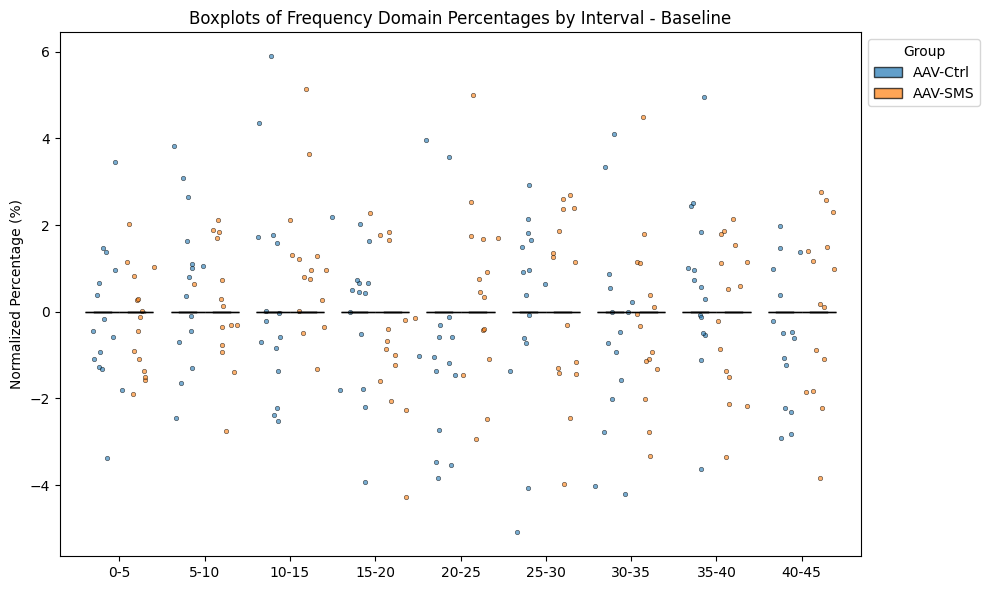

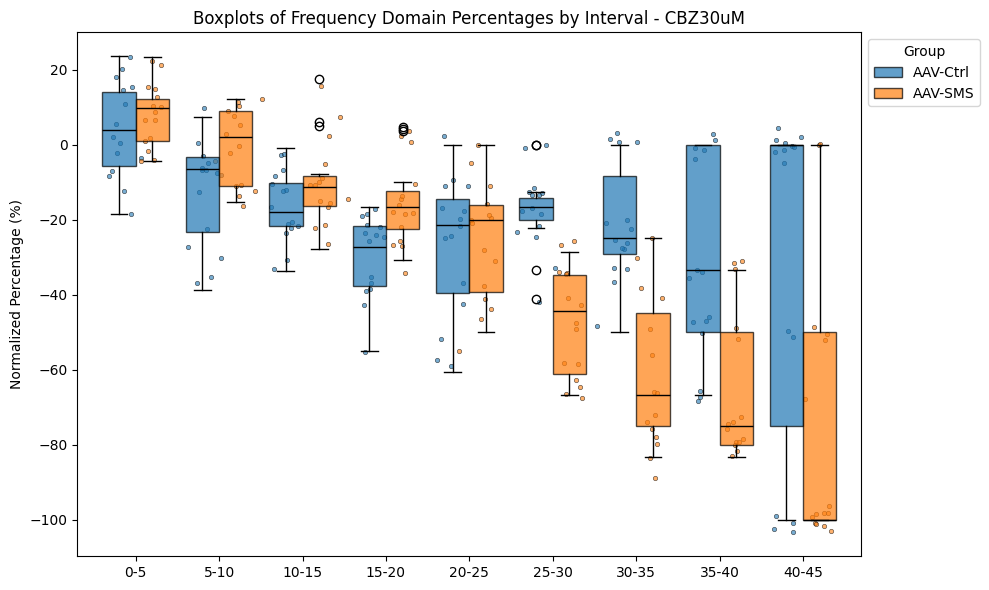

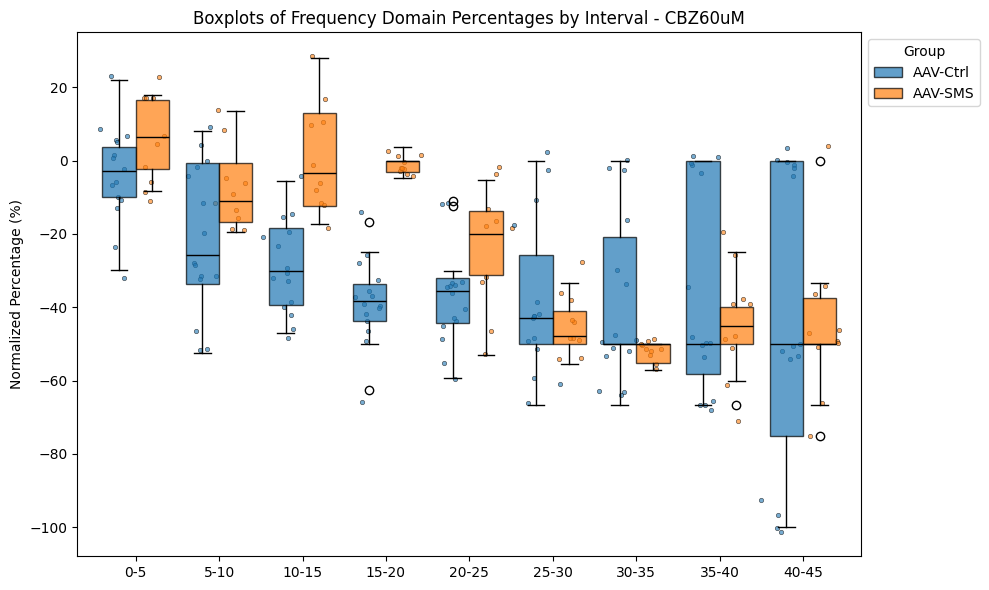

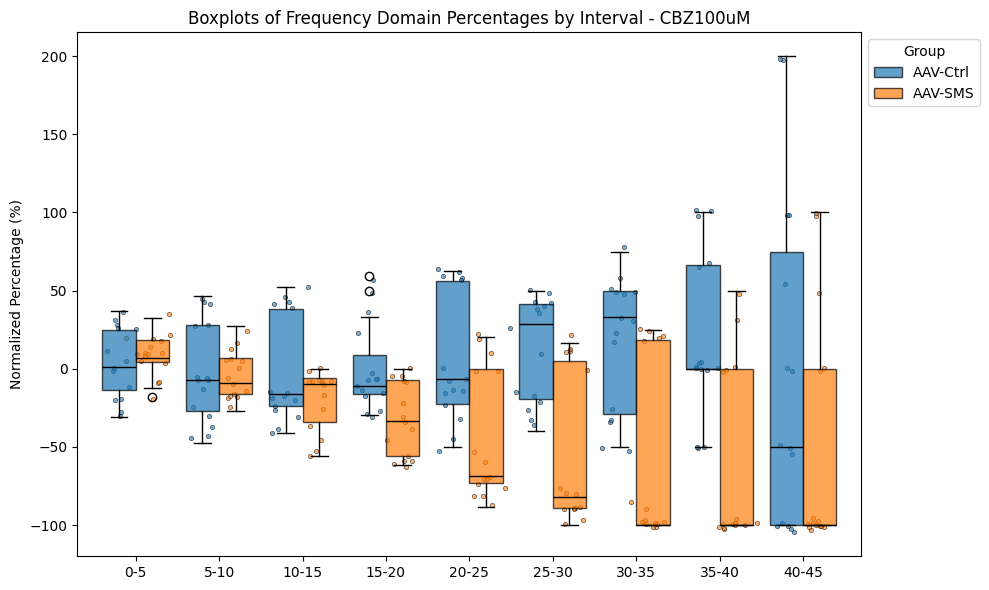

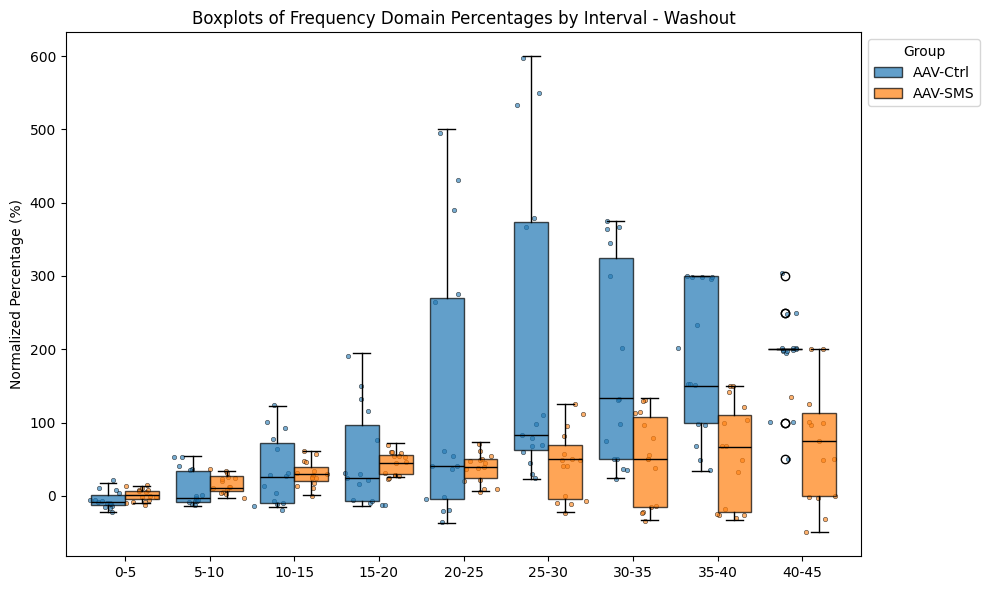

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load summarized data
output_excel_path = r'D:------------\05_07_NormRHperBin_01.xlsx'
results_df = pd.read_excel(output_excel_path)

# Directory to save plots and data
save_dir = r'D:------------\05Plots_08_NormFreqDomainsConditions_intervals'
os.makedirs(save_dir, exist_ok=True)

# Step 1: Process Freq_Domain_Percentages_Norm dictionary for each sample to create a new DataFrame
freq_data = []
for idx, row in results_df.iterrows():
    if row.get('File Name') != '20240812_18389_01':
        group = row['Group']
        condition = row['Condition']  # Use Condition instead of dpi
        sample_id = int(row['Sample_ID'])
        
        # Parse the pre-normalized frequency domain percentages
        freq_domain_dict = eval(row['Freq_Domain_Percentages_Norm'])
        freq_data.append({
            'Group': group, 'Condition': condition, 'Sample_ID': sample_id,
            **{int(k.strip('Hz')): float(v.strip('%')) for k, v in freq_domain_dict.items()}
        })

# Convert to DataFrame
normalized_df = pd.DataFrame(freq_data)

# Step 2: Filter out specific Sample_ID if needed
normalized_df_filtered = normalized_df[normalized_df['Sample_ID'] != 18574]

# Define condition order and treat 'Condition' as a categorical variable with specified order
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']
normalized_df_filtered['Condition'] = pd.Categorical(
    normalized_df_filtered['Condition'], categories=condition_order, ordered=True
)

# Step 3: Select only frequency columns with integer names less than 35
frequency_columns = normalized_df_filtered.columns[3:]
frequency_columns = [col for col in frequency_columns if isinstance(col, int) and col < 46]

# Step 4: Define intervals for frequency bins
bins = np.arange(0, 46, 5)

# Initialize a dictionary to hold pooled data for each condition
pooled_data = []
export_data_dict = {}

# Iterate over the defined frequency intervals
for i in range(len(bins) - 1):
    lower_bound = bins[i]
    upper_bound = bins[i + 1]
    
    # Select frequency columns in the current interval
    interval_columns = [col for col in frequency_columns if lower_bound <= col < upper_bound]
    
    if interval_columns:
        for group in normalized_df_filtered['Group'].unique():
            for condition in condition_order:
                group_condition_data = normalized_df_filtered[
                    (normalized_df_filtered['Group'] == group) & 
                    (normalized_df_filtered['Condition'] == condition)
                ]
                
                if not group_condition_data.empty:
                    frequency_data = group_condition_data[interval_columns]
                    mean_value = frequency_data.mean().mean()
                    
                    pooled_data.append({
                        'Frequency Interval': f'{lower_bound}-{upper_bound}',
                        'Group': group,
                        'Condition': condition,
                        'Mean': mean_value,
                        'SD': frequency_data.std().mean(),
                        'SEM': frequency_data.std(ddof=1).mean() / np.sqrt(frequency_data.count().mean()),
                        'Data': frequency_data.values.flatten()
                    })
                    
                    for _, sample_row in group_condition_data.iterrows():
                        sample_id = sample_row['Sample_ID']
                        key = (sample_id, condition, group)
                        if key not in export_data_dict:
                            export_data_dict[key] = {'Group': group, 'Sample_ID': sample_id, 'Condition': condition}
                        export_data_dict[key][f'{lower_bound}-{upper_bound} Hz'] = sample_row[interval_columns].mean()

# Convert pooled data to DataFrame
pooled_df = pd.DataFrame(pooled_data)

# Convert export data to DataFrame
export_df = pd.DataFrame.from_dict(export_data_dict, orient='index').reset_index(drop=True)

# Step 5: Plotting separate boxplots for each condition
colors = {
    'AAV-Ctrl': '#1f77b4',  # Blue
    'AAV-SMS': '#ff7f0e'    # Orange
}

# Plot each condition separately
for condition in condition_order:
    fig, ax = plt.subplots(figsize=(10, 6))

    # Filter data for the current condition
    condition_data = pooled_df[pooled_df['Condition'] == condition]
    unique_intervals = condition_data['Frequency Interval'].unique()
    positions = np.arange(1, len(unique_intervals) + 1)
    
    # Create boxplots for each frequency interval within this condition
    for i, interval in enumerate(unique_intervals):
        interval_data = condition_data[condition_data['Frequency Interval'] == interval]
        box_data = []
        
        for group in interval_data['Group'].unique():
            data = interval_data[interval_data['Group'] == group]['Data'].values[0]
            box_data.append(data)
        
        box_positions = positions[i] + np.linspace(-0.2, 0.2, len(box_data))
        bp = ax.boxplot(box_data, positions=box_positions, widths=0.4, patch_artist=True)
        
        for patch, group in zip(bp['boxes'], interval_data['Group']):
            patch.set_facecolor(colors[group])
            patch.set_alpha(0.7)

        for median in bp['medians']:
            median.set_color('black')
            median.set_linewidth(1)

        for j, group in enumerate(interval_data['Group'].unique()):
            data_points = interval_data[interval_data['Group'] == group]['Data'].values[0]
            jittered_x = np.full(data_points.shape, box_positions[j]) + np.random.normal(0, 0.1, size=data_points.shape)
            jittered_y = data_points + np.random.normal(0, 2, size=data_points.shape)
            ax.scatter(jittered_x, jittered_y, alpha=0.6, color=colors[group], edgecolor='black', linewidth=0.5, s=10)

    # Customize plot
    ax.set_xticks(positions)
    ax.set_xticklabels(unique_intervals)
    ax.set_ylabel('Normalized Percentage (%)')
    ax.set_title(f'Boxplots of Frequency Domain Percentages by Interval - {condition}')
    ax.legend(colors.keys(), title="Group", loc='upper left', bbox_to_anchor=(1, 1))

    # Save plot
    save_path = os.path.join(save_dir, f'Freq_Domain_{condition}_5HzIntervals.pdf')
    plt.tight_layout()
    plt.savefig(save_path, format='pdf')
    plt.show()
    plt.close(fig)

# Step 6: Export data to Excel
export_excel_path = os.path.join(save_dir, 'Freq_Domain_Norm_5HzIntervals.xlsx')
export_df.to_excel(export_excel_path, index=False)



<p style="font-size: 30px; font-weight: bold; color: Green;"> Selected Conditions ___________ 05_08_PlotsNet_FreqDomains Normalized Freq_Domain_Norm_5HzIntervals   
<p style="margin: 0;">
    <span style="font-size: 22px; color: Green;">- Uses NFreq_Domain_Percentage_Norm data, split them into 5Hz intervals (0 to 35Hz included) </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: Green;">- The new excel file containing the data of each Freq interval in each dpi is generated  </span>
</p>

C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_28976\2858357745.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  normalized_df_filtered['Condition'] = pd.Categorical(


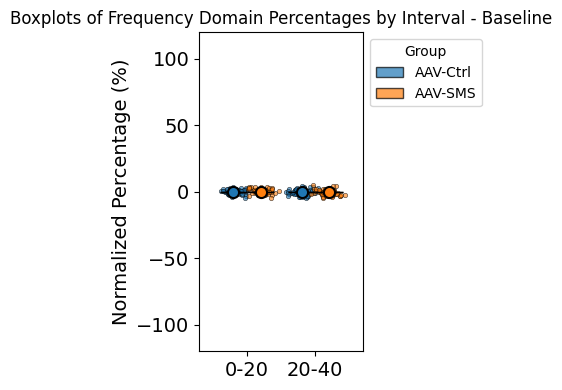

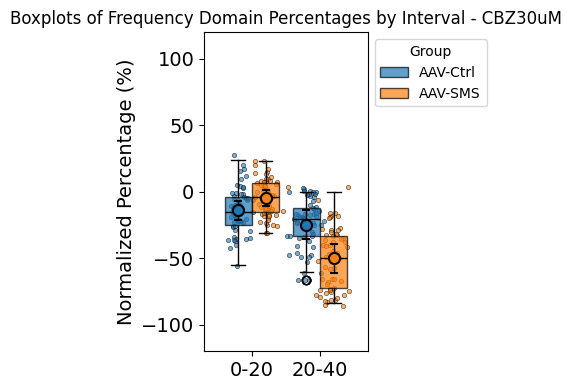

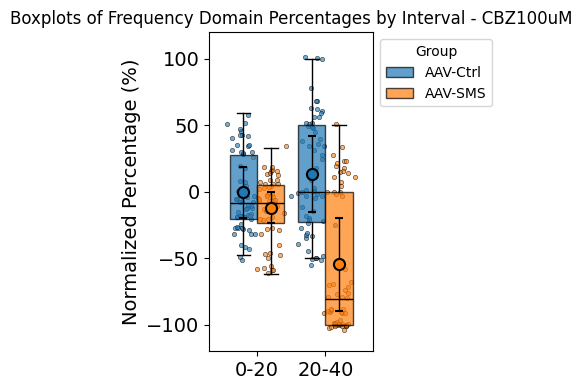

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load summarized data
output_excel_path = r'D:------------\cMOS_Analysis_CBZ01\05_07_NormRHperBin_01.xlsx'
results_df = pd.read_excel(output_excel_path)

# Directory to save plots and data
save_dir = r'D:------------\0000_SelectedConditions\Selected_05Plots_05_FreqDomainsConditions'
os.makedirs(save_dir, exist_ok=True)

# Step 1: Process Freq_Domain_Percentages_Norm dictionary for each sample to create a new DataFrame
freq_data = []
for idx, row in results_df.iterrows():
    if row.get('File Name') != '20240812_18389_01':
        group = row['Group']
        condition = row['Condition']  # Use Condition instead of dpi
        sample_id = int(row['Sample_ID'])
        
        # Parse the pre-normalized frequency domain percentages
        freq_domain_dict = eval(row['Freq_Domain_Percentages_Norm'])
        freq_data.append({
            'Group': group, 'Condition': condition, 'Sample_ID': sample_id,
            **{int(k.strip('Hz')): float(v.strip('%')) for k, v in freq_domain_dict.items()}
        })

# Convert to DataFrame
normalized_df = pd.DataFrame(freq_data)

# Step 2: Filter out specific Sample_ID if needed
normalized_df_filtered = normalized_df[normalized_df['Sample_ID'] != 18574]

# Define condition order and treat 'Condition' as a categorical variable with specified order
condition_order = ['Baseline', 'CBZ30uM','CBZ100uM']
normalized_df_filtered['Condition'] = pd.Categorical(
    normalized_df_filtered['Condition'], categories=condition_order, ordered=True
)

# Step 3: Select only frequency columns with integer names less than 41
frequency_columns = normalized_df_filtered.columns[3:]
frequency_columns = [col for col in frequency_columns if isinstance(col, int) and col < 41]

# Step 4: Define intervals for frequency bins
bins = np.arange(0, 41, 20)

# Initialize a dictionary to hold pooled data for each condition
pooled_data = []
export_data_dict = {}

# Iterate over the defined frequency intervals
for i in range(len(bins) - 1):
    lower_bound = bins[i]
    upper_bound = bins[i + 1]
    
    # Select frequency columns in the current interval
    interval_columns = [col for col in frequency_columns if lower_bound <= col < upper_bound]
    
    if interval_columns:
        for group in normalized_df_filtered['Group'].unique():
            for condition in condition_order:
                group_condition_data = normalized_df_filtered[
                    (normalized_df_filtered['Group'] == group) & 
                    (normalized_df_filtered['Condition'] == condition)
                ]
                
                if not group_condition_data.empty:
                    frequency_data = group_condition_data[interval_columns]
                    mean_value = frequency_data.mean().mean()
                    
                    pooled_data.append({
                        'Frequency Interval': f'{lower_bound}-{upper_bound}',
                        'Group': group,
                        'Condition': condition,
                        'Mean': mean_value,
                        'SD': frequency_data.std().mean(),
                        'SEM': frequency_data.std(ddof=1).mean() / np.sqrt(frequency_data.count().mean()),
                        'Data': frequency_data.values.flatten()
                    })
                    
                    # Export individual data points for each sample
                    for _, sample_row in group_condition_data.iterrows():
                        sample_id = sample_row['Sample_ID']
                        key = (sample_id, condition, group)
                        if key not in export_data_dict:
                            export_data_dict[key] = {'Group': group, 'Sample_ID': sample_id, 'Condition': condition}
                        
                        # Store individual data points instead of the mean
                        for column in interval_columns:
                            export_data_dict[key][f'{column} Hz'] = sample_row[column]

# Convert pooled data to DataFrame
pooled_df = pd.DataFrame(pooled_data)

# Convert export data to DataFrame
export_df = pd.DataFrame.from_dict(export_data_dict, orient='index').reset_index(drop=True)

# Step 5: Plotting separate boxplots for each condition
colors = {
    'AAV-Ctrl': '#1f77b4',  # Blue
    'AAV-SMS': '#ff7f0e'    # Orange
}

# Plot each condition separately
for condition in condition_order:
    fig, ax = plt.subplots(figsize=(4, 4))

    # Filter data for the current condition
    condition_data = pooled_df[pooled_df['Condition'] == condition]
    unique_intervals = condition_data['Frequency Interval'].unique()
    positions = np.arange(1, len(unique_intervals) + 1)
    
    # Create boxplots for each frequency interval within this condition
    for i, interval in enumerate(unique_intervals):
        interval_data = condition_data[condition_data['Frequency Interval'] == interval]
        box_data = []
        means = []  # To store mean values for plotting
        sems = []   # To store SEM values for plotting
        
        for group in interval_data['Group'].unique():
            data = interval_data[interval_data['Group'] == group]['Data'].values[0]
            box_data.append(data)
            means.append(np.mean(data))  # Calculate mean for the group
            sems.append(interval_data[interval_data['Group'] == group]['SEM'].values[0])  # Get SEM for the group

        box_positions = positions[i] + np.linspace(-0.2, 0.2, len(box_data))
        bp = ax.boxplot(box_data, positions=box_positions, widths=0.4, patch_artist=True)
        
        for patch, group in zip(bp['boxes'], interval_data['Group']):
            patch.set_facecolor(colors[group])
            patch.set_alpha(0.7)

        for median in bp['medians']:
            median.set_color('black')
            median.set_linewidth(1)

        # Plot individual data points as scatter plot
        for j, group in enumerate(interval_data['Group'].unique()):
            data_points = interval_data[interval_data['Group'] == group]['Data'].values[0]
            jittered_x = np.full(data_points.shape, box_positions[j]) + np.random.normal(0, 0.1, size=data_points.shape)
            jittered_y = data_points + np.random.normal(0, 2, size=data_points.shape)
            ax.scatter(jittered_x, jittered_y, alpha=0.6, color=colors[group], edgecolor='black', linewidth=0.5, s=10)

        # Plot Mean ± SEM with circle
        for j, (mean_value, sem_value) in enumerate(zip(means, sems)):
            ax.errorbar(box_positions[j], mean_value, yerr=sem_value, fmt='o', 
                        color=colors[interval_data['Group'].unique()[j]], 
                        ecolor='black', elinewidth=1, capsize=3, markersize=8, 
                        markeredgewidth=1.5, markeredgecolor='black')
    
    # Customize plot
    ax.set_xticks(positions)
    ax.set_xticklabels(unique_intervals)
    plt.ylim(-120, 120)

    # Optional: Adjust tick label font sizes
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    ax.set_ylabel('Normalized Percentage (%)', fontsize=14)
    ax.set_title(f'Boxplots of Frequency Domain Percentages by Interval - {condition}')
    ax.legend(colors.keys(), title="Group", loc='upper left', bbox_to_anchor=(1, 1))

    # Save plot
    save_path = os.path.join(save_dir, f'Freq_Domain_{condition}_20HzIntervals.pdf')
    plt.tight_layout()
    plt.savefig(save_path, format='pdf')
    plt.show()
    plt.close(fig)

# Step 6: Export data to Excel
export_excel_path = os.path.join(save_dir, 'Freq_Domain_Norm_IndividualData_20HzIntervals.xlsx')
export_df.to_excel(export_excel_path, index=False)


<p style="font-size: 24px; font-weight: bold; color: Black;"> 05_09_PlotsNet_FreqDomains Normalized Freq_Domain_Norm_5HzIntervals  ---- Outliers Removed 
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- Uses NFreq_Domain_Percentage_Norm data, split them into 5Hz intervals (0 to 35Hz included) </span>
</p>
<p style="margin: 0;">
    <span style="font-size: 22px; color: blue;">- The new excel file containing the data of each Freq interval in each dpi is generated  </span>
</p>

C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_66988\1031934890.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  normalized_df_filtered['Condition'] = pd.Categorical(


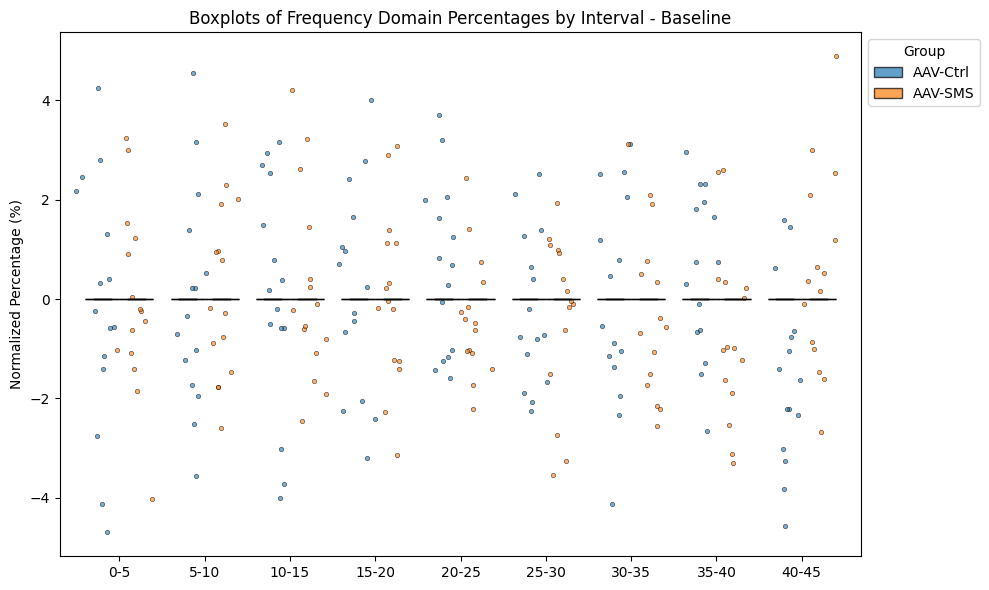

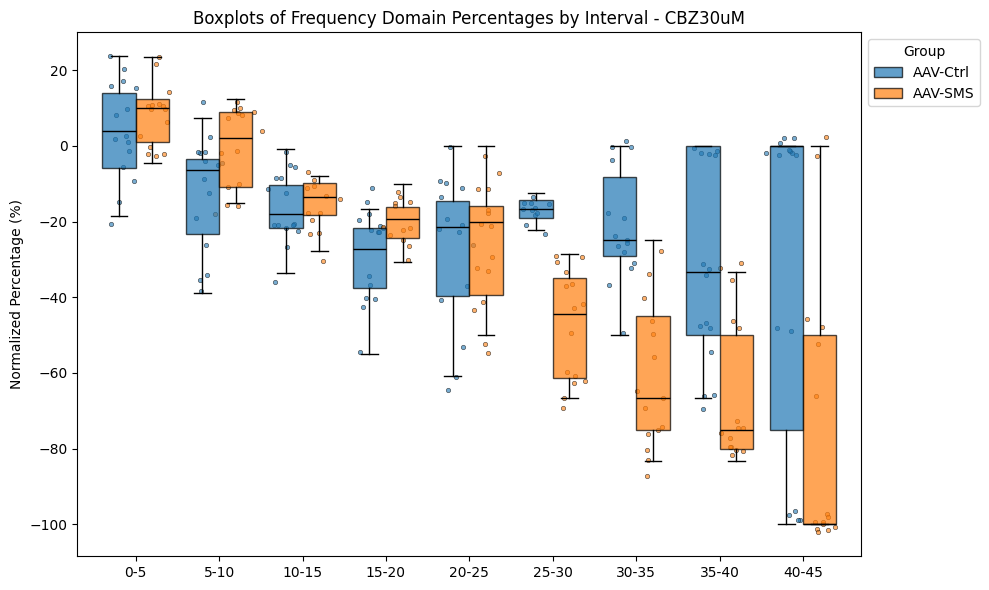

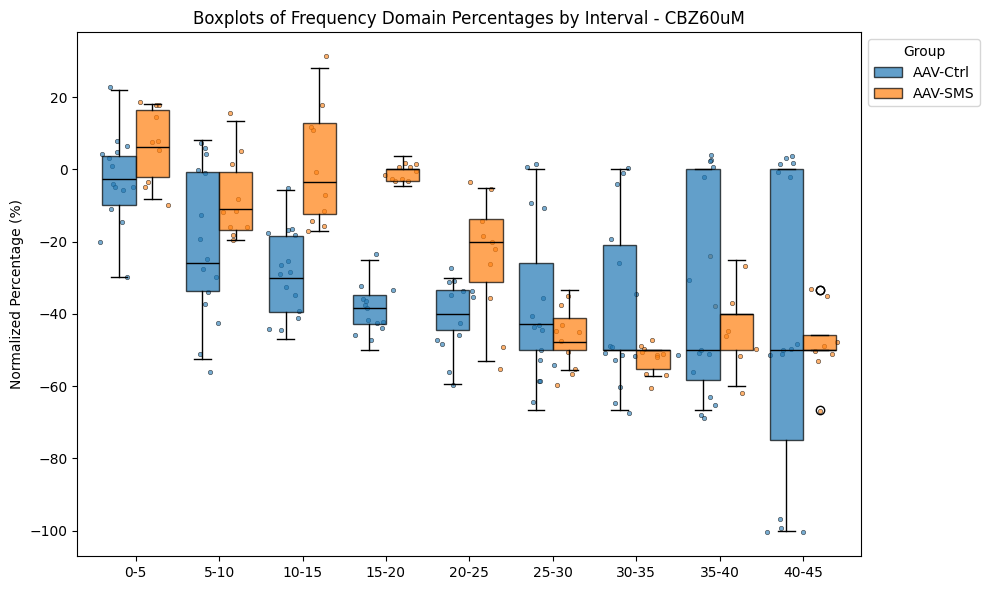

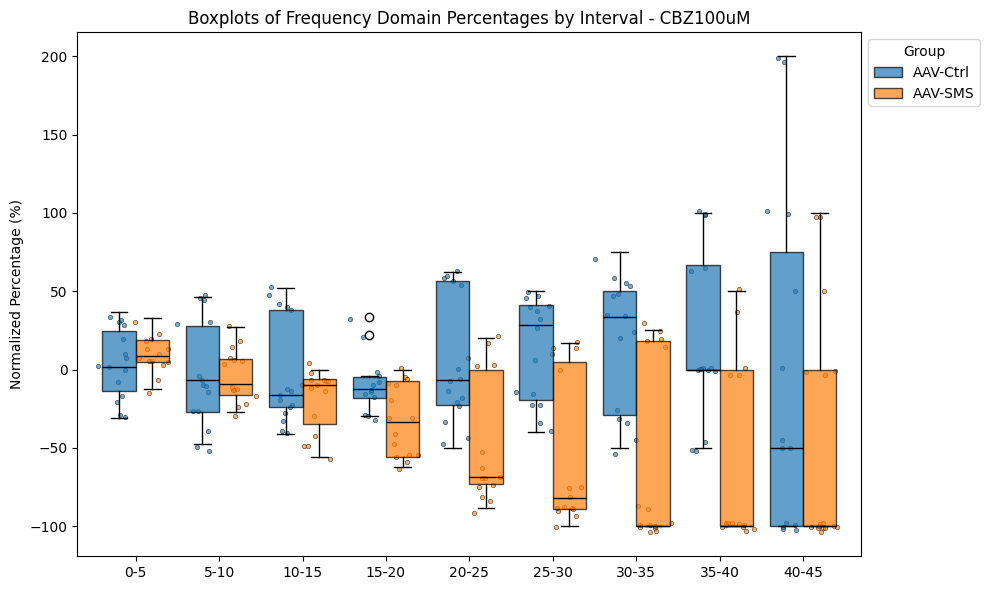

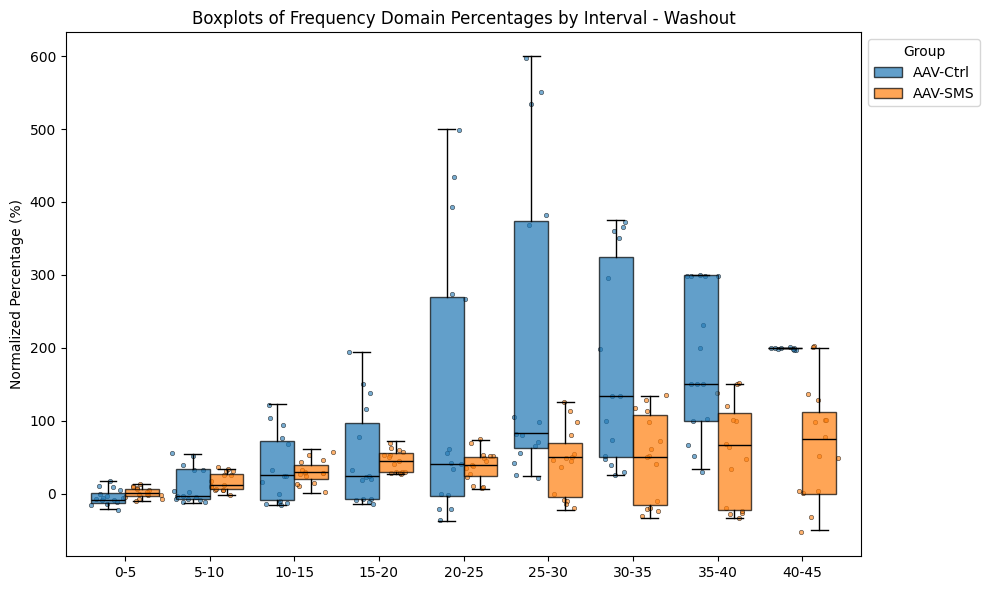

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load summarized data
output_excel_path = r'D:------------\05_07_NormRHperBin_01.xlsx'
results_df = pd.read_excel(output_excel_path)

# Directory to save plots and data
save_dir = r'D:v\05Plots_09_NormFreqDomainsConditions_intervals_outliersremoved'
os.makedirs(save_dir, exist_ok=True)

# Step 1: Process Freq_Domain_Percentages_Norm dictionary for each sample to create a new DataFrame
freq_data = []
for idx, row in results_df.iterrows():
    if row.get('File Name') != '20240812_18389_01':
        group = row['Group']
        condition = row['Condition']
        sample_id = int(row['Sample_ID'])
        
        # Parse the pre-normalized frequency domain percentages
        freq_domain_dict = eval(row['Freq_Domain_Percentages_Norm'])
        freq_data.append({
            'Group': group, 'Condition': condition, 'Sample_ID': sample_id,
            **{int(k.strip('Hz')): float(v.strip('%')) for k, v in freq_domain_dict.items()}
        })

# Convert to DataFrame
normalized_df = pd.DataFrame(freq_data)

# Step 2: Filter out specific Sample_ID if needed
normalized_df_filtered = normalized_df[normalized_df['Sample_ID'] != 18574]

# Define condition order and treat 'Condition' as a categorical variable with specified order
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']
normalized_df_filtered['Condition'] = pd.Categorical(
    normalized_df_filtered['Condition'], categories=condition_order, ordered=True
)

# Step 3: Select only frequency columns with integer names less than 35
frequency_columns = normalized_df_filtered.columns[3:]
frequency_columns = [col for col in frequency_columns if isinstance(col, int) and col < 46]

# Step 4: Define intervals for frequency bins
bins = np.arange(0, 46, 5)

# Initialize a dictionary to hold pooled data for each condition
pooled_data = []
export_data_dict = {}

# Iterate over the defined frequency intervals
for i in range(len(bins) - 1):
    lower_bound = bins[i]
    upper_bound = bins[i + 1]
    
    # Select frequency columns in the current interval
    interval_columns = [col for col in frequency_columns if lower_bound <= col < upper_bound]
    
    if interval_columns:
        for group in normalized_df_filtered['Group'].unique():
            for condition in condition_order:
                group_condition_data = normalized_df_filtered[
                    (normalized_df_filtered['Group'] == group) & 
                    (normalized_df_filtered['Condition'] == condition)
                ]
                
                if not group_condition_data.empty:
                    # Collect all data points within this interval across all samples
                    all_data_points = group_condition_data[interval_columns].values.flatten()
                    
                    # Apply IQR method to remove outliers on all data points within this interval
                    Q1 = np.percentile(all_data_points, 25)
                    Q3 = np.percentile(all_data_points, 75)
                    IQR = Q3 - Q1
                    non_outlier_data = all_data_points[(all_data_points >= Q1 - 1.5 * IQR) & (all_data_points <= Q3 + 1.5 * IQR)]
                    
                    # Calculate summary statistics on the non-outlier data points
                    mean_value = np.mean(non_outlier_data)
                    sd_value = np.std(non_outlier_data)
                    sem_value = sd_value / np.sqrt(len(non_outlier_data))
                    
                    pooled_data.append({
                        'Frequency Interval': f'{lower_bound}-{upper_bound}',
                        'Group': group,
                        'Condition': condition,
                        'Mean': mean_value,
                        'SD': sd_value,
                        'SEM': sem_value,
                        'Data': non_outlier_data  # Store individual data points
                    })
                    
                    # Export data for Excel
                    for _, sample_row in group_condition_data.iterrows():
                        sample_id = sample_row['Sample_ID']
                        key = (sample_id, condition, group)
                        if key not in export_data_dict:
                            export_data_dict[key] = {'Group': group, 'Sample_ID': sample_id, 'Condition': condition}
                        export_data_dict[key][f'{lower_bound}-{upper_bound} Hz'] = sample_row[interval_columns].mean()

# Convert pooled data to DataFrame
pooled_df = pd.DataFrame(pooled_data)

# Convert export data to DataFrame
export_df = pd.DataFrame.from_dict(export_data_dict, orient='index').reset_index(drop=True)

# Step 5: Plotting separate boxplots for each condition
colors = {
    'AAV-Ctrl': '#1f77b4',  # Blue
    'AAV-SMS': '#ff7f0e'    # Orange
}

# Plot each condition separately
for condition in condition_order:
    fig, ax = plt.subplots(figsize=(10, 6))

    # Filter data for the current condition
    condition_data = pooled_df[pooled_df['Condition'] == condition]
    unique_intervals = condition_data['Frequency Interval'].unique()
    positions = np.arange(1, len(unique_intervals) + 1)
    
    # Create boxplots for each frequency interval within this condition
    for i, interval in enumerate(unique_intervals):
        interval_data = condition_data[condition_data['Frequency Interval'] == interval]
        box_data = []
        
        for group in interval_data['Group'].unique():
            data = interval_data[interval_data['Group'] == group]['Data'].values[0]
            box_data.append(data)
        
        box_positions = positions[i] + np.linspace(-0.2, 0.2, len(box_data))
        bp = ax.boxplot(box_data, positions=box_positions, widths=0.4, patch_artist=True)
        
        for patch, group in zip(bp['boxes'], interval_data['Group']):
            patch.set_facecolor(colors[group])
            patch.set_alpha(0.7)

        for median in bp['medians']:
            median.set_color('black')
            median.set_linewidth(1)

        for j, group in enumerate(interval_data['Group'].unique()):
            data_points = interval_data[interval_data['Group'] == group]['Data'].values[0]
            jittered_x = np.full(data_points.shape, box_positions[j]) + np.random.normal(0, 0.1, size=data_points.shape)
            jittered_y = data_points + np.random.normal(0, 2, size=data_points.shape)
            ax.scatter(jittered_x, jittered_y, alpha=0.6, color=colors[group], edgecolor='black', linewidth=0.5, s=10)

    # Customize plot
    ax.set_xticks(positions)
    ax.set_xticklabels(unique_intervals)
    ax.set_ylabel('Normalized Percentage (%)')
    ax.set_title(f'Boxplots of Frequency Domain Percentages by Interval - {condition}')
    ax.legend(colors.keys(), title="Group", loc='upper left', bbox_to_anchor=(1, 1))

    # Save plot
    save_path = os.path.join(save_dir, f'Freq_Domain_{condition}_5HzIntervals.pdf')
    plt.tight_layout()
    plt.savefig(save_path, format='pdf')
    plt.show()
    plt.close(fig)

# Step 6: Export data to Excel
export_excel_path = os.path.join(save_dir, 'Freq_Domain_Norm_5HzIntervals_outliersremoved.xlsx')
export_df.to_excel(export_excel_path, index=False)



<p style="font-size: 50px; font-weight: bold; color: Black;">  Connectivity Analysis

<p style="font-size: 26px; font-weight: bold; color: Black;">  Tau shift calculation

In [ ]:
import pandas as pd
import numpy as np
from scipy.signal import correlate
import os
import pickle
import zipfile
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# Define paths
pickle_file_path = r'D:\------------\cMOS_Analysis_Baseline\01_UnitPos_TimSeries_merged_01.pkl'  # Update with your pickle file path
output_excel_path = r'D:\------------Tau_Calculations\Tau_Shift_Analysis\Tau Shift All\tau_matrices.xlsx'
output_pdf_dir = r'D:\------------\Tau_Calculations\Tau_Shift_Analysis\Tau Shift All\Tau_Plots'
os.makedirs(output_pdf_dir, exist_ok=True)

# Create an Excel writer to save results
writer = pd.ExcelWriter(output_excel_path, engine='openpyxl')

# Sampling frequency
sampling_frequency = 1  # Hz

# Function to calculate tau matrix for each sample
def calculate_tau_matrix(timeseries_data, neuron_ids, sampling_frequency):
    num_neurons = len(neuron_ids)
    tau_matrix = np.zeros((num_neurons, num_neurons))
    
    # Convert spike times to the correct scale
    spike_trains = {neuron: np.array(times) / sampling_frequency for neuron, times in timeseries_data.items()}
    
    for i in range(num_neurons):
        for j in range(i + 1, num_neurons):
            spike_times_i = spike_trains[neuron_ids[i]]
            spike_times_j = spike_trains[neuron_ids[j]]
            
            # Binning spike trains
            bin_size = 0.01  # 10 ms
            max_time = max(spike_times_i.max(), spike_times_j.max())
            bin_edges = np.arange(0, max_time + bin_size, bin_size)
            
            binned_train_i, _ = np.histogram(spike_times_i, bins=bin_edges)
            binned_train_j, _ = np.histogram(spike_times_j, bins=bin_edges)
            
            # Calculate cross-correlation
            cross_corr = correlate(binned_train_i - np.mean(binned_train_i),
                                   binned_train_j - np.mean(binned_train_j), mode='full')
            lags = np.arange(-len(binned_train_i) + 1, len(binned_train_i))
            tau = lags[np.argmax(np.abs(cross_corr))] * bin_size
            
            tau_matrix[i, j] = tau
            tau_matrix[j, i] = -tau
            
    return tau_matrix

# Function to process each sample
def process_sample(data, sample_id, dpi, writer):
    # Filter the data for this sample and dpi
    sample_data = data[(data['Sample_ID'] == sample_id) & (data['dpi'] == dpi)]
    neuron_ids = sample_data['unit_id'].astype(str).tolist()
    timeseries_data = {str(row['unit_id']): row['Timeseries'] for _, row in sample_data.iterrows()}
    
    # Calculate tau matrix
    tau_matrix = calculate_tau_matrix(timeseries_data, neuron_ids, sampling_frequency)
    
    # Save tau matrix to Excel
    sheet_name = f'Sample_{sample_id}_dpi_{dpi}'
    tau_df = pd.DataFrame(tau_matrix, index=neuron_ids, columns=neuron_ids)
    tau_df.to_excel(writer, sheet_name=sheet_name)
    
    # Plot and save tau matrices
    pdf_path = os.path.join(output_pdf_dir, f'{sheet_name}.pdf')
    with PdfPages(pdf_path) as pdf:
        plt.figure(figsize=(14, 6))
        
        # Original tau matrix plot
        plt.subplot(1, 2, 1)
        plt.imshow(tau_matrix, cmap='coolwarm', interpolation='none', aspect='auto')
        plt.colorbar(label='Time Shift (Tau) in seconds')
        plt.xticks(ticks=np.arange(len(neuron_ids)), labels=neuron_ids, rotation=90)
        plt.yticks(ticks=np.arange(len(neuron_ids)), labels=neuron_ids)
        plt.title(f'Time Shift (Tau) - {sheet_name}')
        
        # Thresholded tau matrix plot
        threshold_matrix = np.where((tau_matrix >= -0.01) & (tau_matrix <= 0.01), 1, np.nan)
        
        plt.subplot(1, 2, 2)
        plt.imshow(threshold_matrix, cmap='gray', interpolation='none', aspect='auto')
        plt.colorbar(label='Tau within [-10ms, 10ms]')
        plt.xticks(ticks=np.arange(len(neuron_ids)), labels=neuron_ids, rotation=90)
        plt.yticks(ticks=np.arange(len(neuron_ids)), labels=neuron_ids)
        plt.title(f'Thresholded Tau - {sheet_name}')
        
        plt.tight_layout()
        pdf.savefig()
        plt.close()

# Load data from zipped pickle file
with zipfile.ZipFile(pickle_file_path, 'r') as zip_file:
    with zip_file.open(zip_file.namelist()[0]) as file:
        data = pickle.load(file)

# Convert loaded data to DataFrame
data = pd.DataFrame(data)

# Iterate over unique Sample_ID and dpi combinations
for (sample_id, dpi) in data[['Sample_ID', 'dpi']].drop_duplicates().itertuples(index=False):
    process_sample(data, sample_id, dpi, writer)

# Save the Excel file
writer.close()
print(f"Tau matrices and plots have been saved.")

<p style="font-size: 26px; font-weight: bold; color: Black;">  Tau shift calculation with matrix export for many samples in pickle file

In [ ]:
## The code performs both crosscorrelation and Granger casuality tests and exports data into two .csv files 

import os
import gzip
import pickle
import pandas as pd
import numpy as np
from scipy.signal import correlate
from statsmodels.tsa.vector_ar.var_model import VAR

def bin_timeseries(timeseries, bin_size=0.05, total_time=600):
    """
    Consider that the timeseries have been or have not been modifed based on sampling frequency
    timeseries: list of spike times for a single neuron.
    bin_size: bin width in ms (default 50 ms).
    total_time: total duration in s (600 seconds).
    """
    num_bins = int(total_time // bin_size) # Ensure this is an integer
    binned_series = np.zeros(num_bins)
    for spike_time in timeseries:
        bin_idx = int(spike_time // bin_size)
        if bin_idx < num_bins:
            binned_series[bin_idx] += 1
    return binned_series
    
def smooth_data(data, window_size=5):
    """
    Smooth the data using a simple moving average.
    data: binned spike counts.
    window_size: the size of the moving average window.
    """
    return np.convolve(data, np.ones(window_size)/window_size, mode='same')
    
def calculate_cross_correlation_matrix(binned_data):
    """
    Calculate the cross-correlation matrix for binned spike data.
    """
    num_neurons = len(binned_data)
    cc_matrix = np.zeros((num_neurons, num_neurons))
    
    for i in range(num_neurons):
        for j in range(num_neurons):
            if i != j:
                cc = np.corrcoef(binned_data[i], binned_data[j])[0, 1]
                cc_matrix[i, j] = cc
            else:
                cc_matrix[i, j] = 1  # Perfect correlation with itself
                
    return cc_matrix

def calculate_granger_causality_matrix(binned_data, maxlag=20):   # maxlag = n of bins before that is used to predict upcoming bin
    """
    Calculate the Granger causality matrix for binned spike data.
    MAXLAG: is the max number of bins before that are used for prediction here 20 x 50ms bin = 1000ms before is used to interpret upcoming timepoint 
    Lags: 
      When assessing Granger causality, you are not only looking at the present values of the time series but also their past values (lags). 
      For example, if you set maxlag=10, the model will consider how past values of both time series up to 10 time steps ago influence the current 
      value of the series being predicted.
    Model Complexity: 
      A higher value for maxlag means that the model will use more past values, which can improve prediction accuracy if there is
      significant information in those lags. However, it also increases the complexity of the model and the amount of data required to fit the model 
      reliably.
    Trade-offs: 
    - If maxlag is too high, the model might overfit, especially if the time series is short or if there are not enough data points to 
      reliably estimate the parameters of the model. 
    - If maxlag is too low, you might miss out on important lags that influence the relationship.
    """
    num_neurons = len(binned_data)
    gc_matrix = np.zeros((num_neurons, num_neurons))
    
    for i in range(num_neurons):
        for j in range(num_neurons):
            if i != j:
                combined_data = np.vstack([binned_data[i], binned_data[j]]).T
                model = VAR(combined_data)
                results = model.fit(maxlags=maxlag)
                gc_matrix[i, j] = results.test_causality(0, 1, kind='f').test_statistic
    
    return gc_matrix

def process_and_save_sample(sample_data, group, sample_id, dpi, output_folder, dt, total_time=600):
    """
    Process a single sample, calculate CC and GC matrices, and save as .csv files.
    """
    # Prepare metadata -----------------------------------------------------------------------
    metadata_rows = sample_data[['File Name', 'post_SMS', 'Date', 'x', 'y', 'unit_id']].copy()
    metadata_rows['Group'] = group
    metadata_rows['Sample_ID'] = sample_id
    metadata_rows['dpi'] = dpi
    
    # Prepare spike times per neuron ---------------------------------------------------------
    timeseries_data = {row['unit_id']: row['Timeseries'] for _, row in sample_data.iterrows()}
    binned_data = [bin_timeseries(timeseries_data[neuron], bin_size=dt, total_time=total_time) 
                   for neuron in timeseries_data]
    
    # Smooth the binned data -----------------------------------------------------------------
    smoothed_binned_data = [smooth_data(data) for data in binned_data]

    # Calculate Cross-Correlation Matrix -----------------------------------------------------
    cc_matrix = calculate_cross_correlation_matrix(smoothed_binned_data)
    
    # Calculate Granger Causality Matrix -----------------------------------------------------
    gc_matrix = calculate_granger_causality_matrix(smoothed_binned_data, maxlag=20)
    
    # Convert matrices to DataFrames and combine with metadata -------------------------------
    cc_df = pd.DataFrame(cc_matrix, index=timeseries_data.keys(), columns=timeseries_data.keys())
    gc_df = pd.DataFrame(gc_matrix, index=timeseries_data.keys(), columns=timeseries_data.keys())
    
    # Export CC matrix with metadata ---------------------------------------------------------
    cc_result_df = metadata_rows.set_index('unit_id').join(cc_df, how='right').reset_index()
    cc_output_filename = os.path.join(output_folder, f"{group}_{sample_id}_{dpi}_CC.csv")
    cc_result_df.to_csv(cc_output_filename, index=False)
    print(f"Saved Cross-Correlation results to {cc_output_filename}")
    
    # Export GC matrix with metadata ----------------------------------------------------------
    gc_result_df = metadata_rows.set_index('unit_id').join(gc_df, how='right').reset_index()
    gc_output_filename = os.path.join(output_folder, f"{group}_{sample_id}_{dpi}_GC.csv")
    gc_result_df.to_csv(gc_output_filename, index=False)
    print(f"Saved Granger Causality results to {gc_output_filename}")

def main(input_pickle_path, output_folder, dt=0.05):
    # Load the gzip-compressed pickle file
    with gzip.open(input_pickle_path, 'rb') as f:
        data = pickle.load(f)

    print("Data loaded, shape:", data.shape)

    # Process each unique combination of Group, Sample_ID, and dpi
    for group in data['Group'].unique():
        group_data = data[data['Group'] == group]
        
        for sample_id in group_data['Sample_ID'].unique():
            sample_data = group_data[group_data['Sample_ID'] == sample_id]
            
            for dpi in sample_data['dpi'].unique():
                dpi_data = sample_data[sample_data['dpi'] == dpi]
                
                # Process and save results for this sample and dpi
                process_and_save_sample(dpi_data, group, sample_id, dpi, output_folder, dt)

# Set your paths
input_pickle_path = r'D:------------_SI_files\ExtraFiles\cMOS_Analysis_Baseline\CCGC_Baseline_SMS\01_UnitPos_TimSeries_merged_ex.pkl.gz'
output_folder = r'D:\------------SI_files\ExtraFiles\cMOS_Analysis_Baseline\CCGC_Baseline_SMS\00_CCGC_Matrices'
os.makedirs(output_folder, exist_ok=True)

main(input_pickle_path, output_folder)


Data loaded, shape: (2189, 10)


KeyboardInterrupt: 

<p style="font-size: 30px; font-weight: bold; color: Black;"> 06_01_Crosscorrelation (+/- correlations)  &  Granger casuality (directionality <-->)
<p style="font-size: 28px; font-weight: bold; color: Black;"> CBZ
<p style="font-size: 20px; font-weight: bold; color: Black;"> Applys parallelization to spedd up the process
<p style="font-size: 20px; font-weight: bold; color: Black;"> With Neuron number selection options (random selection)
<p style="font-size: 20px; font-weight: bold; color: Black;"> With sample selection options

In [ ]:
import os
import gzip
import pickle
import pandas as pd
import numpy as np
from scipy.signal import correlate
from joblib import Parallel, delayed
from statsmodels.tsa.vector_ar.var_model import VAR
from scipy.stats import pearsonr

def bin_timeseries(timeseries, bin_size=0.05, total_time=600):
    num_bins = int(total_time // bin_size)
    binned_series = np.zeros(num_bins)
    for spike_time in timeseries:
        bin_idx = int(spike_time // bin_size)
        if bin_idx < num_bins:
            binned_series[bin_idx] += 1
    return binned_series

def smooth_data(data, window_size=5):
    return np.convolve(data, np.ones(window_size) / window_size, mode='same')

def calculate_cross_correlation_row(i, binned_data):
    num_neurons = len(binned_data)
    cc_row = np.zeros(num_neurons)
    for j in range(num_neurons):
        if i != j:
            cc_row[j] = pearsonr(binned_data[i], binned_data[j])[0]
        else:
            cc_row[j] = 1
    return cc_row

def calculate_cross_correlation_matrix(binned_data):
    num_neurons = len(binned_data)
    cc_matrix = Parallel(n_jobs=-1)(delayed(calculate_cross_correlation_row)(i, binned_data)
                                    for i in range(num_neurons))
    return np.array(cc_matrix)

def calculate_granger_causality_row(i, binned_data, maxlag=20):
    num_neurons = len(binned_data)
    gc_stat_row = np.zeros(num_neurons)
    gc_pval_row = np.zeros(num_neurons)
    for j in range(num_neurons):
        if i != j:
            combined_data = np.vstack([binned_data[i], binned_data[j]]).T
            model = VAR(combined_data)
            results = model.fit(maxlags=maxlag)
            test_result = results.test_causality(0, 1, kind='f')
            gc_stat_row[j] = test_result.test_statistic
            gc_pval_row[j] = test_result.pvalue
    return gc_stat_row, gc_pval_row

def calculate_granger_causality_matrix(binned_data, maxlag=20):
    num_neurons = len(binned_data)
    results = Parallel(n_jobs=-1)(delayed(calculate_granger_causality_row)(i, binned_data, maxlag)
                                  for i in range(num_neurons))
    gc_stat_matrix, gc_pval_matrix = zip(*results)
    return np.array(gc_stat_matrix), np.array(gc_pval_matrix)

def process_and_save_sample(sample_data, group, sample_id, condition, output_folder, dt, total_time=600, max_neurons=500):
    metadata_rows = sample_data[['File Name', 'post_SMS', 'Date', 'x', 'y', 'unit_id']].copy()
    metadata_rows['Group'] = group
    metadata_rows['Sample_ID'] = sample_id
    metadata_rows['Condition'] = condition
    
    # Extract timeseries data and limit to max_neurons if necessary
    timeseries_data = {row['unit_id']: row['Timeseries'] for _, row in sample_data.iterrows()}
    if len(timeseries_data) > max_neurons:
        selected_neurons = np.random.choice(list(timeseries_data.keys()), max_neurons, replace=False)
        timeseries_data = {neuron: timeseries_data[neuron] for neuron in selected_neurons}
    
    binned_data = [bin_timeseries(timeseries_data[neuron], bin_size=dt, total_time=total_time) 
                   for neuron in timeseries_data]
    smoothed_binned_data = [smooth_data(data) for data in binned_data]

    cc_matrix = calculate_cross_correlation_matrix(smoothed_binned_data)
    gc_matrix, gc_pval_matrix = calculate_granger_causality_matrix(smoothed_binned_data, maxlag=20)
    
    cc_df = pd.DataFrame(cc_matrix, index=timeseries_data.keys(), columns=timeseries_data.keys())
    gc_df = pd.DataFrame(gc_matrix, index=timeseries_data.keys(), columns=timeseries_data.keys())
    gc_pval_df = pd.DataFrame(gc_pval_matrix, index=timeseries_data.keys(), columns=timeseries_data.keys())
    
    cc_result_df = metadata_rows.set_index('unit_id').join(cc_df, how='right').reset_index()
    cc_output_filename = os.path.join(output_folder, f"{group}_{sample_id}_{condition}_CC.csv")
    cc_result_df.to_csv(cc_output_filename, index=False)
    
    gc_result_df = metadata_rows.set_index('unit_id').join(gc_df, how='right').reset_index()
    gc_output_filename = os.path.join(output_folder, f"{group}_{sample_id}_{condition}_GC.csv")
    gc_result_df.to_csv(gc_output_filename, index=False)

    gc_pval_result_df = metadata_rows.set_index('unit_id').join(gc_pval_df, how='right').reset_index()
    gc_pval_output_filename = os.path.join(output_folder, f"{group}_{sample_id}_{condition}_GC_pvalues.csv")
    gc_pval_result_df.to_csv(gc_pval_output_filename, index=False)
    
    print(f"Saved Cross-Correlation, Granger Causality, and p-value results for {group}, sample {sample_id}, condition {condition}")

# Update exclusion criteria if needed; otherwise, remove it if it's not applicable to `Condition`
exclude_criteria = [
    {'Sample_ID': '18389', 'Condition': ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']}, 
    #{'Sample_ID': '18406', 'Condition': ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']},
    #{'Sample_ID': '18581', 'Condition': ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']},
    {'Sample_ID': '18505', 'Condition': ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']},
    {'Sample_ID': '20810', 'Condition': ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']},
    {'Sample_ID': '18574', 'Condition': ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']},
]

def should_exclude(sample_id, condition, exclude_criteria):
    for criterion in exclude_criteria:
        if criterion['Sample_ID'] == sample_id and condition in criterion['Condition']:
            print(sample_id, condition, 'excluded')
            return True
    return False

def main(input_pickle_path, output_folder, dt=0.05):
    with gzip.open(input_pickle_path, 'rb') as f:
        data = pickle.load(f)

    print("Data loaded, shape:", data.shape)

    for group in data['Group'].unique():
        group_data = data[data['Group'] == group]
        
        for sample_id in group_data['Sample_ID'].unique():
            sample_data = group_data[group_data['Sample_ID'] == sample_id]
            
            for condition in sample_data['Condition'].unique():
                condition_data = sample_data[sample_data['Condition'] == condition]
                
                if should_exclude(sample_id, condition, exclude_criteria):
                    print(f"Skipping Sample_ID {sample_id} with condition {condition} due to exclusion criteria.")
                    continue

                process_and_save_sample(condition_data, group, sample_id, condition, output_folder, dt)

input_pickle_path = r'D:------------files\ExtraFiles\cMOS_Analysis_CBZ01\03_UnitPos_TimSeries_CBZ_01.pkl.gz'
output_folder = r'D:\------------SI_files\ExtraFiles\cMOS_Analysis_CBZ01\06_GCCC_CBZ_Matrices_01'
os.makedirs(output_folder, exist_ok=True)

main(input_pickle_path, output_folder)


Data loaded, shape: (16584, 11)
18389 Baseline excluded
Skipping Sample_ID 18389 with condition Baseline due to exclusion criteria.
18389 CBZ30uM excluded
Skipping Sample_ID 18389 with condition CBZ30uM due to exclusion criteria.
18389 CBZ60uM excluded
Skipping Sample_ID 18389 with condition CBZ60uM due to exclusion criteria.
18389 CBZ100uM excluded
Skipping Sample_ID 18389 with condition CBZ100uM due to exclusion criteria.
18389 Washout excluded
Skipping Sample_ID 18389 with condition Washout due to exclusion criteria.
18505 Baseline excluded
Skipping Sample_ID 18505 with condition Baseline due to exclusion criteria.
18505 CBZ30uM excluded
Skipping Sample_ID 18505 with condition CBZ30uM due to exclusion criteria.
18505 CBZ60uM excluded
Skipping Sample_ID 18505 with condition CBZ60uM due to exclusion criteria.
18505 CBZ100uM excluded
Skipping Sample_ID 18505 with condition CBZ100uM due to exclusion criteria.
18505 Washout excluded
Skipping Sample_ID 18505 with condition Washout due to 

<p style="font-size: 30px; font-weight: bold; color: Black;"> 07_01_Measure of Connectivity parameters 01

<p style="font-size: 16px; font-weight: bold; color: Black;"> Measurement of Fast connectivity metrices (metrices that can be calcuated faster) in network 
<p style="font-size: 20px; font-weight: bold; color: Black;"> Neuron_Based connectivity measures 
<p style="font-size: 16px; font-weight: bold; color: Black;"> For processing many files
<p style="font-size: 16px; font-weight: bold; color: Black;"> Data of all Neurons, in all Samples and Condition are collected in one .CSV file in one sheet
<p style="font-size: 16px; font-weight: bold; color: Black;"> Later the .csv output of this code will be used for MEA_Based analysis or normalized data 

In [ ]:
import os
import pandas as pd
import numpy as np
import networkx as nx
import community as community_louvain  # Added import for Louvain modularity

# Define the directory containing the CSV files
input_directory = r'D:v_files\ExtraFiles\cMOS_Analysis_CBZ01\GCCC_CBZ_Matrices_01\CC'
output_file = r'D:------------is\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\07_00_Net_Params_Combined.csv'

# Get the list of CSV files in the directory
csv_files = [f for f in os.listdir(input_directory) if f.endswith('.csv')]

# List to store each processed DataFrame
all_results = []

# Loop through each CSV file in the directory
for file_name in csv_files:
    # Step 1: Load the CSV file and preprocess it
    file_path = os.path.join(input_directory, file_name)
    data = pd.read_csv(file_path)

    # Step 2: Extract correlation matrix and metadata
    metadata_columns = data.columns[:data.columns.get_loc("Condition") + 1]
    metadata = data[metadata_columns]
    correlation_matrix = data.drop(columns=metadata_columns)

    # Step 3: Preprocess the correlation matrix
    np.fill_diagonal(correlation_matrix.values, 0)
    correlation_matrix = pd.DataFrame(np.where(correlation_matrix <= 0.3, 0, correlation_matrix), 
                                  columns=correlation_matrix.columns, 
                                  index=correlation_matrix.index)

    # Step 4: Create a NetworkX graph from the correlation matrix
    G = nx.from_numpy_array(correlation_matrix.values)
    for u, v, data in G.edges(data=True):
        data['weight'] = correlation_matrix.iloc[u, v]

    # Step 5: Check if the graph has edges before calculating modularity
    if G.number_of_edges() > 0:
        # Calculate modularity using Louvain method and extract community information
        partition = community_louvain.best_partition(G, weight='weight', resolution=1)
        modularity_value = community_louvain.modularity(partition, G)
    else:
        # Skip modularity calculation for disconnected graphs
        partition = {}
        modularity_value = None

    # Define the function to calculate neuron parameters
    def calculate_neuron_params(G):
        num_nodes = len(G.nodes())
        degree = dict(G.degree(weight=None))
        density = {node: deg / (num_nodes - 1) for node, deg in degree.items()}
        weight_sum = {node: sum(abs(data['weight']) for _, _, data in G.edges(node, data=True)) for node in G.nodes()}
        weight_mean = {node: weight_sum[node] / (num_nodes - 1) for node in G.nodes()}
        clustering_coefficients = nx.clustering(G, weight='weight')
        eigenvector_centrality = nx.eigenvector_centrality(G, weight='weight') if G.number_of_edges() > 0 else {}
        page_rank = nx.pagerank(G, weight='weight') if G.number_of_edges() > 0 else {}
        avg_neighbor_degree = nx.average_neighbor_degree(G, weight='weight') if G.number_of_edges() > 0 else {}
        assortativity = nx.degree_assortativity_coefficient(G, weight='weight') if G.number_of_edges() > 0 else None
        avg_path_length = {}
        for node in G.nodes():
            path_lengths = nx.single_source_dijkstra_path_length(G, node, weight='weight')
            avg_path_length[node] = np.mean(list(path_lengths.values()))
        strength = {node: sum(data['weight'] for _, _, data in G.edges(node, data=True)) for node in G.nodes()}
        closeness_centrality = nx.closeness_centrality(G, distance='weight') if G.number_of_edges() > 0 else {}
        degree_mean = np.mean(list(degree.values()))
        degree_std = np.std(list(degree.values()))
        z_score_degree = {node: (deg - degree_mean) / degree_std for node, deg in degree.items()}
        transitivity = nx.transitivity(G) if G.number_of_edges() > 0 else None

        return {
            'Degree': degree,
            'Density': density,
            'Weight_sum': weight_sum,
            'Weight_mean': weight_mean,
            'Clustering_coefficient': clustering_coefficients,
            'Eigenvector_centrality': eigenvector_centrality,
            'PageRank': page_rank,
            'Average_neighbor_degree': avg_neighbor_degree,
            'Assortativity': assortativity,
            'Average_path_length': avg_path_length,
            'Strength': strength,
            'Closeness_centrality': closeness_centrality,
            'Z_Score_of_Degree': z_score_degree,
            'Transitivity': {node: transitivity for node in G.nodes()},
            'Community': partition,
            'Modularity': {node: modularity_value for node in G.nodes()}
        }

    # Run calculations
    neuron_params = calculate_neuron_params(G)

    # Step 6: Prepare DataFrame for export with metadata and calculated parameters
    neuron_params_df = pd.DataFrame(neuron_params)
    neuron_params_df.index.name = 'Neuron'
    neuron_params_df.reset_index(inplace=True)
    final_df = pd.concat([metadata.reset_index(drop=True), neuron_params_df], axis=1)
    final_df['Source_File'] = file_name

    all_results.append(final_df)

# Concatenate all results into one DataFrame
combined_df = pd.concat(all_results, ignore_index=True)
combined_df.to_csv(output_file, index=False)

print(f"All results successfully saved to {output_file}")



C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_26424\3089072892.py:69: RuntimeWarning: invalid value encountered in scalar divide
  z_score_degree = {node: (deg - degree_mean) / degree_std for node, deg in degree.items()}


All results successfully saved to D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\06_Net_Params_Combined.csv


C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_26424\3089072892.py:104: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined_df = pd.concat(all_results, ignore_index=True)


<p style="font-size: 24px; font-weight: bold; color: Black;"> 07Plots_01_MEABasedConnectivityParams_01    condition ---- CBZ 01 ---- Plot & ---ExcelExport---
<p style="font-size: 16px; font-weight: bold; color: Black;"> The code has been replicated using "04Plots_01_MEABasedBurst_01    condition ---- CBZ 01 ---- Plot & ---ExcelExport---" code

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode

# Load the modified data from the CSV file
csv_file = r'D:---------\\ExtraFiles\cMOS_Analysis_CBZ01\07_00_Net_Params_Combined.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 from the analysis
final_df = final_df[final_df['Sample_ID'] != 18574]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:\-------_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\07Plots_01_MEABasedConnectivityParams_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on (updated with network parameters)
variables = [
    'Degree', 'Density', 'Weight_sum', 'Weight_mean', 'Clustering_coefficient',
    'Eigenvector_centrality', 'PageRank', 'Average_neighbor_degree', 'Assortativity',
    'Average_path_length', 'Strength', 'Closeness_centrality', 'Z_Score_of_Degree',
    'Transitivity', 'Modularity'
]

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Filter out irrelevant rows (if necessary)
filtered_df = final_df  # Adjust filter criteria as needed

# Group by Sample_ID and Condition to calculate statistics for each sample per condition
sample_stats_per_condition = {}

import warnings

# Start of your loop where statistics are calculated
for sample_id in filtered_df['Sample_ID'].unique():
    sample_df = filtered_df[filtered_df['Sample_ID'] == sample_id]
    sample_condition_stats = {}
    
    for condition in sample_df['Condition'].unique():
        condition_df = sample_df[sample_df['Condition'] == condition]
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var].dropna()  # Drop NaN values for calculations
            
            # Check if values are empty, and set all stats to zero if true
            if values.empty:
                mean_val = sdv_val = sem_val = median_val = max_val = min_val = cv_val = 0
                variance_val = percentile_25 = percentile_50 = percentile_75 = 0
                skewness_val = kurtosis_val = mode_val = avg_z_score = 0
            else:
                # Calculate various statistics
                mean_val = values.mean()
                sdv_val = values.std()
                sem_val = sdv_val / np.sqrt(len(values))
                median_val = values.median()
                max_val = values.max()
                min_val = values.min()
                cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
                variance_val = np.var(values)
                percentile_25 = np.percentile(values, 25)
                percentile_50 = np.percentile(values, 50)
                percentile_75 = np.percentile(values, 75)

                # Suppress warnings for precision loss
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", category=RuntimeWarning)
                    # Calculate skewness and kurtosis only if variance is above a threshold
                    if variance_val > 1e-10:
                        skewness_val = skew(values)
                        kurtosis_val = kurtosis(values)
                    else:
                        skewness_val = kurtosis_val = 0  # Assign zero if data is nearly identical

                mode_val = mode(values)[0][0] if isinstance(mode(values)[0], np.ndarray) else mode(values)[0]
                z_scores = (values - mean_val) / sdv_val  # Z-scores for each data point
                avg_z_score = np.mean(z_scores)  # Average Z-score
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score  # Store the average Z-score
            }
        
        sample_condition_stats[condition] = condition_stats
    
    sample_stats_per_condition[sample_id] = sample_condition_stats

# Calculate group averages (e.g., AAV-Ctrl and AAV-SMS) based on sample averages
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_avg_stats = {}
    for condition in group_df['Condition'].unique():
        samples_in_group_condition = [
            sample_stats_per_condition[sample_id][condition] 
            for sample_id in group_df[group_df['Condition'] == condition]['Sample_ID'].unique()
        ]
        condition_group_stats = {}
        
        for var in variables:
            # Calculate mean and SEM per group/condition using the sample averages
            sample_means = [sample[var]['mean'] for sample in samples_in_group_condition]
            mean_val = np.mean(sample_means)
            sem_val = np.std(sample_means) / np.sqrt(len(sample_means))
            
            condition_group_stats[var] = {
                'mean': mean_val,
                'sem': sem_val,
                'sample_means': sample_means  # Store the individual sample means for plotting
            }
        
        group_avg_stats[condition] = condition_group_stats
    
    group_stats[group] = group_avg_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines
for var in variables:
    plt.figure(figsize=(10, 6))
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [group_data[condition][var]['sample_means'] for condition in conditions]

        x_positions = np.arange(len(conditions)) + group_idx * 0.2  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.3,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.5),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.2),
            capprops=dict(color='black', linewidth=0.2),
            flierprops=dict(marker='o', color=color, markersize=5, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1, linestyle='-', 
                 markersize=6, markeredgecolor='black', zorder=2)

        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            plt.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                        alpha=0.7, linewidth=0.2, zorder=3)

    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions')
    plt.xlabel('Condition')
    plt.ylabel(var)
    
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions)
    
    plot_output_path = os.path.join(output_dir, f'{var}_group_comparison_boxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()

# Export the sample averages per Condition to Excel
output_excel_file = r'D:\MEA_Analysis\Rola_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\07_01_MEABasedConnectivityParamsStat_01.xlsx'
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for sample_id, sample_stats in sample_stats_per_condition.items():
            for condition, condition_stats in sample_stats.items():
                metadata_row = filtered_df[filtered_df['Sample_ID'] == sample_id].iloc[0]
                
                var_stats.append({
                    'Group': metadata_row['Group'],
                    'Sample_ID': sample_id,
                    'Date': metadata_row['Date'],
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var[:31], index=False)

print("Code execution completed.")


Code execution completed.


<p style="font-size: 32px; font-weight: bold; color: Green;"> 07Plots_01_MEABasedConnectivityParams_01    condition ---- CBZ 01 ---- Plot & ---ExcelExport---
<p style="font-size: 16px; font-weight: bold; color: Green;"> The code has been replicated using "04Plots_01_MEABasedBurst_01    condition ---- CBZ 01 ---- Plot & ---ExcelExport---" code

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode

# Load the modified data from the CSV file
csv_file = r'D:\----------------_SI_files\ExtraFiles\cMOS_Analysis_CBZ01\07_00_Net_Params_Combined.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 from the analysis
final_df = final_df[final_df['Sample_ID'] != 18574]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:\----------------es\ExtraFiles\cMOS_Analysis_CBZ01\0000_SelectedConditions\Selected_07Plots_01_MEABasedConnectivityParams_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on (updated with network parameters)
variables = [
    'Degree', 'Density', 'Weight_sum', 'Weight_mean', 'Clustering_coefficient',
    'Eigenvector_centrality', 'PageRank', 'Average_neighbor_degree', 'Assortativity',
    'Average_path_length', 'Strength', 'Closeness_centrality', 'Z_Score_of_Degree',
    'Transitivity', 'Modularity'
]

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM','CBZ100uM']

# Filter out irrelevant rows (if necessary)
filtered_df = final_df  # Adjust filter criteria as needed

# Group by Sample_ID and Condition to calculate statistics for each sample per condition
sample_stats_per_condition = {}

import warnings

# Start of your loop where statistics are calculated
for sample_id in filtered_df['Sample_ID'].unique():
    sample_df = filtered_df[filtered_df['Sample_ID'] == sample_id]
    sample_condition_stats = {}
    
    for condition in sample_df['Condition'].unique():
        condition_df = sample_df[sample_df['Condition'] == condition]
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var].dropna()  # Drop NaN values for calculations
            
            # Check if values are empty, and set all stats to zero if true
            if values.empty:
                mean_val = sdv_val = sem_val = median_val = max_val = min_val = cv_val = 0
                variance_val = percentile_25 = percentile_50 = percentile_75 = 0
                skewness_val = kurtosis_val = mode_val = avg_z_score = 0
            else:
                # Calculate various statistics
                mean_val = values.mean()
                sdv_val = values.std()
                sem_val = sdv_val / np.sqrt(len(values))
                median_val = values.median()
                max_val = values.max()
                min_val = values.min()
                cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
                variance_val = np.var(values)
                percentile_25 = np.percentile(values, 25)
                percentile_50 = np.percentile(values, 50)
                percentile_75 = np.percentile(values, 75)

                # Suppress warnings for precision loss
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", category=RuntimeWarning)
                    # Calculate skewness and kurtosis only if variance is above a threshold
                    if variance_val > 1e-10:
                        skewness_val = skew(values)
                        kurtosis_val = kurtosis(values)
                    else:
                        skewness_val = kurtosis_val = 0  # Assign zero if data is nearly identical

                mode_val = mode(values)[0][0] if isinstance(mode(values)[0], np.ndarray) else mode(values)[0]
                z_scores = (values - mean_val) / sdv_val  # Z-scores for each data point
                avg_z_score = np.mean(z_scores)  # Average Z-score
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score  # Store the average Z-score
            }
        
        sample_condition_stats[condition] = condition_stats
    
    sample_stats_per_condition[sample_id] = sample_condition_stats

# Calculate group averages (e.g., AAV-Ctrl and AAV-SMS) based on sample averages
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_avg_stats = {}
    for condition in group_df['Condition'].unique():
        samples_in_group_condition = [
            sample_stats_per_condition[sample_id][condition] 
            for sample_id in group_df[group_df['Condition'] == condition]['Sample_ID'].unique()
        ]
        condition_group_stats = {}
        
        for var in variables:
            # Calculate mean and SEM per group/condition using the sample averages
            sample_means = [sample[var]['mean'] for sample in samples_in_group_condition]
            mean_val = np.mean(sample_means)
            sem_val = np.std(sample_means) / np.sqrt(len(sample_means))
            
            condition_group_stats[var] = {
                'mean': mean_val,
                'sem': sem_val,
                'sample_means': sample_means  # Store the individual sample means for plotting
            }
        
        group_avg_stats[condition] = condition_group_stats
    
    group_stats[group] = group_avg_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines
for var in variables:
    plt.figure(figsize=(4, 6))
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [group_data[condition][var]['sample_means'] for condition in conditions]

        x_positions = np.arange(len(conditions)) + group_idx * 0.25  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.25,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.7, alpha=0.7),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.7),
            capprops=dict(color='black', linewidth=0.7),
            flierprops=dict(marker='o', color=color, markersize=5, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1.5, linestyle='-', 
                 markersize=8, markeredgecolor='black', zorder=2)

        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            plt.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                        alpha=0.7, linewidth=0.2, zorder=3, s=40)

    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions')
    plt.xlabel('Condition', fontsize=14)
    plt.ylabel(var)

    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=14)
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions, fontsize=14)
    
    plot_output_path = os.path.join(output_dir, f'{var}_Boxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()

# Export the sample averages per Condition to Excel
output_excel_file = r'D:----------------aFiles\cMOS_Analysis_CBZ01\0000_SelectedConditions\Selected_07Plots_01_MEABasedConnectivityParams_01\Selected_07_01_MEABasedConnectivityParamsStat_01.xlsx'
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for sample_id, sample_stats in sample_stats_per_condition.items():
            for condition, condition_stats in sample_stats.items():
                metadata_row = filtered_df[filtered_df['Sample_ID'] == sample_id].iloc[0]
                
                var_stats.append({
                    'Group': metadata_row['Group'],
                    'Sample_ID': sample_id,
                    'Date': metadata_row['Date'],
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var[:31], index=False)

print("Code execution completed.")


Code execution completed.


<p style="font-size: 24px; font-weight: bold; color: Black;"> 07Plots_02_Normalized MEABasedConnectivityParams_01    condition ---- CBZ 01 ---- Plot & ---ExcelExport---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode

# Load the modified data from the CSV file
csv_file = r'D:\M----- es\ExtraFiles\cMOS_Analysis_CBZ01\07_00_Net_Params_Combined.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 from the analysis
final_df = final_df[final_df['Sample_ID'] != 18574]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:\------\ExtraFiles\cMOS_Analysis_CBZ01\07Plots_02_NormMEABasedConnectivityParams_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on (updated with network parameters)
variables = [
    'Degree', 'Density', 'Weight_sum', 'Weight_mean', 'Clustering_coefficient',
    'Eigenvector_centrality', 'PageRank', 'Average_neighbor_degree', 'Assortativity',
    'Average_path_length', 'Strength', 'Closeness_centrality', 'Z_Score_of_Degree',
    'Transitivity', 'Modularity'
]

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Filter out irrelevant rows (if necessary)
filtered_df = final_df  # Adjust filter criteria as needed

# Group by Sample_ID and Condition to calculate statistics for each sample per condition
sample_stats_per_condition = {}

# Start of your loop where statistics are calculated
for sample_id in filtered_df['Sample_ID'].unique():
    sample_df = filtered_df[filtered_df['Sample_ID'] == sample_id]
    
    # Calculate baseline means for normalization
    baseline_means = {}
    baseline_df = sample_df[sample_df['Condition'] == 'Baseline']
    for var in variables:
        baseline_means[var] = baseline_df[var].mean() if not baseline_df[var].isna().all() else np.nan
    
    sample_condition_stats = {}
    
    for condition in sample_df['Condition'].unique():
        condition_df = sample_df[sample_df['Condition'] == condition]
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var].dropna()  # Drop NaN values for calculations
            
            # Normalize values to baseline
            baseline_mean = baseline_means[var]
            if not np.isnan(baseline_mean) and baseline_mean != 0:
                normalized_values = values / baseline_mean
            else:
                normalized_values = values  # If baseline mean is NaN or zero, skip normalization
            
            # Check if normalized values are empty, and set all stats to zero if true
            if normalized_values.empty:
                mean_val = sdv_val = sem_val = median_val = max_val = min_val = cv_val = 0
                variance_val = percentile_25 = percentile_50 = percentile_75 = 0
                skewness_val = kurtosis_val = mode_val = avg_z_score = 0
            else:
                # Calculate various statistics on normalized values
                mean_val = normalized_values.mean()
                sdv_val = normalized_values.std()
                sem_val = sdv_val / np.sqrt(len(normalized_values))
                median_val = normalized_values.median()
                max_val = normalized_values.max()
                min_val = normalized_values.min()
                cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
                variance_val = np.var(normalized_values)
                percentile_25 = np.percentile(normalized_values, 25)
                percentile_50 = np.percentile(normalized_values, 50)
                percentile_75 = np.percentile(normalized_values, 75)

                # Suppress warnings for precision loss
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", category=RuntimeWarning)
                    if variance_val > 1e-10:
                        skewness_val = skew(normalized_values)
                        kurtosis_val = kurtosis(normalized_values)
                    else:
                        skewness_val = kurtosis_val = 0

                mode_val = mode(normalized_values)[0][0] if isinstance(mode(normalized_values)[0], np.ndarray) else mode(normalized_values)[0]
                z_scores = (normalized_values - mean_val) / sdv_val
                avg_z_score = np.mean(z_scores)
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score
            }
        
        sample_condition_stats[condition] = condition_stats
    
    sample_stats_per_condition[sample_id] = sample_condition_stats




# Calculate group averages (e.g., AAV-Ctrl and AAV-SMS) based on sample averages
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_avg_stats = {}
    for condition in group_df['Condition'].unique():
        samples_in_group_condition = [
            sample_stats_per_condition[sample_id][condition] 
            for sample_id in group_df[group_df['Condition'] == condition]['Sample_ID'].unique()
        ]
        condition_group_stats = {}
        
        for var in variables:
            # Calculate mean and SEM per group/condition using the sample averages
            sample_means = [sample[var]['mean'] for sample in samples_in_group_condition]
            mean_val = np.mean(sample_means)
            sem_val = np.std(sample_means) / np.sqrt(len(sample_means))
            
            condition_group_stats[var] = {
                'mean': mean_val,
                'sem': sem_val,
                'sample_means': sample_means  # Store the individual sample means for plotting
            }
        
        group_avg_stats[condition] = condition_group_stats
    
    group_stats[group] = group_avg_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines
for var in variables:
    plt.figure(figsize=(10, 6))
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [group_data[condition][var]['sample_means'] for condition in conditions]

        x_positions = np.arange(len(conditions)) + group_idx * 0.2  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.3,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.5),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.2),
            capprops=dict(color='black', linewidth=0.2),
            flierprops=dict(marker='o', color=color, markersize=5, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1, linestyle='-', 
                 markersize=6, markeredgecolor='black', zorder=2)

        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            plt.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                        alpha=0.7, linewidth=0.2, zorder=3)

    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions')
    plt.xlabel('Condition')
    plt.ylabel(var)
    
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions)
    
    plot_output_path = os.path.join(output_dir, f'{var}_group_comparison_boxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()

# Export the sample averages per Condition to Excel
output_excel_file = r'D:\ME-----xtraFiles\cMOS_Analysis_CBZ01\07_02_NormalizedMEABasedConnectivityParamsStat_01.xlsx'
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for sample_id, sample_stats in sample_stats_per_condition.items():
            for condition, condition_stats in sample_stats.items():
                metadata_row = filtered_df[filtered_df['Sample_ID'] == sample_id].iloc[0]
                
                var_stats.append({
                    'Group': metadata_row['Group'],
                    'Sample_ID': sample_id,
                    'Date': metadata_row['Date'],
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var[:31], index=False)

print("Code execution completed.")


Code execution completed.
Code execution completed.


<p style="font-size: 34px; font-weight: bold; color: Green;"> Selected Conditions____ Normalized___07Plots_02_Normalized MEABasedConnectivityParams_01   
<p style="font-size: 22px; font-weight: bold; color: Green;"> 07Plots_02_Normalized MEABasedConnectivityParams_01    condition ---- CBZ 01 ---- Plot & ---ExcelExport---

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import skew, kurtosis, mode
import warnings

# Load the modified data from the CSV file
csv_file = r'D:\M-----raFiles\cMOS_Analysis_CBZ01\07_00_Net_Params_Combined.csv'
final_df = pd.read_csv(csv_file)

# Exclude Sample_ID 18574 from the analysis
final_df = final_df[final_df['Sample_ID'] != 18574]

# Specify the directory for saving the output plots and Excel file
output_dir = r'D:\------ExtraFiles\cMOS_Analysis_CBZ01\0000_SelectedConditions\Selected_07Plots_01_MEABasedConnectivityParams_01'
os.makedirs(output_dir, exist_ok=True)

# Define columns to calculate statistics on (updated with network parameters)
variables = [
    'Degree', 'Density', 'Weight_sum', 'Weight_mean', 'Clustering_coefficient',
    'Eigenvector_centrality', 'PageRank', 'Average_neighbor_degree', 'Assortativity',
    'Average_path_length', 'Strength', 'Closeness_centrality', 'Z_Score_of_Degree',
    'Transitivity', 'Modularity'
]

# Define condition order to control the sequence
condition_order = ['Baseline', 'CBZ30uM', 'CBZ100uM']

# Filter out irrelevant rows (if necessary)
filtered_df = final_df  # Adjust filter criteria as needed

# Group by Sample_ID and Condition to calculate statistics for each sample per condition
sample_stats_per_condition = {}

# Start of your loop where statistics are calculated
for sample_id in filtered_df['Sample_ID'].unique():
    sample_df = filtered_df[filtered_df['Sample_ID'] == sample_id]
    
    # Calculate baseline means for normalization
    baseline_means = {}
    baseline_df = sample_df[sample_df['Condition'] == 'Baseline']
    for var in variables:
        baseline_means[var] = baseline_df[var].mean() if not baseline_df[var].isna().all() else np.nan
    
    sample_condition_stats = {}
    
    for condition in sample_df['Condition'].unique():
        condition_df = sample_df[sample_df['Condition'] == condition]
        
        condition_stats = {}
        for var in variables:
            values = condition_df[var].dropna()  # Drop NaN values for calculations
            
            # Normalize values using the formula: ((value - baseline) / baseline) * 100
            baseline_mean = baseline_means[var]
            if not np.isnan(baseline_mean) and baseline_mean != 0:
                normalized_values = ((values - baseline_mean) / baseline_mean) * 100
            else:
                normalized_values = values  # If baseline mean is NaN or zero, skip normalization
            
            # Check if normalized values are empty, and set all stats to zero if true
            if normalized_values.empty:
                mean_val = sdv_val = sem_val = median_val = max_val = min_val = cv_val = 0
                variance_val = percentile_25 = percentile_50 = percentile_75 = 0
                skewness_val = kurtosis_val = mode_val = avg_z_score = 0
            else:
                # Calculate various statistics on normalized values
                mean_val = normalized_values.mean()
                sdv_val = normalized_values.std()
                sem_val = sdv_val / np.sqrt(len(normalized_values))
                median_val = normalized_values.median()
                max_val = normalized_values.max()
                min_val = normalized_values.min()
                cv_val = sdv_val / mean_val if mean_val != 0 else np.nan
                variance_val = np.var(normalized_values)
                percentile_25 = np.percentile(normalized_values, 25)
                percentile_50 = np.percentile(normalized_values, 50)
                percentile_75 = np.percentile(normalized_values, 75)

                # Suppress warnings for precision loss
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", category=RuntimeWarning)
                    if variance_val > 1e-10:
                        skewness_val = skew(normalized_values)
                        kurtosis_val = kurtosis(normalized_values)
                    else:
                        skewness_val = kurtosis_val = 0

                mode_val = mode(normalized_values)[0][0] if isinstance(mode(normalized_values)[0], np.ndarray) else mode(normalized_values)[0]
                z_scores = (normalized_values - mean_val) / sdv_val
                avg_z_score = np.mean(z_scores)
            
            # Store the statistics for the variable
            condition_stats[var] = {
                'mean': mean_val,
                'sdv': sdv_val,
                'sem': sem_val,
                'median': median_val,
                'max': max_val,
                'min': min_val,
                'cv': cv_val,
                'variance': variance_val,
                'percentile_25': percentile_25,
                'percentile_50': percentile_50,
                'percentile_75': percentile_75,
                'skewness': skewness_val,
                'kurtosis': kurtosis_val,
                'mode': mode_val,
                'average_z_score': avg_z_score
            }
        
        sample_condition_stats[condition] = condition_stats
    
    sample_stats_per_condition[sample_id] = sample_condition_stats

# Calculate group averages (e.g., AAV-Ctrl and AAV-SMS) based on sample averages
group_stats = {}
for group in filtered_df['Group'].unique():
    group_df = filtered_df[filtered_df['Group'] == group]
    
    group_avg_stats = {}
    for condition in group_df['Condition'].unique():
        samples_in_group_condition = [
            sample_stats_per_condition[sample_id][condition] 
            for sample_id in group_df[group_df['Condition'] == condition]['Sample_ID'].unique()
        ]
        condition_group_stats = {}
        
        for var in variables:
            # Calculate mean and SEM per group/condition using the sample averages
            sample_means = [sample[var]['mean'] for sample in samples_in_group_condition]
            mean_val = np.mean(sample_means)
            sem_val = np.std(sample_means) / np.sqrt(len(sample_means))
            
            condition_group_stats[var] = {
                'mean': mean_val,
                'sem': sem_val,
                'sample_means': sample_means  # Store the individual sample means for plotting
            }
        
        group_avg_stats[condition] = condition_group_stats
    
    group_stats[group] = group_avg_stats

# Define colors for each group
group_colors = {
    'AAV-Ctrl': '#1f77b4',
    'AAV-SMS': '#ff7f0e'
}

# Plotting each variable as a box plot with scatter points and mean lines
for var in variables:
    plt.figure(figsize=(4, 4))
    
    for group_idx, (group, group_data) in enumerate(group_stats.items()):
        conditions = [condition for condition in condition_order if condition in group_data]
        color = group_colors.get(group, 'black')

        boxplot_data = [group_data[condition][var]['sample_means'] for condition in conditions]

        x_positions = np.arange(len(conditions)) + group_idx * 0.25  # Offset positions by group index
        box = plt.boxplot(
            boxplot_data,
            positions=x_positions,
            widths=0.25,
            patch_artist=True,
            boxprops=dict(facecolor=color, edgecolor='black', linewidth=0.7, alpha=0.7),
            medianprops=dict(color='black', linewidth=1),
            whiskerprops=dict(color='black', linewidth=0.7),
            capprops=dict(color='black', linewidth=0.7),
            flierprops=dict(marker='o', color=color, markersize=5, alpha=0.5),
            zorder=1
        )
        
        means = [group_data[condition][var]['mean'] for condition in conditions]
        plt.plot(x_positions, means, marker='o', color=color, 
                 label=f'{group} Mean', linewidth=1.5, linestyle='-', 
                 markersize=8, markeredgecolor='black', zorder=2)

        for pos, sample_means in zip(x_positions, boxplot_data):
            jittered_x = pos + np.random.normal(0, 0.05, size=len(sample_means))  # Add jitter
            plt.scatter(jittered_x, sample_means, color=color, edgecolor='black', 
                        alpha=0.7, linewidth=0.2, zorder=3, s=40)

    plt.title(f'{var} (Box Plot with Scatter Points and Mean Lines) across Conditions')
    plt.xlabel('Condition', fontsize=14)
    plt.ylabel(var)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    
    plt.legend(title="Groups", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=14)
    plt.xticks(ticks=np.arange(len(conditions)), labels=conditions, fontsize=14)
    
    plot_output_path = os.path.join(output_dir, f'{var}_NormalizedBoxplot.pdf')
    plt.savefig(plot_output_path, format='pdf', bbox_inches='tight')  # Use bbox_inches to include the legend in the saved plot
    plt.close()  

# Export the sample averages per Condition to Excel
output_excel_file = r'D:\ME------traFiles\cMOS_Analysis_CBZ01\0000_SelectedConditions\Selected_07Plots_01_MEABasedConnectivityParams_01\Selected_07_02_NormalizedMEABasedConnectivityParamsStat_01.xlsx'
with pd.ExcelWriter(output_excel_file) as writer:
    for var in variables:
        var_stats = []
        for sample_id, sample_stats in sample_stats_per_condition.items():
            for condition, condition_stats in sample_stats.items():
                metadata_row = filtered_df[filtered_df['Sample_ID'] == sample_id].iloc[0]
                
                var_stats.append({
                    'Group': metadata_row['Group'],
                    'Sample_ID': sample_id,
                    'Date': metadata_row['Date'],
                    'Condition': condition,
                    'mean': condition_stats[var]['mean'],
                    'sdv': condition_stats[var]['sdv'],
                    'sem': condition_stats[var]['sem'],
                    'median': condition_stats[var]['median'],
                    'max': condition_stats[var]['max'],
                    'min': condition_stats[var]['min'],
                    'cv': condition_stats[var]['cv'],
                    'variance': condition_stats[var]['variance'],
                    'percentile_25': condition_stats[var]['percentile_25'],
                    'percentile_50': condition_stats[var]['percentile_50'],
                    'percentile_75': condition_stats[var]['percentile_75'],
                    'skewness': condition_stats[var]['skewness'],
                    'kurtosis': condition_stats[var]['kurtosis'],
                    'mode': condition_stats[var]['mode'],
                    'average_z_score': condition_stats[var]['average_z_score']
                })
        
        var_df = pd.DataFrame(var_stats)
        var_df.to_excel(writer, sheet_name=var[:31], index=False)

print("Code execution completed.")


Code execution completed.


<p style="font-size: 28px; font-weight: bold; color: Black;"> 08Plots_01_ConnectivityMaps_01    condition ---- CBZ 01
<p style="font-size: 20px; font-weight: bold; color: Black;"> Maps the connectivity and export PDF PNG and Video MP4 Files
<p style="font-size: 20px; font-weight: bold; color: Black;"> Negative Nodes and Negative edges can be plotted in different color
<p style="font-size: 20px; font-weight: bold; color: Black;"> Threshold allows to set simultaneous positive and negative thresholds
<p style="font-size: 20px; font-weight: bold; color: Black;"> Nodes with no edge were also plotted to visualize density of connections

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import os
from pathlib import Path
import cv2

# Define the probe area boundaries
x_min, x_max = -100, 4000
y_min, y_max = -100, 2250

# Define the order of conditions
condition_order = ['Baseline', 'CBZ30uM', 'CBZ60uM', 'CBZ100uM', 'Washout']

# Directory where CSV files are located and where the plots will be saved
csv_directory = Path(r'D:-----xtraFiles\cMOS_Analysis_CBZ01\GCCC_CBZ_Matrices_01\CC')
output_directory = Path(r'D:\-----_files\ExtraFiles\cMOS_Analysis_CBZ01\08Plots_01_Connectivity_Maps_Geometric_01')
output_directory.mkdir(parents=True, exist_ok=True)

# Step 1: Function to process a single CSV file and generate connectivity map
def process_csv(file_path):
    data = pd.read_csv(file_path)
    
    # Extract Group, Sample_ID, and Condition
    group = data['Group'].iloc[0]  # Assuming all rows have the same Group
    sample_id = data['Sample_ID'].iloc[0]  # Assuming all rows have the same Sample_ID
    condition = data['Condition'].iloc[0]  # Assuming all rows have the same Condition

    # Extract metadata columns
    metadata_columns = data.columns[:data.columns.get_loc("Condition") + 1]
    
    # Drop the metadata columns to work only with the correlation matrix
    correlation_matrix = data.drop(columns=metadata_columns)

    # Ensure the index and columns of the correlation matrix are neuron identifiers (from 'index' column)
    correlation_matrix.index = data['index'].values                                    ##### This is necessary to properly index neurons
    correlation_matrix.columns = data['index'].values                                  ##### This is necessary to properly index neurons

    # Extract neuron positions (x and y) for plotting
    x_positions = data['x'].values
    y_positions = data['y'].values
    neuron_names = data['index'].values  # Neuron names from the 'index' column

    # Convert diagonal to zero (no self-correlation)
    np.fill_diagonal(correlation_matrix.values, 0)
    
    # Apply threshold to correlation values (remove low/medium correlations)
    correlation_matrix = correlation_matrix.applymap(lambda x: 0 if -0.1 <= x <= 0.2 else x)  ##### set the negative and positive thresholds

    # Build graph
    G = nx.Graph()
    for i, (x, y) in enumerate(zip(x_positions, y_positions)):
        neuron_name = neuron_names[i]
        G.add_node(neuron_name, pos=(x, y))

    # Add edges based on the correlation matrix
    for i, row_neuron in enumerate(correlation_matrix.index):
        for j, col_neuron in enumerate(correlation_matrix.columns):
            weight = correlation_matrix.loc[row_neuron, col_neuron]
            if weight != 0:
                G.add_edge(row_neuron, col_neuron, weight=weight)

    # Node sizes based on degree
    min_size, max_size = 40, 100
    degrees = [G.degree(node) for node in G.nodes()]
    min_degree, max_degree = min(degrees), max(degrees)
    node_sizes = [
        min_size if deg == 0 else min_size + (max_size - min_size) * (deg - min_degree) / (max_degree - min_degree) ##### use " 0 if deg == 0 ..."  to exclude nodes with no connection
        for deg in degrees
    ]

    # Node colors based on the percentage of negative edges
    node_colors = []
    for node in G.nodes():
        edges = G.edges(node, data=True)
        num_edges = len(edges)
        num_negative_edges = sum(1 for _, _, data in edges if data['weight'] < 0)
        negative_percentage = (num_negative_edges / num_edges) * 100 if num_edges > 0 else 0
        node_colors.append('orange' if negative_percentage > 99 else 'orange')     ############################ set to 70% to visualize negative nodes in orange

    # Plot the graph
    fig, ax = plt.subplots(figsize=(19.20, 10.80))
    fig.patch.set_facecolor('black')  # Set the entire figure background to black
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_facecolor('black')  # Set the plot area background to black

    # Draw edges and nodes
    pos = {node: (x, y) for node, x, y in zip(neuron_names, x_positions, y_positions)}
    draw_edges(ax, G, pos)
    
    for idx, node in enumerate(G.nodes()):
        x, y = pos[node]
        ax.scatter(x, y, s=node_sizes[idx], color=node_colors[idx], edgecolors='black', alpha=0.8, zorder=2)
    
    ax.set_title(f"Neuronal Connectivity Map - {condition}", color='white')
    ax.set_axis_off()
    
    return fig, ax, group, sample_id, condition

def draw_edges(ax, G, pos):
    for u, v, data in G.edges(data=True):
        if u != v:
            x1, y1 = pos[u]
            x2, y2 = pos[v]
            if data['weight'] < 2:
                edge_color = 'gray'                             ############################ set to orange to visualize negative edges
                edge_alpha = min(1, abs(data['weight']) * 0.1)
                edge_width = max(0.5, abs(data['weight'] * 0.2))
            else:
                edge_color = 'gray'
                edge_alpha = 0.2
                edge_width = abs(data['weight'] * 0.2)
            ax.plot([x1, x2], [y1, y2], color=edge_color, alpha=edge_alpha, linewidth=edge_width, zorder=1)

# Step 2: Create smooth transition frames
def add_transition_frames(start_img, end_img, num_transition_frames=10):
    transition_frames = []
    for i in range(1, num_transition_frames + 1):
        alpha = i / (num_transition_frames + 1)
        transition_frame = cv2.addWeighted(start_img, 1 - alpha, end_img, alpha, 0)
        transition_frames.append(transition_frame)
    return transition_frames

# Step 3: Loop through files, process them and save the results
def generate_plots_and_videos():
    samples = {}  # Dictionary to store sample data
    
    # Read CSV files and process them
    for file_path in csv_directory.glob("*.csv"):
        fig, ax, group, sample_id, condition = process_csv(file_path)
        
        # Construct filename for PNG and PDF
        filename = f"{group}_{sample_id}_{condition}"
        
        # Save the plot with a non-transparent black background
        fig.savefig(output_directory / f"{filename}.png", transparent=False)
        fig.savefig(output_directory / f"{filename}.pdf", transparent=False)
        
        # Collect the plots for video creation
        sample_key = f"{group}_{sample_id}"
        if sample_key not in samples:
            samples[sample_key] = []
        samples[sample_key].append((condition, fig))
        
        plt.close(fig)  # Close the figure after saving to avoid memory issues

    # Step 4: Create a video for each sample with smooth transitions
    for sample_key, conditions in samples.items():
        # Sort conditions according to the defined order
        sorted_conditions = sorted(conditions, key=lambda x: condition_order.index(x[0]))
        
        # Create a video for the sample
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Codec for video
        video_path = output_directory / f"{sample_key}_connectivity_video.mp4"
        video_writer = cv2.VideoWriter(str(video_path), fourcc, 1, (1920, 1080))
        
        previous_img = None
        for condition, fig in sorted_conditions:
            # Save each figure as a temporary PNG file to read into video
            temp_png = output_directory / f"{sample_key}_{condition}.png"
            fig.savefig(temp_png, transparent=False)  # Save with non-transparent black background
            
            # Read the image and resize for the video
            img = cv2.imread(str(temp_png))
            img_resized = cv2.resize(img, (1920, 1080))
            
            # Add smooth transition frames if previous image exists
            if previous_img is not None:
                transition_frames = add_transition_frames(previous_img, img_resized)
                for frame in transition_frames:
                    video_writer.write(frame)
            
            video_writer.write(img_resized)
            previous_img = img_resized
            
            # Remove the temporary image file
            #os.remove(temp_png)
        
        video_writer.release()

# Run the function to process files and generate videos
generate_plots_and_videos()

C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_47072\24888744.py:49: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  correlation_matrix = correlation_matrix.applymap(lambda x: 0 if -0.1 <= x <= 0.2 else x)
C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_47072\24888744.py:49: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  correlation_matrix = correlation_matrix.applymap(lambda x: 0 if -0.1 <= x <= 0.2 else x)
C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_47072\24888744.py:49: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  correlation_matrix = correlation_matrix.applymap(lambda x: 0 if -0.1 <= x <= 0.2 else x)
C:\Users\BusskampLab\AppData\Local\Temp\ipykernel_47072\24888744.py:49: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  correlation_matrix = correlation_matrix.applymap(lambda x: 0 if -0.1 <= x <= 0.2 else x)
C:\Users\BusskampLab